# 🧠 + 📜 Neuro-symbolic reasoning over patient knowledge graphs
### A self-contained, beginner-friendly walkthrough of the whole project, from raw patient data to an explained prediction

**Project:** *Neuro-symbolic reasoning over patient knowledge graphs for breast cancer progression* (MNNIT Allahabad)

---

**The question.** A breast-cancer patient has had surgery. *Will the cancer progress, how soon, and **why** do we think so?*

A purely **neural** model (a deep network) can learn patterns from data, but it is a black box: it gives a number with no reasons.
A purely **symbolic** model (logic rules written in terms of medical facts) gives reasons a doctor can read, but it does not learn rich patterns on its own.

**Neuro-symbolic AI** combines the two:

| | 🧠 Neural part | 📜 Symbolic part | 🤝 Neuro-symbolic (this project) |
|---|---|---|---|
| What it is | Graph neural network (GNN) over the patient's knowledge graph | Weighted first-order logic formulas over medical facts | Both, fused into one risk score and one explanation |
| Strength | Learns patterns from graph structure | Readable, uses biomedical knowledge (PrimeKG) | Prediction **and** human-readable reasons |
| Weakness | Black box | Rigid on its own | – |

**How to run this notebook.** Open it in Google Colab (*File → Upload notebook*, or open it from GitHub/Drive) and choose **Runtime → Run all**. It needs **no data files and no extra installs**. Everything (a toy patient cohort and a mini version of the PrimeKG knowledge graph) is built inside the notebook. It runs in about 2–4 minutes on a free CPU runtime.

> ⚠️ **Toy data.** The patients below are *simulated* so that the notebook is self-contained and so that we know the right answer. A hidden mechanism decides who progresses, and at the end of the symbolic step we reveal it and check whether the reasoner rediscovered it. Real-project numbers are summarised at the very end.

## 🗺️ The roadmap

The project is a pipeline of eight steps. Each section below runs one step and starts with a small *"You are here"* map.

1. **Patient data**: clinical record, mutations, copy-number changes
2. **Patient graph**: Patient → Sample → altered Gene
3. **PrimeKG**: a biomedical knowledge graph (genes, pathways, drugs, diseases)
4. **Fusion**: attach PrimeKG knowledge to each patient graph
5. **Neural**: a graph neural network reads the fused graph → *neural risk*
6. **Symbolic**: logic facts + reinforcement-learned rules + Markov logic network → *logic risk* and *weighted rules*
7. **Neuro-symbolic fusion**: one survival model combines clinical, neural and logic evidence
8. **Explanation & report**: knowledge-graph paths scored by `0.6 × neural + 0.4 × rule`, and a patient report card

numpy 2.3.5 | pandas 2.3.3 | networkx 3.6.1 | torch 2.14.0+cpu


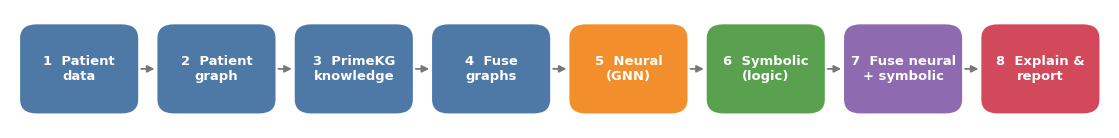

In [1]:
#@title ⚙️ Setup: imports and plotting style (everything here is preinstalled on Colab)
import math, random, warnings, textwrap
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Patch
import networkx as nx
import torch
import torch.nn as nn
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
SEED = 7
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 180)
plt.rcParams.update({
    "figure.dpi": 105, "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
})

# One colour per kind of node, used in every figure.
TYPE_COLORS = {"patient": "#1f4e79", "sample": "#6c8ebf", "gene": "#f28e2b", "partner": "#f7c58f",
               "pathway": "#59a14f", "drug": "#b07aa1", "disease": "#e15759"}
KIND_COLORS = {"clinical": "#4e79a7", "genomic": "#f28e2b", "kg_pathway": "#59a14f", "kg_drug": "#b07aa1", "kg_disease": "#e15759"}
RISK_RED, SAFE_GREEN, GREY = "#d1495b", "#2e933c", "#9a9a9a"

STEPS = ["1  Patient\ndata", "2  Patient\ngraph", "3  PrimeKG\nknowledge", "4  Fuse\ngraphs",
         "5  Neural\n(GNN)", "6  Symbolic\n(logic)", "7  Fuse neural\n+ symbolic", "8  Explain &\nreport"]
STEP_COLORS = ["#4e79a7", "#4e79a7", "#4e79a7", "#4e79a7", "#f28e2b", "#59a14f", "#8e6bb0", "#d1495b"]

def roadmap(current=None):
    # Draw the eight-step pipeline, highlighting the current step.
    fig, ax = plt.subplots(figsize=(13.5, 1.45))
    ax.set_xlim(0, len(STEPS)); ax.set_ylim(0, 1); ax.axis("off")
    for i, label in enumerate(STEPS):
        active = current is None or i + 1 == current
        done = current is not None and i + 1 < current
        face = STEP_COLORS[i] if active else ("#c9d6e3" if done else "#e6e6e6")
        ax.add_patch(FancyBboxPatch((i + 0.07, 0.12), 0.86, 0.76, boxstyle="round,pad=0.0,rounding_size=0.12",
                                    fc=face, ec="#333" if (current and active) else "none", lw=2))
        ax.text(i + 0.5, 0.5, label, ha="center", va="center", fontsize=9, fontweight="bold",
                color="white" if active else "#555")
        if i < len(STEPS) - 1:
            ax.annotate("", xy=(i + 1.07, 0.5), xytext=(i + 0.93, 0.5), arrowprops=dict(arrowstyle="-|>", color="#777", lw=1.2))
    if current:
        ax.set_title(f"You are here: step {current} of {len(STEPS)}", loc="left", fontsize=10.5)
    plt.show()

print("numpy", np.__version__, "| pandas", pd.__version__, "| networkx", nx.__version__, "| torch", torch.__version__)
roadmap()

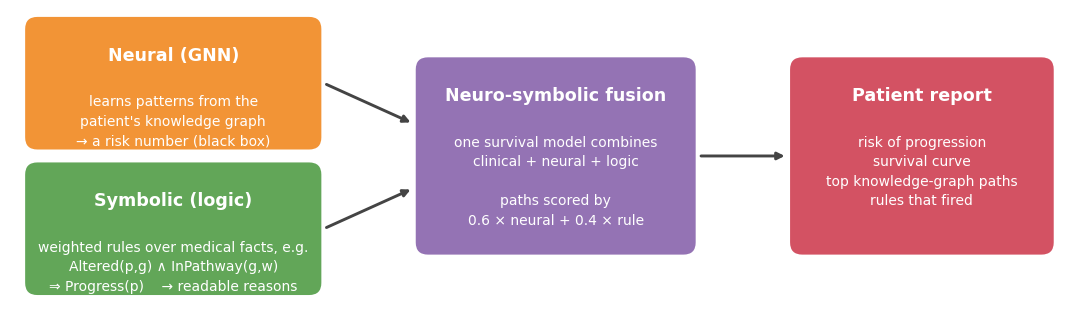

In [2]:
#@title 🎨 The idea in one picture
fig, ax = plt.subplots(figsize=(13, 3.6)); ax.axis("off"); ax.set_xlim(0, 13); ax.set_ylim(0, 3.6)
def _box(x, y, w, h, color, title, body):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.15", fc=color, ec="none", alpha=0.95))
    ax.text(x + w / 2, y + h - 0.35, title, ha="center", va="top", color="white", fontsize=12, fontweight="bold")
    ax.text(x + w / 2, y + h - 0.95, body, ha="center", va="top", color="white", fontsize=9.5, linespacing=1.5)
_box(0.2, 1.9, 3.6, 1.6, "#f28e2b", "Neural (GNN)", "learns patterns from the\npatient's knowledge graph\n→ a risk number (black box)")
_box(0.2, 0.1, 3.6, 1.6, "#59a14f", "Symbolic (logic)", "weighted rules over medical facts, e.g.\nAltered(p,g) ∧ InPathway(g,w)\n⇒ Progress(p)    → readable reasons")
_box(5.0, 0.6, 3.4, 2.4, "#8e6bb0", "Neuro-symbolic fusion", "one survival model combines\nclinical + neural + logic\n\npaths scored by\n0.6 × neural + 0.4 × rule")
_box(9.6, 0.6, 3.2, 2.4, "#d1495b", "Patient report", "risk of progression\nsurvival curve\ntop knowledge-graph paths\nrules that fired")
for (x0, y0), (x1, y1) in [((3.85, 2.7), (4.95, 2.2)), ((3.85, 0.9), (4.95, 1.4)), ((8.45, 1.8), (9.55, 1.8))]:
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", lw=2, color="#444"))
plt.show()

### 🧰 A small toolbox

The next cell defines a few statistics helpers used throughout. You can run it without reading it. In plain words:

* **Kaplan–Meier curve**: the share of patients still *progression-free* over time. It correctly handles patients whose follow-up ended early (*censored*).
* **Log-rank z**: how strongly a yes/no fact separates two survival curves. A large positive z means carriers progress *faster*, a large negative z means *slower*.
* **C-index** (concordance): of all pairs of patients we can compare, how often does the model give the higher risk to the one who progressed first? 0.5 = coin flip, 1.0 = perfect.
* **Cox model**: the standard survival regression. Each feature gets a weight; `exp(weight)` is a *hazard ratio*. We fit it with an elastic-net penalty, which pushes useless weights to exactly zero.

In [3]:
#@title 🧰 Toolbox: survival statistics helpers (run me, no need to read) { display-mode: "form" }

def km_curve(time, event):
    # Kaplan-Meier estimate of progression-free survival.
    time, event = np.asarray(time, float), np.asarray(event, int)
    grid = np.unique(time[event == 1])
    surv, s = [], 1.0
    for u in grid:
        at_risk = (time >= u).sum()
        d = ((time == u) & (event == 1)).sum()
        s *= 1 - d / at_risk
        surv.append(s)
    return np.r_[0.0, grid], np.r_[1.0, surv]

def logrank_z(time, event, groups):
    # Signed log-rank z for each column of `groups` (carriers vs the rest). Vectorised.
    time, event = np.asarray(time, float), np.asarray(event, float)
    G = np.asarray(groups, float)
    G = G[:, None] if G.ndim == 1 else G
    order = np.argsort(time, kind="stable")
    t, e, G = time[order], event[order], G[order]
    uniq, first, inverse = np.unique(t, return_index=True, return_inverse=True)
    n = len(t)
    at_risk = n - first
    cum = np.vstack([np.zeros(G.shape[1]), np.cumsum(G, 0)])
    at_risk_g = cum[-1] - cum[first]
    deaths = np.bincount(inverse, weights=e)
    deaths_g = np.zeros((len(uniq), G.shape[1])); np.add.at(deaths_g, inverse, G * e[:, None])
    keep = deaths > 0
    N, D, Ng, Dg = at_risk[keep][:, None], deaths[keep][:, None], at_risk_g[keep], deaths_g[keep]
    expected = Ng * D / N
    var = Ng / N * (1 - Ng / N) * (N - D) / np.maximum(N - 1, 1) * D
    with np.errstate(invalid="ignore", divide="ignore"):
        z = (Dg - expected).sum(0) / np.sqrt(var.sum(0))
    return np.nan_to_num(z)

def c_index(time, event, risk):
    # Harrell's concordance index.
    time, event, risk = np.asarray(time, float), np.asarray(event, int), np.asarray(risk, float)
    comparable = (time[:, None] < time[None, :]) & (event[:, None] == 1)
    concordant = (risk[:, None] > risk[None, :]) & comparable
    tied = (risk[:, None] == risk[None, :]) & comparable
    return (concordant.sum() + 0.5 * tied.sum()) / max(comparable.sum(), 1)

def make_folds(event, k=5, seed=SEED):
    # Stratified k-fold split: every fold gets the same share of progressions.
    rng = np.random.default_rng(seed)
    fold_of = np.zeros(len(event), int)
    for label in (0, 1):
        idx = rng.permutation(np.where(np.asarray(event) == label)[0])
        fold_of[idx] = np.arange(len(idx)) % k
    return [(np.where(fold_of != f)[0], np.where(fold_of == f)[0]) for f in range(k)], fold_of

class Standardizer:
    def fit(self, X):
        self.mean = X.mean(0); self.std = np.where(X.std(0) > 0, X.std(0), 1.0); return self
    def transform(self, X):
        return (X - self.mean) / self.std

def _cox_parts(time, event):
    order = np.argsort(-np.asarray(time, float), kind="stable")
    t = np.asarray(time, float)[order]
    # risk set of position i = every position j with t_j >= t_i = positions 0..end[i]
    end = np.searchsorted(-t, -t, side="right") - 1
    return order, np.asarray(event, float)[order], end

def _cox_loss_grad(w, X, e, end, n_events):
    eta = X @ w
    eta = eta - eta.max()
    ex = np.exp(eta)
    s0 = np.cumsum(ex)[end]
    s1 = np.cumsum(ex[:, None] * X, 0)[end]
    loss = -(e * (eta - np.log(s0))).sum() / n_events
    grad = -(e[:, None] * (X - s1 / s0[:, None])).sum(0) / n_events
    return loss, grad

def fit_cox(X, time, event, alpha=0.0, l1_ratio=0.5, ridge=1e-3, w0=None, iters=400):
    # Elastic-net Cox partial likelihood (Breslow), solved by FISTA proximal gradient.
    order, e, end = _cox_parts(time, event)
    Xs = np.asarray(X, float)[order]
    n_events = max(e.sum(), 1.0)
    l1, l2 = alpha * l1_ratio, alpha * (1 - l1_ratio) + ridge
    f = lambda v: _cox_loss_grad(v, Xs, e, end, n_events)
    w = np.zeros(Xs.shape[1]) if w0 is None else w0.copy()
    y, t_k, L = w.copy(), 1.0, 1.0
    for _ in range(iters):
        fy, gy = f(y)
        fy += 0.5 * l2 * y @ y; gy = gy + l2 * y
        while True:
            z = y - gy / L
            w_new = np.sign(z) * np.maximum(np.abs(z) - l1 / L, 0)
            d = w_new - y
            f_new = f(w_new)[0] + 0.5 * l2 * w_new @ w_new
            if f_new <= fy + gy @ d + 0.5 * L * d @ d + 1e-12 or L > 1e6:
                break
            L *= 2
        t_next = (1 + math.sqrt(1 + 4 * t_k * t_k)) / 2
        y = w_new + (t_k - 1) / t_next * (w_new - w)
        if np.abs(w_new - w).max() < 1e-5:
            w = w_new; break
        w, t_k = w_new, t_next
    return w

def fit_cox_cv(X, time, event, l1_ratio=0.5, n_alphas=6, inner=3, seed=SEED):
    # Choose the elastic-net strength by inner cross-validated C-index (this is the structure learning).
    order, e, end = _cox_parts(time, event)
    _, g0 = _cox_loss_grad(np.zeros(X.shape[1]), X[order], e, end, max(e.sum(), 1.0))
    alpha_max = np.abs(g0).max() / l1_ratio
    alphas = alpha_max * np.geomspace(0.8, 0.05, n_alphas)
    inner_folds, _ = make_folds(event, inner, seed)
    scores = np.zeros(n_alphas)
    for tr, va in inner_folds:
        w = None
        for a, alpha in enumerate(alphas):
            w = fit_cox(X[tr], time[tr], event[tr], alpha, l1_ratio, w0=w, iters=150)
            scores[a] += c_index(time[va], event[va], X[va] @ w)
    best = int(np.argmax(scores))
    w = None
    for alpha in alphas[: best + 1]:
        w = fit_cox(X, time, event, alpha, l1_ratio, w0=w, iters=200)
    return w, float(alphas[best])

def breslow_baseline(time, event, eta):
    # Cumulative baseline hazard H0(t) of a fitted Cox model.
    order = np.argsort(time)
    t, e, r = np.asarray(time)[order], np.asarray(event)[order], np.exp(np.asarray(eta)[order])
    at_risk = np.cumsum(r[::-1])[::-1]
    grid = t[e == 1]
    return grid, np.cumsum(1.0 / at_risk[e == 1])

print("Toolbox ready ✅")

Toolbox ready ✅


---
# Step 1 · Patient data 📋

In the real project the data come from **cBioPortal, TCGA BRCA PanCancer Atlas 2018**: 1,083 breast-cancer patients with

* a **clinical** table (age, tumour stage, lymph-node stage, molecular subtype, …),
* a **mutation** table in *MAF* format (one row per mutation: gene, Entrez id, protein change),
* a **copy-number (CNA)** table (`+2` = high-level amplification of a gene, `−2` = homozygous deletion),
* and the **outcome**: *progression-free survival* (`PFS_STATUS`, `PFS_MONTHS`).

Here we **simulate** 500 patients with exactly the same table layout, over a panel of 24 well-known breast-cancer genes (with their real NCBI Entrez ids).
The simulation cell is collapsed on purpose: it contains a *hidden mechanism* that decides who progresses. The rest of the notebook only sees the tables, like a real study would.

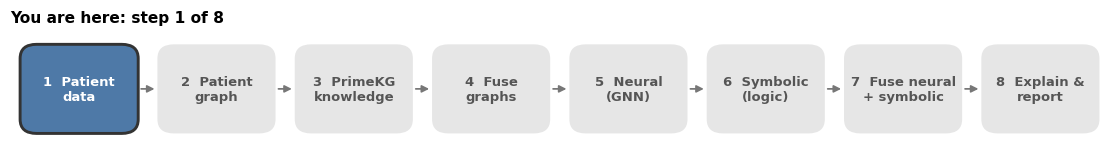

In [4]:
roadmap(1)

In [5]:
#@title 🔒 Simulate the toy cohort (contains the hidden mechanism: no peeking until Step 6!) { display-mode: "form" }
rng = np.random.default_rng(SEED)
N_PATIENTS = 500

# Gene panel: symbol -> NCBI Entrez gene id (real ids, the key PrimeKG uses for genes).
PANEL = {"TP53": 7157, "PIK3CA": 5290, "ERBB2": 2064, "ESR1": 2099, "GATA3": 2625, "CDH1": 999,
         "MAP3K1": 4214, "KMT2C": 58508, "PTEN": 5728, "AKT1": 207, "MTOR": 2475, "EGFR": 1956,
         "FGFR1": 2260, "MYC": 4609, "CCND1": 595, "CDK4": 1019, "RB1": 5925, "CDKN2A": 1029,
         "MDM2": 4193, "BRCA1": 672, "BRCA2": 675, "ATM": 472, "CHEK2": 11200, "PARP1": 142}
SUBTYPES = ["LumA", "LumB", "Her2", "Basal", "Normal"]
SUBTYPE_SHARE = [0.45, 0.20, 0.12, 0.18, 0.05]
# (gene, alteration kind, probability in LumA, LumB, Her2, Basal, Normal): loosely shaped like real BRCA.
ALTERATION_RATES = [
    ("TP53", "mut", (.12, .30, .55, .78, .15)), ("PIK3CA", "mut", (.45, .30, .35, .08, .35)),
    ("GATA3", "mut", (.15, .15, .05, .02, .10)), ("MAP3K1", "mut", (.13, .05, .03, .01, .08)),
    ("CDH1", "mut", (.18, .08, .05, .02, .10)), ("KMT2C", "mut", (.10, .10, .10, .08, .08)),
    ("PTEN", "mut", (.04, .04, .04, .08, .04)), ("PTEN", "del", (.02, .03, .03, .08, .02)),
    ("AKT1", "mut", (.05, .03, .01, .01, .03)), ("MTOR", "mut", (.02, .02, .02, .02, .02)),
    ("ESR1", "mut", (.03, .03, .00, .00, .01)), ("ERBB2", "amp", (.02, .12, .85, .03, .03)),
    ("EGFR", "amp", (.01, .02, .04, .07, .01)), ("FGFR1", "amp", (.06, .14, .06, .04, .04)),
    ("MYC", "amp", (.05, .12, .12, .30, .05)), ("CCND1", "amp", (.10, .30, .12, .04, .06)),
    ("CDK4", "amp", (.03, .06, .06, .02, .02)), ("MDM2", "amp", (.03, .06, .04, .02, .02)),
    ("RB1", "del", (.01, .03, .03, .12, .02)), ("CDKN2A", "del", (.02, .04, .03, .08, .02)),
    ("BRCA1", "mut", (.02, .02, .03, .20, .02)), ("BRCA2", "mut", (.03, .05, .03, .08, .03)),
    ("ATM", "mut", (.03, .04, .04, .06, .03)), ("CHEK2", "mut", (.02, .02, .02, .04, .02)),
    ("PARP1", "amp", (.02, .02, .02, .03, .02)),
]
HOTSPOTS = {"TP53": ["p.R175H", "p.R248Q", "p.R273H", "p.Y220C", "p.R213*"], "PIK3CA": ["p.H1047R", "p.E545K", "p.E542K"],
            "AKT1": ["p.E17K"], "ESR1": ["p.D538G", "p.Y537S"], "GATA3": ["p.D336fs", "p.M294K"], "CDH1": ["p.Q23*", "p.R63*"]}
AMINO = list("ACDEFGHIKLMNPQRSTVWY")

def _protein_change(gene):
    if gene in HOTSPOTS and rng.random() < 0.7:
        return str(rng.choice(HOTSPOTS[gene]))
    a, b = rng.choice(AMINO, 2, replace=False)
    pos = int(rng.integers(20, 900))
    return f"p.{a}{pos}{b}" if rng.random() < 0.75 else f"p.{a}{pos}*"

def _ajcc(t, n):
    if t == "T4" or n in ("N2", "N3"): return "STAGE III"
    if t in ("T2", "T3") or n == "N1": return "STAGE II"
    return "STAGE I"

patient_ids = [f"TOY-{i:04d}" for i in range(1, N_PATIENTS + 1)]
subtype = rng.choice(SUBTYPES, N_PATIENTS, p=SUBTYPE_SHARE)
age = np.clip(rng.normal(58, 13, N_PATIENTS), 26, 90).round().astype(int)
t_stage = rng.choice(["T1", "T2", "T3", "T4"], N_PATIENTS, p=[0.30, 0.53, 0.13, 0.04])
n_stage = rng.choice(["N0", "N1", "N2", "N3"], N_PATIENTS, p=[0.48, 0.32, 0.12, 0.08])

mutation_rows, cna_rows, _altered = [], [], {}
for i, pid in enumerate(patient_ids):
    s, sample = SUBTYPES.index(subtype[i]), f"{pid}-01"
    _altered[pid] = set()
    for gene, kind, rates in ALTERATION_RATES:
        if rng.random() >= rates[s]:
            continue
        _altered[pid].add(gene)
        if kind == "mut":
            change = _protein_change(gene)
            vc = "Nonsense_Mutation" if change.endswith("*") else "Frame_Shift_Del" if "fs" in change else "Missense_Mutation"
            mutation_rows.append({"Hugo_Symbol": gene, "Entrez_Gene_Id": PANEL[gene], "Tumor_Sample_Barcode": sample,
                                  "Variant_Classification": vc, "HGVSp_Short": change})
        else:
            cna_rows.append({"Hugo_Symbol": gene, "Entrez_Gene_Id": PANEL[gene], "SAMPLE_ID": sample,
                             "CNA_VALUE": 2 if kind == "amp" else -2})

# ---------------- the hidden mechanism ("nature") ----------------
_cell_cycle = np.array([bool(_altered[p] & {"CCND1", "CDK4", "RB1", "CDKN2A", "MYC"}) for p in patient_ids])
_dna_repair = np.array([bool(_altered[p] & {"BRCA1", "BRCA2", "ATM", "CHEK2", "PARP1"}) for p in patient_ids])
_log_hazard = (0.5 * (n_stage == "N1") + 0.9 * (n_stage == "N2") + 1.3 * (n_stage == "N3")
               + 0.4 * np.isin(t_stage, ["T3", "T4"]) + 0.3 * (age >= 70) - 0.4 * (subtype == "LumA")
               + 1.1 * _cell_cycle + 1.2 * ((subtype == "Basal") & _dna_repair))
_event_time = rng.exponential(1.0, N_PATIENTS) / (np.exp(_log_hazard) / 260.0)
_censor_time = rng.uniform(12, 140, N_PATIENTS)
HIDDEN_TRUTH = pd.DataFrame([
    ("NStage(p, N1)", +0.5, "clinical"), ("NStage(p, N2)", +0.9, "clinical"), ("NStage(p, N3)", +1.3, "clinical"),
    ("TStage(p, T3 or T4)", +0.4, "clinical"), ("Age(p) ≥ 70", +0.3, "clinical"), ("Subtype(p, LumA)", -0.4, "clinical"),
    ("Altered(p, g) ∧ InPathway(g, 'Cell cycle G1/S')", +1.1, "PrimeKG pathway"),
    ("Subtype(p, Basal) ∧ Altered(p, g) ∧ InPathway(g, 'DNA double-strand break repair')", +1.2, "clinical × PrimeKG"),
], columns=["hidden rule", "true log-hazard effect", "kind"])

# ---------------- cBioPortal-style tables ----------------
clinical_patient = pd.DataFrame({
    "PATIENT_ID": patient_ids, "AGE": age, "SUBTYPE": ["BRCA_" + s for s in subtype],
    "PATH_T_STAGE": t_stage, "PATH_N_STAGE": n_stage,
    "AJCC_PATHOLOGIC_TUMOR_STAGE": [_ajcc(t, n) for t, n in zip(t_stage, n_stage)],
    "PFS_STATUS": np.where(_event_time <= _censor_time, "1:PROGRESSION", "0:CENSORED"),
    "PFS_MONTHS": np.round(np.minimum(_event_time, _censor_time), 1).clip(0.5),
})
clinical_sample = pd.DataFrame({"SAMPLE_ID": [f"{p}-01" for p in patient_ids], "PATIENT_ID": patient_ids, "SAMPLE_TYPE": "Primary"})
mutations = pd.DataFrame(mutation_rows)
cna = pd.DataFrame(cna_rows)

# Throw the hidden variables away: the pipeline below can only use the four tables.
del _altered, _cell_cycle, _dna_repair, _log_hazard, _event_time, _censor_time
print(f"Simulated {N_PATIENTS} patients · {len(mutations)} mutation rows · {len(cna)} copy-number rows · "
      f"{(clinical_patient.PFS_STATUS == '1:PROGRESSION').sum()} recorded progressions")

Simulated 500 patients · 699 mutation rows · 338 copy-number rows · 210 recorded progressions


In [6]:
print("📋 Clinical table (one row per patient)"); display(clinical_patient.head(5))
print("🧬 Mutation table, MAF format (one row per mutation)"); display(mutations.head(5))
print("📈 Copy-number table (+2 = high-level amplification, −2 = homozygous deletion)"); display(cna.head(5))

📋 Clinical table (one row per patient)


,PATIENT_ID,AGE,SUBTYPE,PATH_T_STAGE,PATH_N_STAGE,AJCC_PATHOLOGIC_TUMOR_STAGE,PFS_STATUS,PFS_MONTHS
0,TOY-0001,68,BRCA_LumB,T2,N0,STAGE II,1:PROGRESSION,27.3
1,TOY-0002,69,BRCA_Basal,T3,N0,STAGE II,1:PROGRESSION,42.1
2,TOY-0003,46,BRCA_Basal,T1,N2,STAGE III,1:PROGRESSION,27.2
3,TOY-0004,40,BRCA_LumA,T1,N3,STAGE III,0:CENSORED,19.7
4,TOY-0005,53,BRCA_LumA,T1,N1,STAGE II,1:PROGRESSION,94.9


🧬 Mutation table, MAF format (one row per mutation)


,Hugo_Symbol,Entrez_Gene_Id,Tumor_Sample_Barcode,Variant_Classification,HGVSp_Short
0,TP53,7157,TOY-0001-01,Missense_Mutation,p.R248Q
1,MAP3K1,4214,TOY-0001-01,Nonsense_Mutation,p.R435*
2,PIK3CA,5290,TOY-0002-01,Missense_Mutation,p.I804H
3,PTEN,5728,TOY-0002-01,Missense_Mutation,p.M262G
4,TP53,7157,TOY-0003-01,Missense_Mutation,p.Y220C


📈 Copy-number table (+2 = high-level amplification, −2 = homozygous deletion)


,Hugo_Symbol,Entrez_Gene_Id,SAMPLE_ID,CNA_VALUE
0,FGFR1,2260,TOY-0001-01,2
1,CCND1,595,TOY-0001-01,2
2,RB1,5925,TOY-0001-01,-2
3,PTEN,5728,TOY-0002-01,-2
4,MYC,4609,TOY-0002-01,2


### 🚧 Leakage guard

The outcome columns (`PFS_STATUS`, `PFS_MONTHS`) are what we want to predict, so they must **never** enter the patient graph or the facts the models read.
We split them off into a separate `outcome` table and assert that they are gone. The real project does the same with `assert_no_outcome_leakage`.

In [7]:
OUTCOME_FIELDS = ["PFS_STATUS", "PFS_MONTHS"]
clinical = clinical_patient.drop(columns=OUTCOME_FIELDS).set_index("PATIENT_ID")
clinical["SUBTYPE"] = clinical["SUBTYPE"].str.replace("BRCA_", "", regex=False)
outcome = pd.DataFrame({"time": clinical_patient["PFS_MONTHS"].to_numpy(),
                        "event": clinical_patient["PFS_STATUS"].str.startswith("1").astype(int).to_numpy()},
                       index=clinical_patient["PATIENT_ID"])
assert not set(OUTCOME_FIELDS) & set(clinical.columns), "outcome leaked into the evidence!"

# One long table of alterations: patient, sample, gene, Entrez id, kind, detail.
sample_to_patient = dict(zip(clinical_sample.SAMPLE_ID, clinical_sample.PATIENT_ID))
alterations = pd.concat([
    pd.DataFrame({"patient_id": mutations.Tumor_Sample_Barcode.map(sample_to_patient), "sample_id": mutations.Tumor_Sample_Barcode,
                  "gene": mutations.Hugo_Symbol, "entrez": mutations.Entrez_Gene_Id, "kind": "mut", "detail": mutations.HGVSp_Short}),
    pd.DataFrame({"patient_id": cna.SAMPLE_ID.map(sample_to_patient), "sample_id": cna.SAMPLE_ID, "gene": cna.Hugo_Symbol,
                  "entrez": cna.Entrez_Gene_Id, "kind": np.where(cna.CNA_VALUE > 0, "amp", "del"),
                  "detail": np.where(cna.CNA_VALUE > 0, "high-level amplification (+2)", "homozygous deletion (−2)")}),
], ignore_index=True)

PIDS = list(clinical.index)
TIME = outcome["time"].to_numpy(float)
EVENT = outcome["event"].to_numpy(int)
print("✅ No outcome column in the evidence tables.")
print(f"{len(PIDS)} patients, {EVENT.sum()} progressions ({EVENT.mean():.0%}), median follow-up {np.median(TIME):.0f} months")
print(f"{len(alterations)} alterations, {alterations.groupby('patient_id').size().mean():.1f} per patient on average")

✅ No outcome column in the evidence tables.
500 patients, 210 progressions (42%), median follow-up 46 months
1037 alterations, 2.3 per patient on average


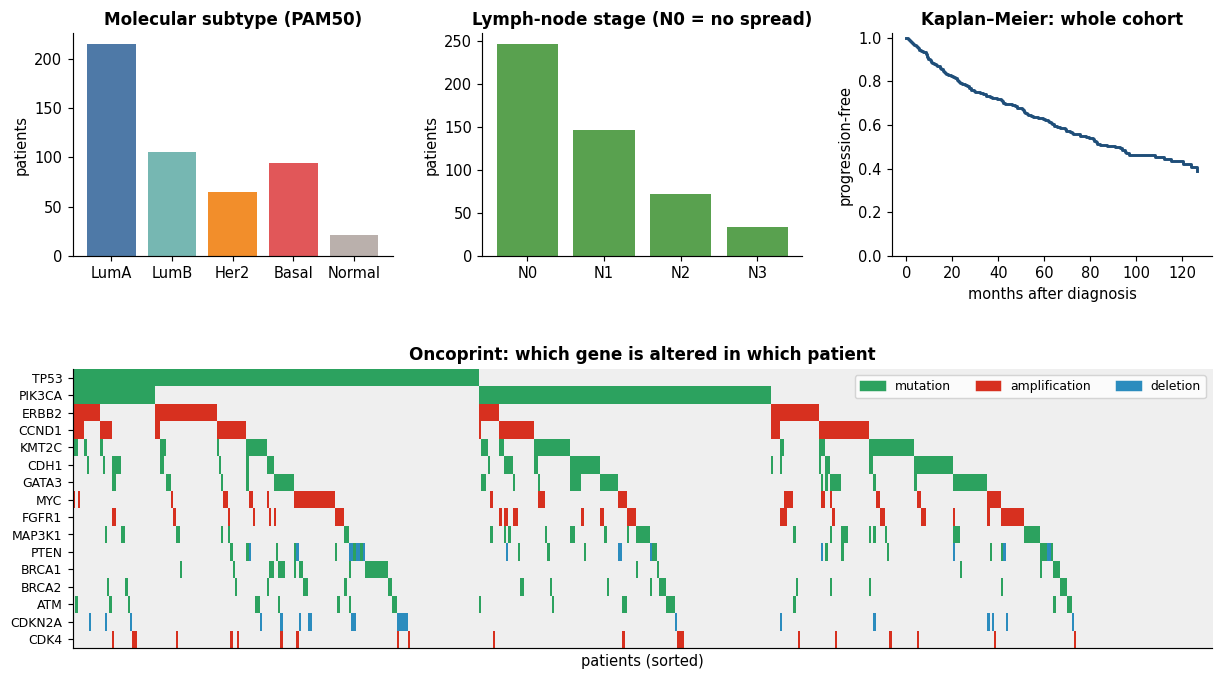

In [8]:
#@title 📊 A first look at the cohort
fig = plt.figure(figsize=(14, 7.6))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.25], hspace=0.45, wspace=0.28)

ax = fig.add_subplot(gs[0, 0])
counts = clinical.SUBTYPE.value_counts().reindex(SUBTYPES)
ax.bar(counts.index, counts.values, color=["#4e79a7", "#76b7b2", "#f28e2b", "#e15759", "#bab0ac"])
ax.set_title("Molecular subtype (PAM50)"); ax.set_ylabel("patients")

ax = fig.add_subplot(gs[0, 1])
counts = clinical.PATH_N_STAGE.value_counts().sort_index()
ax.bar(counts.index, counts.values, color="#59a14f")
ax.set_title("Lymph-node stage (N0 = no spread)"); ax.set_ylabel("patients")

ax = fig.add_subplot(gs[0, 2])
t, s = km_curve(TIME, EVENT)
ax.step(t, s, where="post", color="#1f4e79", lw=2)
ax.set_ylim(0, 1.02); ax.set_xlabel("months after diagnosis"); ax.set_ylabel("progression-free")
ax.set_title("Kaplan–Meier: whole cohort")

ax = fig.add_subplot(gs[1, :])
genes = alterations.gene.value_counts().index[:16]
g_index = {g: i for i, g in enumerate(genes)}; p_index = {p: i for i, p in enumerate(PIDS)}
M = np.zeros((len(genes), len(PIDS)))
for r in alterations.itertuples():
    if r.gene in g_index:
        M[g_index[r.gene], p_index[r.patient_id]] = {"mut": 1, "amp": 2, "del": 3}[r.kind]
order = np.lexsort((M > 0)[::-1])[::-1]
ax.imshow(M[:, order], aspect="auto", interpolation="nearest", cmap=ListedColormap(["#efefef", "#2ca25f", "#d7301f", "#2b8cbe"]), vmin=0, vmax=3)
ax.set_yticks(range(len(genes))); ax.set_yticklabels(genes, fontsize=8.5); ax.set_xticks([])
ax.set_xlabel("patients (sorted)"); ax.set_title("Oncoprint: which gene is altered in which patient")
ax.legend(handles=[Patch(color="#2ca25f", label="mutation"), Patch(color="#d7301f", label="amplification"), Patch(color="#2b8cbe", label="deletion")],
          loc="upper right", ncol=3, fontsize=8.5, frameon=True)
plt.show()

**What you are seeing.** Each column of the oncoprint is a patient and each row a gene. Some genes are altered in many patients (TP53, PIK3CA), most in only a few.
That sparsity is the real difficulty: a single rare gene rarely carries enough statistical signal by itself. **Biomedical knowledge can group rare genes into pathways**, which is the motivation for PrimeKG (Step 3).

---
# Step 2 · From tables to a patient graph 🕸️

Every patient becomes a small **graph**: nodes are things (the patient, their tumour sample, each altered gene) and edges are typed relations between them.

```
Patient ──has_sample──▶ Sample ──has_mutation──────────────────▶ Gene (TP53)
                               ──has_high_level_amplification──▶ Gene (MYC)
                               ──has_homozygous_deletion───────▶ Gene (RB1)
```

The clinical facts (age, stage, subtype) are stored *on* the patient node. Gene nodes are keyed by their **Entrez id**, which is what lets us join them to PrimeKG in Step 4.
The real project writes these graphs as NetworkX `MultiDiGraph`s (multi = a gene can be both mutated and deleted, i.e. two parallel edges).

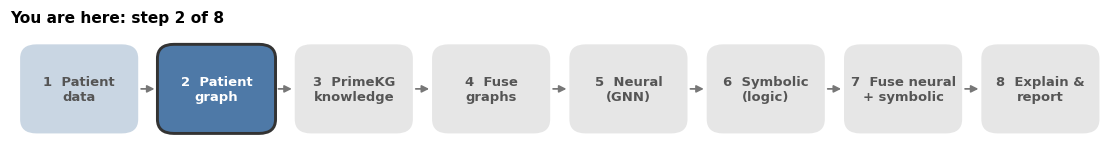

In [9]:
roadmap(2)

In [10]:
RELATION_OF = {"mut": "has_mutation", "amp": "has_high_level_amplification", "del": "has_homozygous_deletion"}
ALT_BY_PATIENT = {pid: rows for pid, rows in alterations.groupby("patient_id")}
GENE_SYMBOL = {v: k for k, v in PANEL.items()}

def patient_graph(pid, clinical_row=None, alteration_rows=None):
    # Patient -> Sample -> altered Gene, with the clinical record on the patient node.
    row = clinical.loc[pid] if clinical_row is None else clinical_row
    rows = ALT_BY_PATIENT.get(pid, alterations.iloc[:0]) if alteration_rows is None else alteration_rows
    G = nx.MultiDiGraph()
    p, s = f"patient:{pid}", f"sample:{pid}-01"
    G.add_node(p, type="patient", label=pid, age=int(row.AGE), subtype=row.SUBTYPE,
               t_stage=row.PATH_T_STAGE, n_stage=row.PATH_N_STAGE)
    G.add_node(s, type="sample", label="tumour sample")
    G.add_edge(p, s, relation="has_sample")
    for r in rows.itertuples():
        g = f"gene:{int(r.entrez)}"
        if g not in G:
            G.add_node(g, type="gene", label=r.gene, entrez=int(r.entrez), altered=True, mut=0, amp=0, dele=0)
        G.nodes[g][{"mut": "mut", "amp": "amp", "del": "dele"}[r.kind]] = 1
        G.add_edge(s, g, relation=RELATION_OF[r.kind], detail=r.detail)
    return G

# Pick an interesting demo patient: basal subtype, a few alterations of different kinds, and a recorded progression.
def _pick_demo():
    for pid in PIDS:
        rows = ALT_BY_PATIENT.get(pid)
        if rows is None or clinical.loc[pid, "SUBTYPE"] != "Basal" or outcome.loc[pid, "event"] != 1:
            continue
        genes = set(rows.gene)
        if 4 <= len(genes) <= 6 and genes & {"MYC", "CCND1", "CDK4", "RB1", "CDKN2A"} and genes & {"BRCA1", "BRCA2", "ATM", "CHEK2"} and set(rows.kind) >= {"mut", "amp"}:
            return pid
    return max(PIDS, key=lambda p: len(ALT_BY_PATIENT.get(p, [])))

DEMO = _pick_demo()
G_demo = patient_graph(DEMO)
print(f"Demo patient: {DEMO}  ·  {G_demo.number_of_nodes()} nodes, {G_demo.number_of_edges()} edges")
print("Clinical record on the patient node:", {k: v for k, v in G_demo.nodes[f'patient:{DEMO}'].items() if k not in ('type', 'label')})
display(pd.DataFrame([(G_demo.nodes[u]["label"], d["relation"], G_demo.nodes[v]["label"], d.get("detail", ""))
                      for u, v, d in G_demo.edges(data=True)], columns=["head", "relation", "tail", "detail"]))

Demo patient: TOY-0162  ·  7 nodes, 6 edges
Clinical record on the patient node: {'age': 72, 'subtype': 'Basal', 't_stage': 'T1', 'n_stage': 'N1'}


,head,relation,tail,detail
0,TOY-0162,has_sample,tumour sample,
1,tumour sample,has_mutation,TP53,p.R273H
2,tumour sample,has_mutation,PTEN,p.E279V
3,tumour sample,has_mutation,BRCA1,p.A347*
4,tumour sample,has_high_level_amplification,MYC,high-level amplification (+2)
5,tumour sample,has_homozygous_deletion,RB1,homozygous deletion (−2)


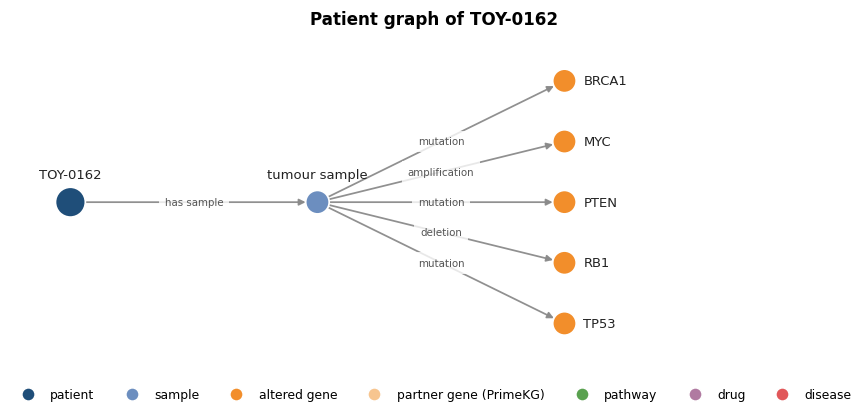

In [11]:
#@title 🖌️ Graph drawing helpers { display-mode: "form" }
SHORT_REL = {"has_sample": "has sample", "has_mutation": "mutation", "has_high_level_amplification": "amplification",
             "has_homozygous_deletion": "deletion", "protein_protein": "interacts", "pathway_protein": "in pathway",
             "drug_protein": "drug target", "disease_protein": "linked disease"}
TYPE_RANK = {"patient": 0, "sample": 1, "gene": 2, "pathway": 3, "drug": 4, "disease": 5}

def node_color(d):
    return TYPE_COLORS["partner"] if d["type"] == "gene" and not d.get("altered", True) else TYPE_COLORS[d["type"]]

def layered_layout(G):
    # Columns: patient | sample | altered genes | partner genes | pathways, drugs, diseases.
    has_partners = any(d["type"] == "gene" and not d.get("altered", True) for _, d in G.nodes(data=True))
    def column(d):
        if d["type"] in ("patient", "sample"):
            return TYPE_RANK[d["type"]]
        if d["type"] == "gene":
            return 2 if d.get("altered", True) else 3
        return 4 if has_partners else 3
    columns = defaultdict(list)
    for n, d in G.nodes(data=True):
        columns[column(d)].append(n)
    pos = {}
    for c in sorted(columns):
        nodes = columns[c]
        # order each column by the average height of its already-placed neighbours (fewer crossings)
        height = lambda n: np.mean([pos[m][1] for m in nx.all_neighbors(G, n) if m in pos] or [0.0])
        nodes.sort(key=lambda n: (TYPE_RANK[G.nodes[n]["type"]], -height(n), G.nodes[n]["label"]) if c > 2 else G.nodes[n]["label"])
        for i, n in enumerate(nodes):
            pos[n] = (c * 1.7, (len(nodes) - 1) / 2 - i)
    return pos

def draw_graph(G, ax, title="", pos=None, edge_strength=None, highlight=(), edge_labels=False, font=8, faded=()):
    pos = pos or layered_layout(G)
    simple = nx.DiGraph()
    simple.add_nodes_from(G.nodes(data=True))
    for u, v, d in G.edges(data=True):
        simple.add_edge(u, v, relation=d["relation"])
    edges = list(simple.edges())
    hl = set(highlight)
    widths = [0.5 + 6.0 * edge_strength.get((u, v), 0) ** 2 if edge_strength else 1.2 for u, v in edges]
    colors = [RISK_RED if (u, v) in hl else "#8a8a8a" for u, v in edges]
    alphas = [0.95 if (u, v) in hl or not hl else 0.35 for u, v in edges]
    for (u, v), w, c, a in zip(edges, widths, colors, alphas):
        same_column = abs(pos[u][0] - pos[v][0]) < 1e-9          # e.g. two altered genes that interact: draw curved
        nx.draw_networkx_edges(simple, pos, edgelist=[(u, v)], ax=ax, width=w + (1.5 if (u, v) in hl else 0), edge_color=c,
                               alpha=a, arrows=True, arrowsize=9, node_size=260,
                               connectionstyle="arc3,rad=0.45" if same_column else "arc3")
    nodes = list(simple.nodes())
    nx.draw_networkx_nodes(simple, pos, nodelist=nodes, ax=ax, node_size=[420 if simple.nodes[n]["type"] == "patient" else 260 for n in nodes],
                           node_color=[node_color(simple.nodes[n]) for n in nodes], edgecolors="white", linewidths=1.2,
                           alpha=[0.25 if n in faded else 1.0 for n in nodes])
    for n in nodes:
        x, y = pos[n]
        if simple.nodes[n]["type"] in ("patient", "sample"):      # label above, clear of the outgoing edges
            ax.text(x, y + 0.35, simple.nodes[n]["label"], fontsize=font, va="bottom", ha="center", color="#bbbbbb" if n in faded else "#222")
        else:
            ax.text(x + 0.13, y, simple.nodes[n]["label"], fontsize=font, va="center", ha="left", color="#bbbbbb" if n in faded else "#222")
    if edge_labels:
        nx.draw_networkx_edge_labels(simple, pos, {(u, v): SHORT_REL[simple.edges[u, v]["relation"]] for u, v in edges},
                                     ax=ax, font_size=7, font_color="#555", rotate=False, bbox=dict(fc="white", ec="none", alpha=0.8))
    xs = [p[0] for p in pos.values()]; ys = [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 0.3, max(xs) + 1.9); ax.set_ylim(min(ys) - 0.8, max(ys) + 0.8)
    ax.set_title(title); ax.axis("off")

def type_legend(ax, extra=()):
    handles = [Line2D([], [], marker="o", ls="", ms=9, mfc=TYPE_COLORS[t], mec="white", label=lbl) for t, lbl in
               [("patient", "patient"), ("sample", "sample"), ("gene", "altered gene"), ("partner", "partner gene (PrimeKG)"),
                ("pathway", "pathway"), ("drug", "drug"), ("disease", "disease")]]
    ax.legend(handles=list(handles) + list(extra), loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=8, fontsize=8.5, frameon=False)

fig, ax = plt.subplots(figsize=(10, 4.2))
draw_graph(G_demo, ax, title=f"Patient graph of {DEMO}", edge_labels=True, font=9)
type_legend(ax); plt.show()

**What you are seeing.** The patient's whole molecular record as a graph. On its own it only says *which* genes are broken.
It says nothing about *what those genes do*: which pathways they belong to, which drugs target them, which diseases they are linked to. That knowledge lives in PrimeKG.

---
# Step 3 · PrimeKG: the biomedical knowledge graph 📚

**PrimeKG** (Precision Medicine Knowledge Graph, Chandak et al., *Scientific Data* 2023) merges 20 curated biomedical resources into one graph of **129,375 nodes and about 8.1 million edges**: genes/proteins, pathways, drugs, diseases, phenotypes, …
Every row of PrimeKG is a triple: `x —relation→ y`. Genes are identified by their **NCBI Entrez id**.

The real project streams all of PrimeKG once and keeps a **4,570-edge slice** around its 500-gene panel, with four relations:
`protein_protein` (physical interaction), `pathway_protein`, `drug_protein` (drug target) and `disease_protein` (breast/mammary diseases).

Here we hard-code a **mini PrimeKG** of the same shape around our 24 genes. The pathway/drug/disease memberships follow real biology in simplified form, and the pathway, drug and disease ids are made up.

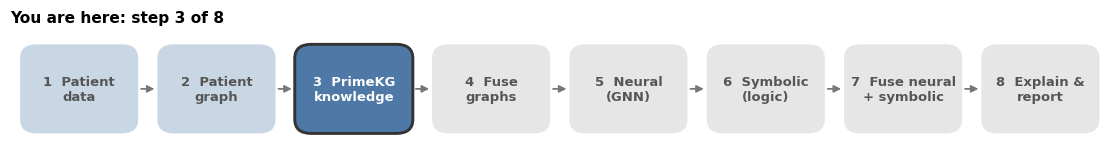

In [12]:
roadmap(3)

In [13]:
PATHWAYS = {
    "PI3K-Akt signaling": ["PIK3CA", "PTEN", "AKT1", "MTOR", "ERBB2", "EGFR", "FGFR1"],
    "p53 signaling": ["TP53", "MDM2", "CDKN2A", "ATM", "CHEK2"],
    "Cell cycle G1/S": ["CCND1", "CDK4", "RB1", "CDKN2A", "MYC"],
    "DNA double-strand break repair": ["BRCA1", "BRCA2", "ATM", "CHEK2", "PARP1"],
    "ERBB2 signaling": ["ERBB2", "EGFR", "PIK3CA"],
    "Estrogen receptor signaling": ["ESR1", "GATA3", "CCND1"],
    "MAPK signaling": ["MAP3K1", "EGFR", "FGFR1", "MYC"],
    "Adherens junction": ["CDH1"],
    "Chromatin modification": ["KMT2C"],
}
DRUGS = {"Trastuzumab": ["ERBB2"], "Lapatinib": ["ERBB2", "EGFR"], "Alpelisib": ["PIK3CA"], "Capivasertib": ["AKT1"],
         "Everolimus": ["MTOR"], "Palbociclib": ["CDK4"], "Olaparib": ["PARP1"], "Tamoxifen": ["ESR1"],
         "Fulvestrant": ["ESR1"], "Erdafitinib": ["FGFR1"]}
DISEASES = {"breast carcinoma": ["TP53", "PIK3CA", "ERBB2", "BRCA1", "BRCA2", "CDH1", "GATA3", "ESR1", "PTEN", "MAP3K1"],
            "hereditary breast-ovarian cancer": ["BRCA1", "BRCA2", "CHEK2", "ATM"],
            "lobular breast carcinoma": ["CDH1"], "Li-Fraumeni syndrome": ["TP53", "CHEK2"]}
PPI = [("TP53", "MDM2"), ("TP53", "ATM"), ("TP53", "CHEK2"), ("TP53", "BRCA1"), ("BRCA1", "BRCA2"), ("BRCA1", "PARP1"),
       ("ATM", "CHEK2"), ("PIK3CA", "AKT1"), ("AKT1", "MTOR"), ("PTEN", "AKT1"), ("ERBB2", "EGFR"), ("ERBB2", "PIK3CA"),
       ("FGFR1", "PIK3CA"), ("ESR1", "GATA3"), ("ESR1", "CCND1"), ("CCND1", "CDK4"), ("CDK4", "RB1"), ("CDKN2A", "CDK4"),
       ("MYC", "CCND1"), ("MDM2", "CDKN2A"), ("MAP3K1", "MYC"), ("CDH1", "EGFR"), ("KMT2C", "ESR1")]

rows = [dict(relation="protein_protein", display_relation="ppi", x_id=PANEL[a], x_type="gene/protein", x_name=a,
             y_id=PANEL[b], y_type="gene/protein", y_name=b) for a, b in PPI]
for prefix, table, kind, rel, disp in (("PW", PATHWAYS, "pathway", "pathway_protein", "interacts with"),
                                       ("DR", DRUGS, "drug", "drug_protein", "target"),
                                       ("DS", DISEASES, "disease", "disease_protein", "associated with")):
    for i, (name, genes) in enumerate(table.items(), 1):
        for g in genes:
            rows.append(dict(relation=rel, display_relation=disp, x_id=f"{prefix}{i:02d}", x_type=kind, x_name=name,
                             y_id=PANEL[g], y_type="gene/protein", y_name=g))
primekg = pd.DataFrame(rows)

# Gene-indexed lookup: Entrez id -> every PrimeKG neighbour of that gene.
KG_NEIGHBOURS = defaultdict(list)
KG_NODE_GENES = {}            # pathway/drug/disease node id -> set of member gene symbols
KG_NODE_NAME = {}
for r in primekg.itertuples():
    if r.relation == "protein_protein":
        KG_NEIGHBOURS[r.x_id].append(dict(relation=r.relation, node=f"gene:{r.y_id}", type="gene", name=r.y_name, entrez=r.y_id))
        KG_NEIGHBOURS[r.y_id].append(dict(relation=r.relation, node=f"gene:{r.x_id}", type="gene", name=r.x_name, entrez=r.x_id))
    else:
        node = f"{r.x_type}:{r.x_id}"
        KG_NEIGHBOURS[r.y_id].append(dict(relation=r.relation, node=node, type=r.x_type, name=r.x_name))
        KG_NODE_GENES.setdefault(node, set()).add(r.y_name)
        KG_NODE_NAME[node] = r.x_name

print(f"Mini PrimeKG: {len(primekg)} edges")
display(primekg.groupby(["relation", "display_relation"]).size().rename("edges").to_frame())
display(primekg.sample(6, random_state=1))

Mini PrimeKG: 85 edges


,,edges
relation,display_relation,
disease_protein,associated with,17
drug_protein,target,11
pathway_protein,interacts with,34
protein_protein,ppi,23


,relation,display_relation,x_id,x_type,x_name,y_id,y_type,y_name
38,pathway_protein,interacts with,PW03,pathway,Cell cycle G1/S,1029,gene/protein,CDKN2A
44,pathway_protein,interacts with,PW04,pathway,DNA double-strand break repair,142,gene/protein,PARP1
27,pathway_protein,interacts with,PW01,pathway,PI3K-Akt signaling,2064,gene/protein,ERBB2
40,pathway_protein,interacts with,PW04,pathway,DNA double-strand break repair,672,gene/protein,BRCA1
36,pathway_protein,interacts with,PW03,pathway,Cell cycle G1/S,1019,gene/protein,CDK4
80,disease_protein,associated with,DS02,disease,hereditary breast-ovarian cancer,11200,gene/protein,CHEK2


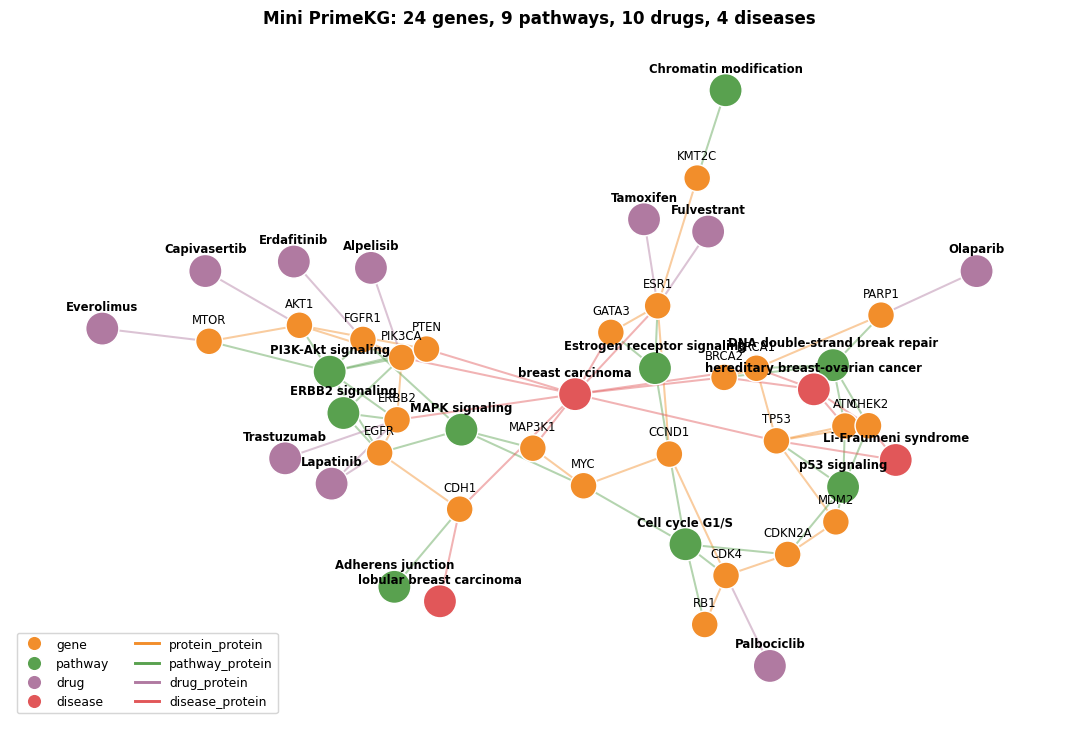

In [14]:
#@title 🗺️ Draw the whole mini PrimeKG
K = nx.Graph()
for r in primekg.itertuples():
    xa = f"gene:{r.x_id}" if r.x_type == "gene/protein" else f"{r.x_type}:{r.x_id}"
    K.add_node(xa, type="gene" if r.x_type == "gene/protein" else r.x_type, label=r.x_name)
    K.add_node(f"gene:{r.y_id}", type="gene", label=r.y_name)
    K.add_edge(xa, f"gene:{r.y_id}", relation=r.relation)
pos = nx.spring_layout(K, seed=4, k=0.55, iterations=200)
fig, ax = plt.subplots(figsize=(13, 8.5))
edge_col = {"protein_protein": "#f28e2b", "pathway_protein": "#59a14f", "drug_protein": "#b07aa1", "disease_protein": "#e15759"}
for rel, col in edge_col.items():
    nx.draw_networkx_edges(K, pos, edgelist=[(u, v) for u, v, d in K.edges(data=True) if d["relation"] == rel], ax=ax, edge_color=col, alpha=0.45, width=1.4)
nx.draw_networkx_nodes(K, pos, ax=ax, node_color=[TYPE_COLORS[K.nodes[n]["type"]] for n in K], node_size=[340 if K.nodes[n]["type"] == "gene" else 520 for n in K],
                       edgecolors="white")
for n, (x, y) in pos.items():
    ax.text(x, y + 0.045, K.nodes[n]["label"], ha="center", fontsize=8, fontweight="bold" if K.nodes[n]["type"] != "gene" else "normal")
ax.legend(handles=[Line2D([], [], marker="o", ls="", ms=10, mfc=TYPE_COLORS[t], mec="white", label=t) for t in ("gene", "pathway", "drug", "disease")]
                  + [Line2D([], [], color=c, lw=2, label=r) for r, c in edge_col.items()], loc="lower left", fontsize=8.5, ncol=2)
ax.set_title("Mini PrimeKG: 24 genes, 9 pathways, 10 drugs, 4 diseases"); ax.axis("off"); plt.show()

---
# Step 4 · Fusing each patient graph with PrimeKG 🔗

**Fusion** = for every altered gene in the patient graph, look the gene up in PrimeKG **by its Entrez id** and copy its knowledge into the patient's graph:

* **hop 1**: the altered gene's pathways, drug targets and linked diseases;
* **hop 2**: the altered gene's interaction partners (*partner genes*, which are not altered in this patient), and their pathways, drugs and diseases.

The project uses **2 hops** (`fixed_hops: 2` in `config/features.yaml`). Going further pulls in most of PrimeKG and drowns the patient's own facts.
First, the join itself, as a table:

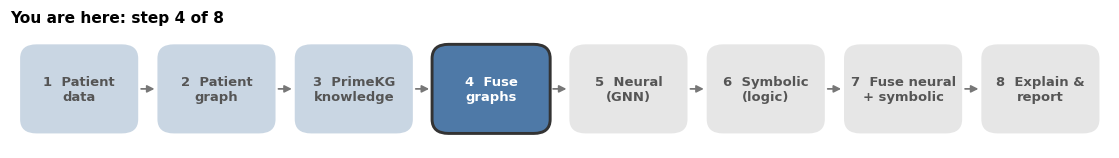

In [15]:
roadmap(4)

In [16]:
demo_alt = alterations[alterations.patient_id == DEMO][["gene", "entrez", "kind"]]
joined = demo_alt.merge(primekg, left_on="entrez", right_on="y_id")[["gene", "entrez", "kind", "relation", "x_type", "x_name"]]
joined = joined.rename(columns={"x_type": "PrimeKG node type", "x_name": "PrimeKG node"})
print(f"{DEMO}: {len(demo_alt)} altered genes joined to {len(joined)} PrimeKG facts on Entrez id (first 12 shown)")
display(joined.head(12))

TOY-0162: 5 altered genes joined to 14 PrimeKG facts on Entrez id (first 12 shown)


,gene,entrez,kind,relation,PrimeKG node type,PrimeKG node
0,TP53,7157,mut,pathway_protein,pathway,p53 signaling
1,TP53,7157,mut,disease_protein,disease,breast carcinoma
2,TP53,7157,mut,disease_protein,disease,Li-Fraumeni syndrome
3,PTEN,5728,mut,pathway_protein,pathway,PI3K-Akt signaling
4,PTEN,5728,mut,disease_protein,disease,breast carcinoma
5,BRCA1,672,mut,protein_protein,gene/protein,TP53
6,BRCA1,672,mut,pathway_protein,pathway,DNA double-strand break repair
7,BRCA1,672,mut,disease_protein,disease,breast carcinoma
8,BRCA1,672,mut,disease_protein,disease,hereditary breast-ovarian cancer
9,MYC,4609,amp,protein_protein,gene/protein,MAP3K1


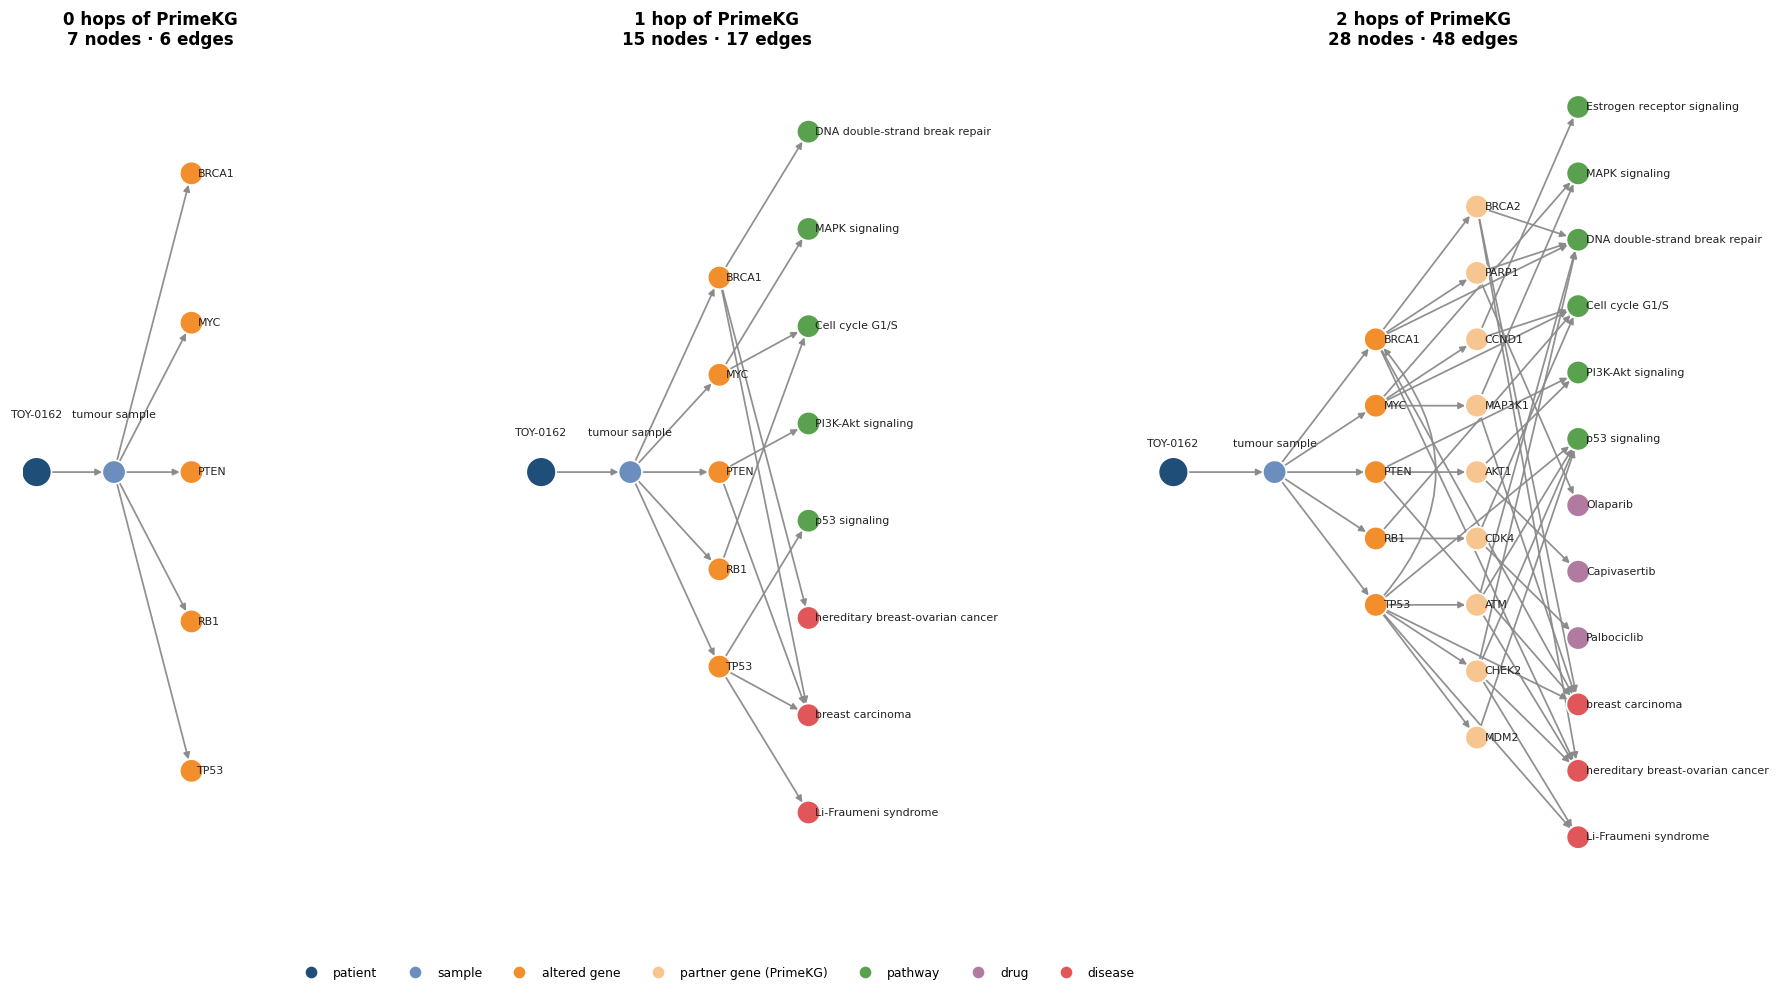

In [17]:
def add_context(F, gene_node):
    # Hop 1 of a gene: its pathways, drugs and diseases.
    for nb in KG_NEIGHBOURS.get(F.nodes[gene_node]["entrez"], []):
        if nb["type"] == "gene":
            continue
        if nb["node"] not in F:
            F.add_node(nb["node"], type=nb["type"], label=nb["name"])
        F.add_edge(gene_node, nb["node"], relation=nb["relation"])

def fuse(G, hops=2):
    # Patient graph + PrimeKG neighbourhood of its altered genes.
    F = G.copy()
    altered_genes = [n for n, d in G.nodes(data=True) if d["type"] == "gene"]
    if hops >= 1:
        for g in altered_genes:
            add_context(F, g)
    if hops >= 2:
        for g in altered_genes:
            for nb in KG_NEIGHBOURS.get(F.nodes[g]["entrez"], []):
                if nb["type"] != "gene":
                    continue
                partner = nb["node"]
                if partner not in F:
                    F.add_node(partner, type="gene", label=nb["name"], entrez=nb["entrez"], altered=False, mut=0, amp=0, dele=0)
                    add_context(F, partner)
                if not F.has_edge(g, partner) and not F.has_edge(partner, g):
                    F.add_edge(g, partner, relation="protein_protein")
    return F

fig, axes = plt.subplots(1, 3, figsize=(17, 9.5), gridspec_kw={"width_ratios": [1, 1.5, 2.1]})
for ax, hops in zip(axes, (0, 1, 2)):
    F = fuse(G_demo, hops)
    draw_graph(F, ax, title=f"{hops} hop{'s' if hops != 1 else ''} of PrimeKG\n{F.number_of_nodes()} nodes · {F.number_of_edges()} edges", font=7.5)
type_legend(axes[1]); plt.tight_layout(); plt.show()

**What you are seeing.** Left: the raw patient graph. Middle: each altered gene now points to *what it does* (pathways, drugs, diseases). Right: with 2 hops, the genes' interaction partners and *their* knowledge join in.
Two altered genes that look unrelated can now **meet on a shared pathway node**. Both the neural and the symbolic reasoners can use that structure.

Now we fuse every patient in the cohort:

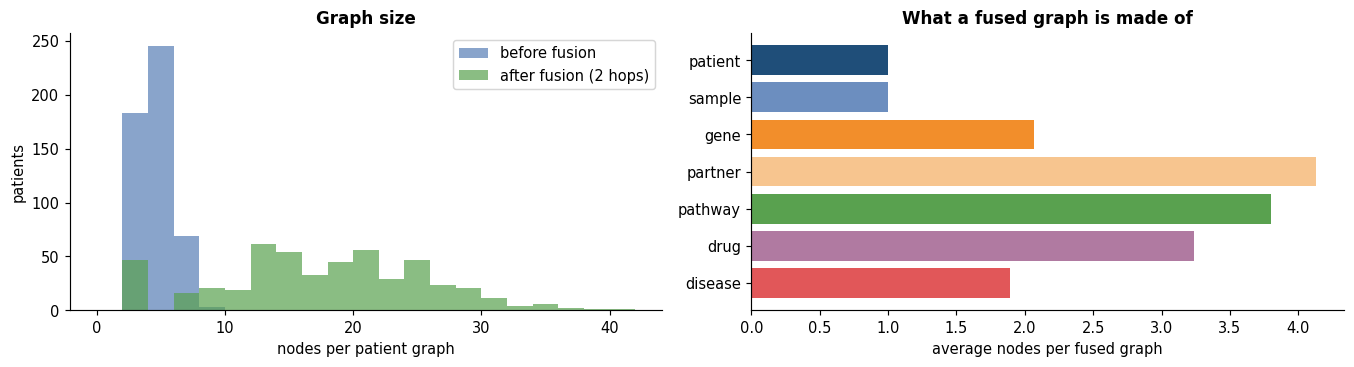

Average graph: 4.1 nodes before → 17.1 nodes after fusion


In [18]:
FUSED = {pid: fuse(patient_graph(pid), hops=2) for pid in PIDS}
sizes = pd.DataFrame({"before fusion": [patient_graph(p).number_of_nodes() for p in PIDS],
                      "after fusion (2 hops)": [FUSED[p].number_of_nodes() for p in PIDS]}, index=PIDS)
type_counts = pd.DataFrame([pd.Series([d["type"] if d.get("altered", True) else "partner" for _, d in FUSED[p].nodes(data=True)]).value_counts()
                            for p in PIDS]).fillna(0).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
bins = np.arange(0, sizes.values.max() + 3, 2)
axes[0].hist(sizes["before fusion"], bins=bins, alpha=0.8, color=TYPE_COLORS["sample"], label="before fusion")
axes[0].hist(sizes["after fusion (2 hops)"], bins=bins, alpha=0.7, color=TYPE_COLORS["pathway"], label="after fusion (2 hops)")
axes[0].set_xlabel("nodes per patient graph"); axes[0].set_ylabel("patients"); axes[0].legend(); axes[0].set_title("Graph size")
order_t = [t for t in ("patient", "sample", "gene", "partner", "pathway", "drug", "disease") if t in type_counts]
axes[1].barh(order_t[::-1], type_counts[order_t[::-1]], color=[TYPE_COLORS[t] for t in order_t[::-1]])
axes[1].set_xlabel("average nodes per fused graph"); axes[1].set_title("What a fused graph is made of")
plt.tight_layout(); plt.show()
print(f"Average graph: {sizes['before fusion'].mean():.1f} nodes before → {sizes['after fusion (2 hops)'].mean():.1f} nodes after fusion")

---
# Step 5 · The neural part: a graph neural network 🧠

A **graph neural network (GNN)** works by *message passing*. Every node starts with a small vector describing itself (its type, which entity it is, the clinical record for the patient node, the alteration flags for a gene node).
In each layer, every node collects **messages** from its neighbours, one learned transformation per relation type (*relational* GNN, as in R-GCN), and updates its vector.
After 3 layers, the patient node "has heard" about everything up to 3 hops away. Its vector then goes through a small network that outputs one number: the **neural risk**.

**Training signal.** We do not have a simple yes/no label: some patients were followed for only a few months (*censored*). So the GNN is trained with the **Cox partial likelihood**:
for every patient $i$ who progressed at time $t_i$, the model is rewarded when $i$'s risk is high compared with everyone still progression-free at $t_i$:

$$\mathcal{L} = -\frac{1}{\#\text{events}}\sum_{i:\,\text{progressed}} \Big( r_i - \log \sum_{j:\,t_j \ge t_i} e^{r_j} \Big)$$

**Honest evaluation.** We use **5-fold cross-validation**: the cohort is cut into 5 parts, and each part is scored by a model trained on the other 4. Every prediction below is *out-of-fold*, so no patient is scored by a model that saw them.

First, what "3 layers of message passing" means for the demo patient:

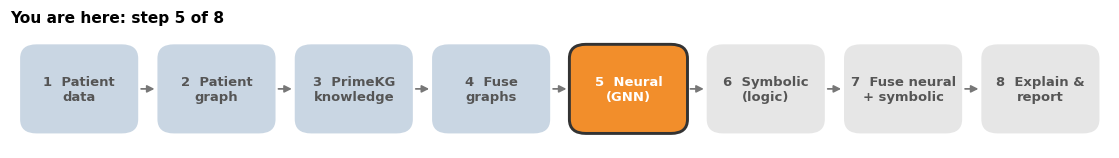

In [19]:
roadmap(5)

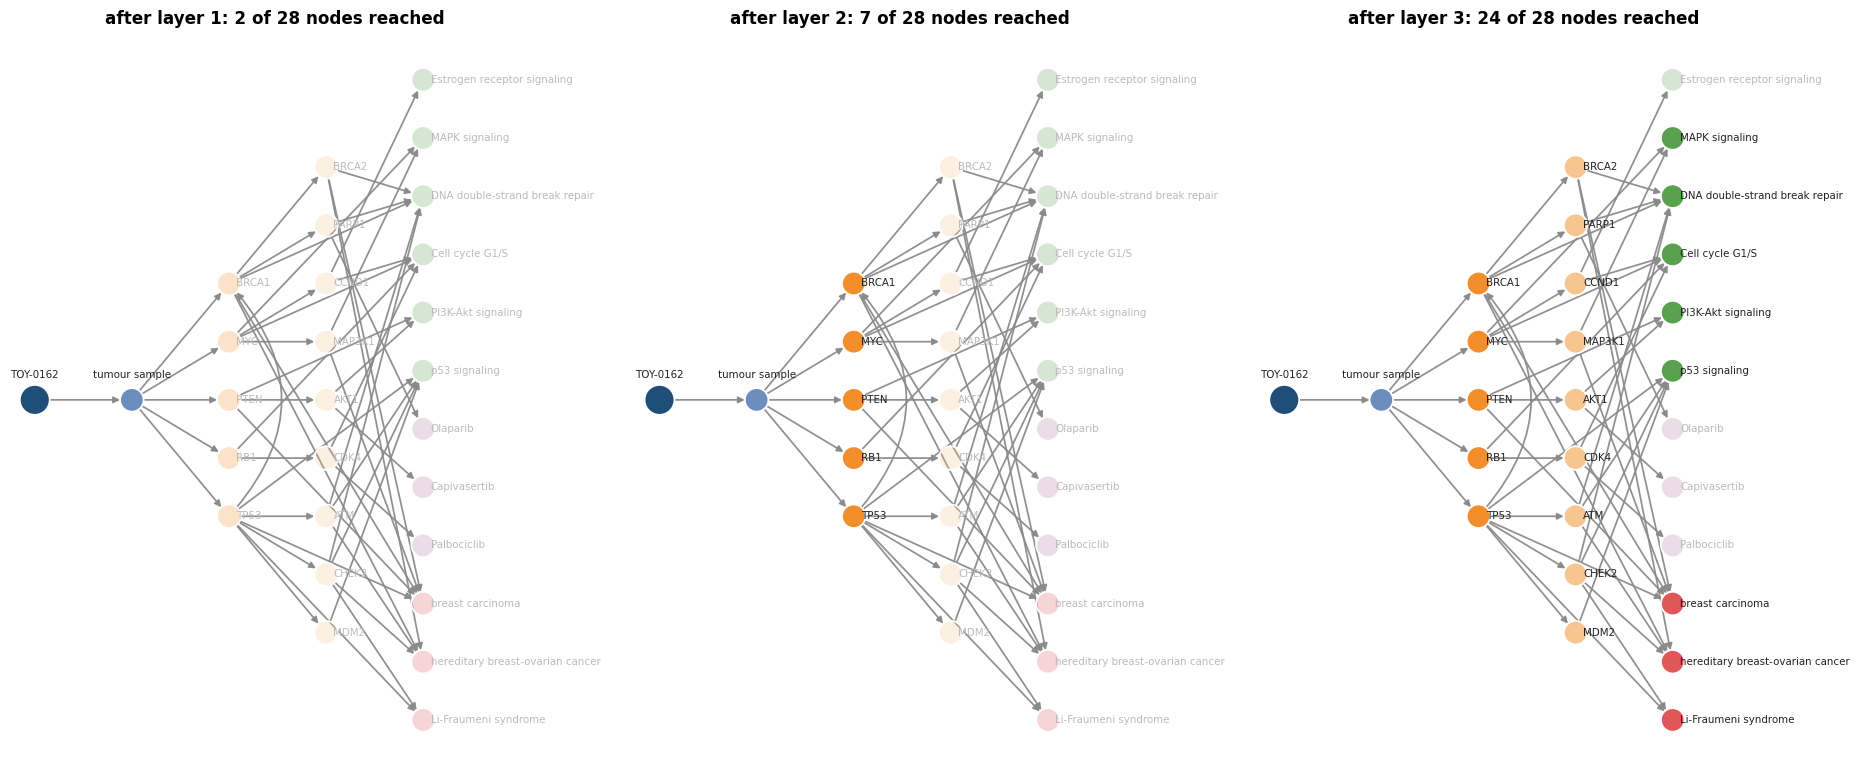

In [20]:
#@title 🔭 Receptive field: what the patient node can "hear" after 1, 2, 3 layers
F_demo = FUSED[DEMO]
pos_demo = layered_layout(F_demo)
hops = nx.single_source_shortest_path_length(F_demo.to_undirected(as_view=True), f"patient:{DEMO}")
fig, axes = plt.subplots(1, 3, figsize=(18, 7.5))
for ax, layer in zip(axes, (1, 2, 3)):
    draw_graph(F_demo, ax, pos=pos_demo, faded=[n for n, h in hops.items() if h > layer], font=7,
               title=f"after layer {layer}: {sum(h <= layer for h in hops.values())} of {len(hops)} nodes reached")
plt.tight_layout(); plt.show()

In [21]:
# ---------- 1. turn every fused graph into tensors ----------
NODE_TYPES = ["patient", "sample", "gene", "pathway", "drug", "disease"]
RELATIONS = ["has_sample", "has_mutation", "has_high_level_amplification", "has_homozygous_deletion",
             "protein_protein", "pathway_protein", "drug_protein", "disease_protein"]
# Fixed vocabulary of entities, so that a brand-new patient can be encoded later.
ENTITY = {"<patient>": 0, "<sample>": 1}
for e in sorted({f"gene:{v}" for v in PANEL.values()} | set(KG_NODE_NAME)):
    ENTITY[e] = len(ENTITY)
AGE_MEAN, AGE_STD = clinical.AGE.mean(), clinical.AGE.std()
N_LEVELS, T_LEVELS = ["N0", "N1", "N2", "N3"], ["T1", "T2", "T3", "T4"]

def clinical_vector(d):
    return np.r_[(d["age"] - AGE_MEAN) / AGE_STD, [d["n_stage"] == v for v in N_LEVELS],
                 [d["t_stage"] == v for v in T_LEVELS], [d["subtype"] == v for v in SUBTYPES]].astype(np.float32)

N_FEATURES = len(NODE_TYPES) + 14 + 4

def encode(F):
    nodes = list(F.nodes)
    index = {n: i for i, n in enumerate(nodes)}
    x = np.zeros((len(nodes), N_FEATURES), np.float32)
    ent = []
    for i, n in enumerate(nodes):
        d = F.nodes[n]
        x[i, NODE_TYPES.index(d["type"])] = 1
        if d["type"] == "patient":
            x[i, 6:20] = clinical_vector(d); ent.append(0)
        elif d["type"] == "sample":
            ent.append(1)
        else:
            ent.append(ENTITY[n])
        if d["type"] == "gene":
            x[i, 20:24] = [d["mut"], d["amp"], d["dele"], float(d["altered"])]
    edges = [(u, v, r) for u, v, r in F.edges(data="relation")]
    assert F.nodes[nodes[0]]["type"] == "patient"
    return {"x": torch.tensor(x), "ent": torch.tensor(ent), "src": torch.tensor([index[u] for u, _, _ in edges]),
            "dst": torch.tensor([index[v] for _, v, _ in edges]), "rel": torch.tensor([RELATIONS.index(r) for _, _, r in edges]),
            "edges": [(u, v) for u, v, _ in edges], "nodes": nodes}

def collate(encoded):
    # Put many graphs side by side in one big disconnected graph.
    offsets = np.cumsum([0] + [len(e["nodes"]) for e in encoded])
    cat = lambda key, shift=False: torch.cat([e[key] + (int(o) if shift else 0) for e, o in zip(encoded, offsets)])
    b = {"x": cat("x"), "ent": cat("ent"), "src": cat("src", True), "dst": cat("dst", True), "rel": cat("rel"),
         "patient_idx": torch.tensor(offsets[:-1]),
         "graph": torch.cat([torch.full((len(e["nodes"]),), i) for i, e in enumerate(encoded)]), "n_graphs": len(encoded)}
    # precomputed once: both edge directions, edges grouped by relation, in-degree of every node
    b["s2"], b["d2"] = torch.cat([b["src"], b["dst"]]), torch.cat([b["dst"], b["src"]])
    r2 = torch.cat([b["rel"], b["rel"] + len(RELATIONS)])
    b["groups"] = [(int(k), (r2 == k).nonzero(as_tuple=True)[0]) for k in torch.unique(r2)]
    b["degree"] = torch.zeros(len(b["x"])).index_add_(0, b["d2"], torch.ones(len(r2))).clamp(min=1)
    return b

# ---------- 2. the relational GNN ----------
class RelationalLayer(nn.Module):
    def __init__(self, dim, n_rel):
        super().__init__()
        self.n_rel = n_rel
        self.weight = nn.Parameter(torch.randn(2 * n_rel, dim, dim) / math.sqrt(dim))   # one matrix per relation and direction
        self.self_loop = nn.Linear(dim, dim)

    def forward(self, h, b, edge_weight):
        # every edge is used in both directions; messages are averaged over the incoming edges
        w = torch.cat([edge_weight, edge_weight])
        out = torch.zeros_like(h)
        for k, idx in b["groups"]:
            out = out.index_add(0, b["d2"][idx], (h[b["s2"][idx]] @ self.weight[k]) * w[idx, None])
        return torch.relu(self.self_loop(h) + out / b["degree"][:, None])

class PatientGNN(nn.Module):
    def __init__(self, n_entities, n_features, dim=16, layers=3, dropout=0.3):
        super().__init__()
        self.entity = nn.Embedding(n_entities, dim)
        self.inp = nn.Linear(n_features, dim)
        self.layers = nn.ModuleList(RelationalLayer(dim, len(RELATIONS)) for _ in range(layers))
        self.drop = nn.Dropout(dropout)
        self.head = nn.Sequential(nn.Linear(2 * dim, dim), nn.ReLU(), nn.Linear(dim, 1))

    def forward(self, b, edge_weight=None):
        h = self.entity(b["ent"]) + self.inp(b["x"])
        w = torch.ones(len(b["src"])) if edge_weight is None else edge_weight
        for layer in self.layers:
            h = self.drop(layer(h, b, w))
        pooled = torch.zeros(b["n_graphs"], h.size(1)).index_add_(0, b["graph"], h)
        pooled = pooled / torch.bincount(b["graph"], minlength=b["n_graphs"]).clamp(min=1)[:, None]
        return self.head(torch.cat([h[b["patient_idx"]], pooled], 1)).squeeze(-1)

def cox_loss_torch(risk, time, event):
    order = torch.argsort(time, descending=True)
    r, e = risk[order], event[order]
    return -((r - torch.logcumsumexp(r, 0)) * e).sum() / e.sum().clamp(min=1)

ENCODED = [encode(FUSED[p]) for p in PIDS]
BATCH = collate(ENCODED)
FOLDS, FOLD_OF = make_folds(EVENT, 5, SEED)
T_TIME, T_EVENT = torch.tensor(TIME, dtype=torch.float32), torch.tensor(EVENT, dtype=torch.float32)
print(f"One batch of {BATCH['n_graphs']} graphs: {len(BATCH['x'])} nodes, {len(BATCH['src'])} edges, {len(ENTITY)} distinct entities")
print("Model parameters:", sum(p.numel() for p in PatientGNN(len(ENTITY), N_FEATURES).parameters()))

One batch of 500 graphs: 8566 nodes, 12750 edges, 49 distinct entities
Model parameters: 14833


fold 1: held-out C-index = 0.676


fold 2: held-out C-index = 0.688


fold 3: held-out C-index = 0.680


fold 4: held-out C-index = 0.708


fold 5: held-out C-index = 0.699

🧠 GNN out-of-fold C-index: 0.690 ± 0.012


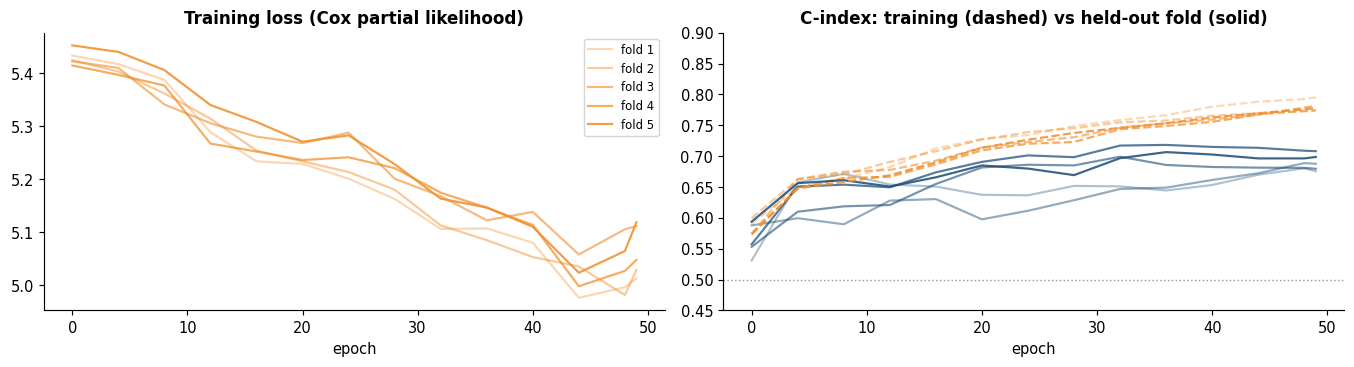

In [22]:
# ---------- 3. train with 5-fold cross-validation ----------
EPOCHS = 50

def train_gnn(train_idx, test_idx=None, epochs=EPOCHS, seed=SEED):
    torch.manual_seed(seed)
    model = PatientGNN(len(ENTITY), N_FEATURES)
    opt = torch.optim.Adam(model.parameters(), lr=1e-2, weight_decay=1e-3)
    tr = torch.tensor(train_idx)
    history = []
    for epoch in range(epochs):
        model.train()
        loss = cox_loss_torch(model(BATCH)[tr], T_TIME[tr], T_EVENT[tr])
        opt.zero_grad(); loss.backward(); opt.step()
        if test_idx is not None and (epoch % 4 == 0 or epoch == epochs - 1):
            model.eval()
            with torch.no_grad():
                risk = model(BATCH).numpy()
            history.append((epoch, loss.item(), c_index(TIME[train_idx], EVENT[train_idx], risk[train_idx]),
                            c_index(TIME[test_idx], EVENT[test_idx], risk[test_idx])))
    model.eval()
    return model, history

GNN_OOF = np.zeros(len(PIDS))
FOLD_MODELS, histories = [], []
for k, (tr, te) in enumerate(FOLDS):
    model, hist = train_gnn(tr, te)
    with torch.no_grad():
        GNN_OOF[te] = model(BATCH).numpy()[te]
    FOLD_MODELS.append(model); histories.append(hist)
    print(f"fold {k + 1}: held-out C-index = {c_index(TIME[te], EVENT[te], GNN_OOF[te]):.3f}")
gnn_fold_c = [c_index(TIME[te], EVENT[te], GNN_OOF[te]) for _, te in FOLDS]
print(f"\n🧠 GNN out-of-fold C-index: {np.mean(gnn_fold_c):.3f} ± {np.std(gnn_fold_c):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for k, hist in enumerate(histories):
    h = np.array(hist)
    axes[0].plot(h[:, 0], h[:, 1], color="#f28e2b", alpha=0.35 + 0.13 * k, label=f"fold {k + 1}")
    axes[1].plot(h[:, 0], h[:, 3], color="#1f4e79", alpha=0.35 + 0.13 * k)
    axes[1].plot(h[:, 0], h[:, 2], color="#f28e2b", alpha=0.35 + 0.13 * k, ls="--")
axes[0].set_title("Training loss (Cox partial likelihood)"); axes[0].set_xlabel("epoch"); axes[0].legend(fontsize=8)
axes[1].axhline(0.5, color=GREY, ls=":", lw=1); axes[1].set_ylim(0.45, 0.9)
axes[1].set_title("C-index: training (dashed) vs held-out fold (solid)"); axes[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

### 🕳️ The black-box problem, and GNNExplainer

The GNN outputs one number per patient. *Why* that number? To open the box the project uses **GNNExplainer**: it learns a soft **mask** over the edges of one patient's graph (a value between 0 and 1 per edge) that keeps the prediction unchanged while switching off as many edges as possible.
Edges that survive the mask are the ones the GNN actually relied on. We always explain a patient with the **fold model that never trained on them**.

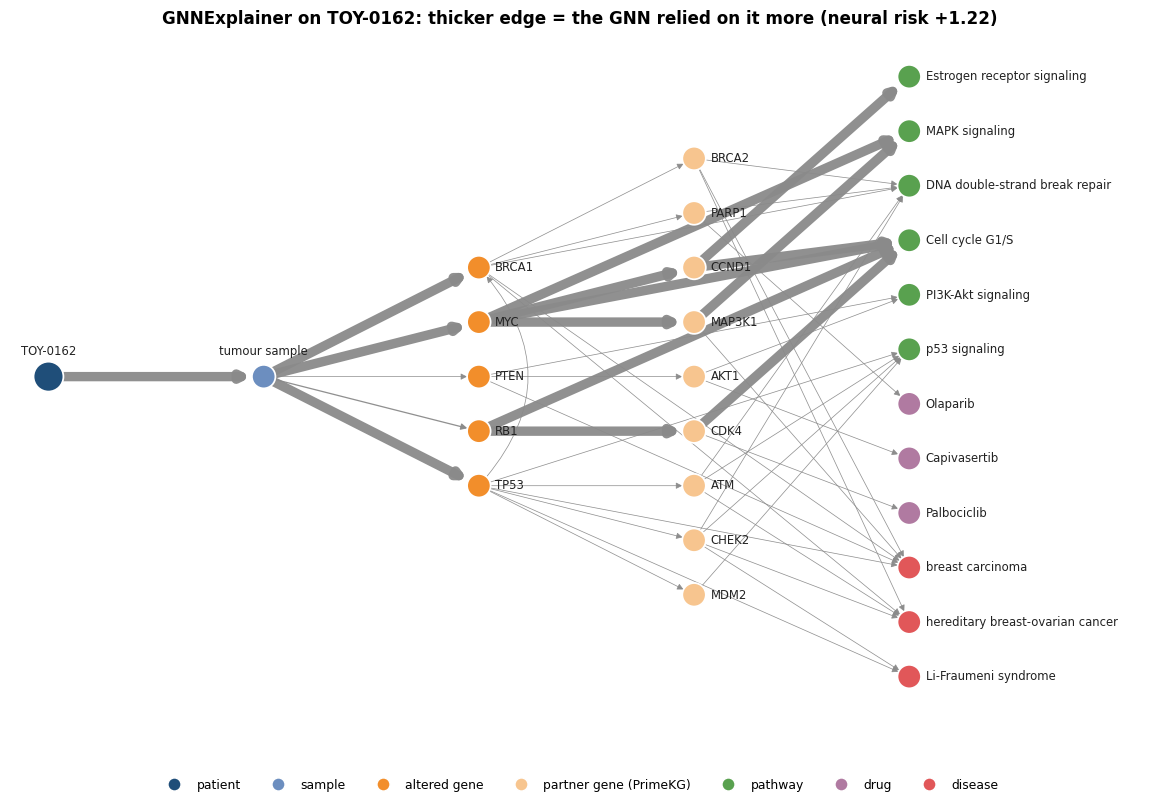

,from,relation,to,edge importance
0,MYC,interacts,CCND1,0.997
1,MAP3K1,in pathway,MAPK signaling,0.996
2,MYC,in pathway,MAPK signaling,0.996
3,tumour sample,amplification,MYC,0.996
4,CCND1,in pathway,Estrogen receptor signaling,0.996
5,CCND1,in pathway,Cell cycle G1/S,0.996


In [23]:
def explain_edges(model, enc, steps=100, sparsity=0.01, seed=0):
    # GNNExplainer for a risk score: a sparse edge mask that preserves the prediction.
    torch.manual_seed(seed)
    b = collate([enc])
    model.eval()
    with torch.no_grad():
        target = model(b)
    logits = nn.Parameter(torch.full((len(enc["src"]),), 2.0) + 0.1 * torch.randn(len(enc["src"])))
    opt = torch.optim.Adam([logits], lr=0.1)
    for _ in range(steps):
        mask = torch.sigmoid(logits)
        fidelity = (model(b, edge_weight=mask) - target).pow(2).sum()
        entropy = -(mask * torch.log(mask + 1e-8) + (1 - mask) * torch.log(1 - mask + 1e-8)).mean()
        loss = fidelity + sparsity * mask.sum() + 0.05 * entropy
        opt.zero_grad(); loss.backward(); opt.step()
    mask = torch.sigmoid(logits).detach().numpy()
    strength = {}
    for (u, v), m in zip(enc["edges"], mask):
        strength[(u, v)] = max(strength.get((u, v), 0.0), float(m))
    return strength

demo_i = PIDS.index(DEMO)
demo_model = FOLD_MODELS[FOLD_OF[demo_i]]
DEMO_MASK = explain_edges(demo_model, ENCODED[demo_i])
fig, ax = plt.subplots(figsize=(14, 8.5))
draw_graph(F_demo, ax, pos=pos_demo, edge_strength=DEMO_MASK, font=8,
           title=f"GNNExplainer on {DEMO}: thicker edge = the GNN relied on it more (neural risk {GNN_OOF[demo_i]:+.2f})")
type_legend(ax); plt.show()
top_edges = sorted(DEMO_MASK.items(), key=lambda kv: -kv[1])[:6]
display(pd.DataFrame([(F_demo.nodes[u]["label"], SHORT_REL[F_demo.edges[u, v, 0]["relation"]], F_demo.nodes[v]["label"], round(s, 3))
                      for (u, v), s in top_edges], columns=["from", "relation", "to", "edge importance"]))

**What you are seeing.** GNNExplainer tells us *which edges* mattered, but not *what they mean* or whether that pattern holds across patients.
A thick edge into a pathway node is a hint, not a reason. That gap is what the symbolic part fills.

---
# Step 6 · The symbolic part: logic over facts 📜

The symbolic reasoner does not look at vectors. It looks at **facts written in first-order logic**, called *ground atoms*. For every patient `p`:

| Kind | Example atom | Value |
|---|---|---|
| clinical | `NStage(p, N3)`, `Subtype(p, Basal)`, `Age(p) ≥ 65` | 0 or 1 |
| genomic | `Mutated(p, TP53)`, `Amplified(p, MYC)`, `Deleted(p, RB1)` | 0 or 1 |
| **PrimeKG (relational)** | `Altered(p, g) ∧ InPathway(g, 'Cell cycle G1/S')` | **number of the patient's altered genes `g` for which the relation holds** |

The third row is where PrimeKG enters the logic. The variable `g` ranges over the patient's altered genes, and the atom counts its *true groundings*. That is exactly what a **Markov logic network** counts.

Then a **formula** combines atoms and concludes progression, with a learned **weight**:

$$ w:\quad \texttt{Subtype}(p,\text{Basal}) \;\wedge\; \texttt{Altered}(p,g) \wedge \texttt{InPathway}(g,\text{'DNA repair'}) \;\Rightarrow\; \texttt{Progress}(p)$$

A positive weight means *this pattern makes progression more likely*. A negative weight means *less likely*.
Atoms are kept by **prevalence only** (3–90% of patients), never by looking at the outcome.

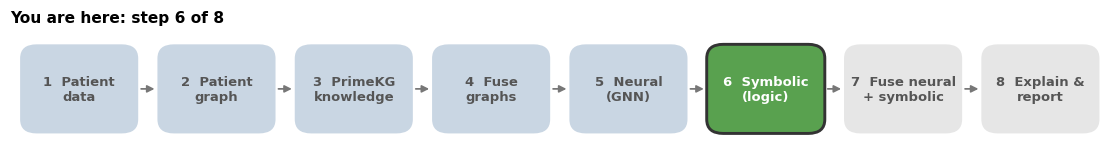

In [24]:
roadmap(6)

In [25]:
# ---------- 1. ground atoms ----------
def patient_context(clin_row, alteration_rows):
    kinds = defaultdict(set)
    for r in alteration_rows.itertuples():
        kinds[r.kind].add(r.gene)
    return {"clin": clin_row, "mut": kinds["mut"], "amp": kinds["amp"], "del": kinds["del"],
            "altered": kinds["mut"] | kinds["amp"] | kinds["del"]}

CANDIDATE_ATOMS = []   # (name, formula, kind, variable, members, genes, test)
for pred, col, levels in (("NStage", "PATH_N_STAGE", N_LEVELS), ("TStage", "PATH_T_STAGE", T_LEVELS), ("Subtype", "SUBTYPE", SUBTYPES)):
    for lv in levels:
        CANDIDATE_ATOMS.append((f"{pred}={lv}", f"{pred}(p, {lv})", "clinical", col, set(), set(),
                                lambda c, col=col, lv=lv: float(c["clin"][col] == lv)))
CANDIDATE_ATOMS += [("Age>=65", "Age(p) ≥ 65", "clinical", "AGE", set(), set(), lambda c: float(c["clin"]["AGE"] >= 65)),
                    ("Age<40", "Age(p) < 40", "clinical", "AGE", set(), set(), lambda c: float(c["clin"]["AGE"] < 40))]
for gene, entrez in PANEL.items():
    for kind, verb in (("mut", "Mutated"), ("amp", "Amplified"), ("del", "Deleted")):
        CANDIDATE_ATOMS.append((f"{kind}:{gene}", f"{verb}(p, {gene})", "genomic", f"{kind}:{gene}", {f"gene:{entrez}"}, {gene},
                                lambda c, kind=kind, gene=gene: float(gene in c[kind])))
RELATION_WORD = {"pathway": "InPathway", "drug": "TargetedBy", "disease": "LinkedTo"}
for node, genes in sorted(KG_NODE_GENES.items()):
    kind = node.split(":")[0]
    CANDIDATE_ATOMS.append((f"kg_{node}", f"Altered(p, g) ∧ {RELATION_WORD[kind]}(g, '{KG_NODE_NAME[node]}')", f"kg_{kind}", node,
                            {node}, set(genes), lambda c, genes=frozenset(genes): float(len(c["altered"] & genes))))

CONTEXT = {pid: patient_context(clinical.loc[pid], ALT_BY_PATIENT.get(pid, alterations.iloc[:0])) for pid in PIDS}
raw = np.array([[atom[-1](CONTEXT[pid]) for atom in CANDIDATE_ATOMS] for pid in PIDS], dtype=float)

# keep atoms true for 3-90% of patients; merge PrimeKG atoms that hold for exactly the same patients
ATOMS, columns, seen = [], [], {}
for j, (name, formula, kind, variable, members, genes, test) in enumerate(CANDIDATE_ATOMS):
    share = (raw[:, j] > 0).mean()
    if not 0.03 <= share <= 0.90:
        continue
    key = (raw[:, j] > 0).tobytes()
    if kind.startswith("kg_") and key in seen:
        ATOMS[seen[key]]["members"] |= members; ATOMS[seen[key]]["genes"] |= genes
        continue
    if kind.startswith("kg_"):
        seen[key] = len(ATOMS)
    ATOMS.append(dict(name=name, formula=formula, kind=kind, variable=variable, members=set(members), genes=set(genes), test=test))
    columns.append(j)
ATOM_VALUES = raw[:, columns]
ATOM_BIN = ATOM_VALUES > 0
ATOM_NAMES = [a["name"] for a in ATOMS]
ATOM_KIND = np.array([a["kind"] for a in ATOMS])
ATOM_VAR = np.array([a["variable"] for a in ATOMS])

def atom_values(context):
    return np.array([a["test"](context) for a in ATOMS], dtype=float)

print(f"{len(CANDIDATE_ATOMS)} candidate atoms → {len(ATOMS)} kept after the prevalence filter and merging")
display(pd.Series(ATOM_KIND).value_counts().rename("atoms").to_frame())
true_now = [(a["formula"], a["kind"], int(v)) for a, v in zip(ATOMS, ATOM_VALUES[demo_i]) if v > 0]
print(f"\nFacts that are TRUE for {DEMO} (value = number of true groundings):")
display(pd.DataFrame(true_now, columns=["ground atom", "kind", "value"]))

110 candidate atoms → 52 kept after the prevalence filter and merging


,atoms
genomic,19
clinical,15
kg_pathway,8
kg_drug,6
kg_disease,4



Facts that are TRUE for TOY-0162 (value = number of true groundings):


,ground atom,kind,value
0,"NStage(p, N1)",clinical,1
1,"TStage(p, T1)",clinical,1
2,"Subtype(p, Basal)",clinical,1
3,Age(p) ≥ 65,clinical,1
4,"Mutated(p, TP53)",genomic,1
5,"Mutated(p, PTEN)",genomic,1
6,"Amplified(p, MYC)",genomic,1
7,"Deleted(p, RB1)",genomic,1
8,"Mutated(p, BRCA1)",genomic,1
9,"Altered(p, g) ∧ LinkedTo(g, 'breast carcinoma')",kg_disease,3


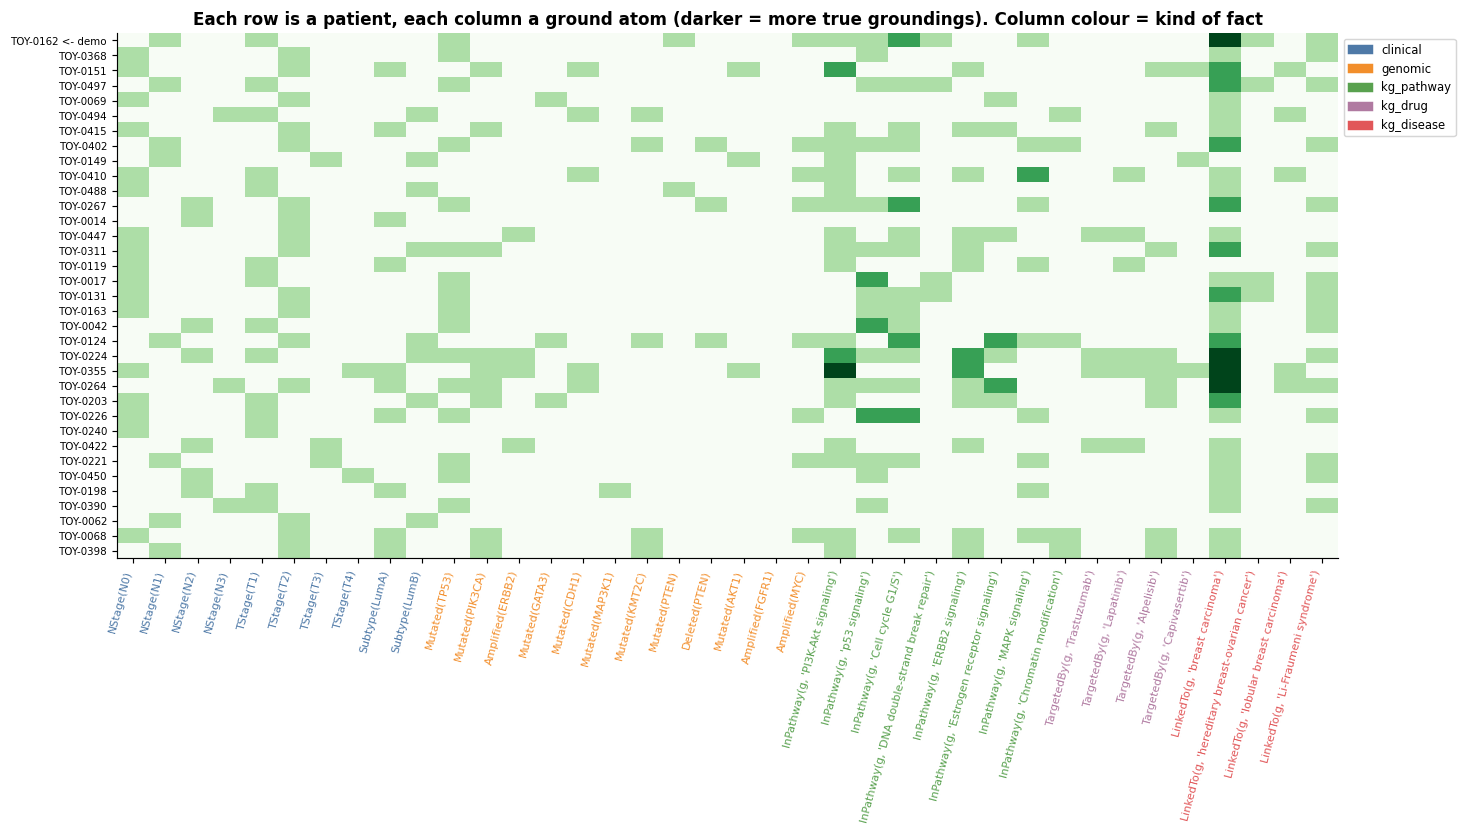

In [26]:
#@title 🔥 The atom table: patients × facts
show = np.r_[np.where(ATOM_KIND == "clinical")[0][:10], np.where(ATOM_KIND == "genomic")[0][:12],
             np.where(ATOM_KIND == "kg_pathway")[0], np.where(ATOM_KIND == "kg_drug")[0][:4], np.where(ATOM_KIND == "kg_disease")[0]]
rows_show = np.r_[[demo_i], np.random.default_rng(1).choice(len(PIDS), 34, replace=False)]
fig, ax = plt.subplots(figsize=(15, 6.5))
V = ATOM_VALUES[np.ix_(rows_show, show)]
ax.imshow(np.minimum(V, 3), aspect="auto", cmap="Greens", vmin=0, vmax=3, interpolation="nearest")
ax.set_xticks(range(len(show))); ax.set_xticklabels([ATOMS[j]["formula"].replace("Altered(p, g) ∧ ", "").replace("(p, ", "(") for j in show],
                                                    rotation=75, ha="right", fontsize=7.5)
for tick, j in zip(ax.get_xticklabels(), show):
    tick.set_color(KIND_COLORS[ATOMS[j]["kind"]])
ax.set_yticks(range(len(rows_show))); ax.set_yticklabels([PIDS[i] + (" <- demo" if i == demo_i else "") for i in rows_show], fontsize=7)
ax.set_title("Each row is a patient, each column a ground atom (darker = more true groundings). Column colour = kind of fact")
ax.legend(handles=[Patch(color=c, label=k) for k, c in KIND_COLORS.items()], loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)
plt.show()

### Which facts separate survival? And why PrimeKG helps

The **log-rank z** of each atom compares the survival of carriers and non-carriers (positive = carriers progress faster).
Look at the middle panel: each of the five cell-cycle genes covers only a slice of the patients, and the rarer ones are weak on their own.
The single PrimeKG atom *"an altered gene in the Cell cycle G1/S pathway"* pools them all, and its signal is much stronger than any one gene's.
This is the core reason to reason **over the knowledge graph** rather than over genes one by one.

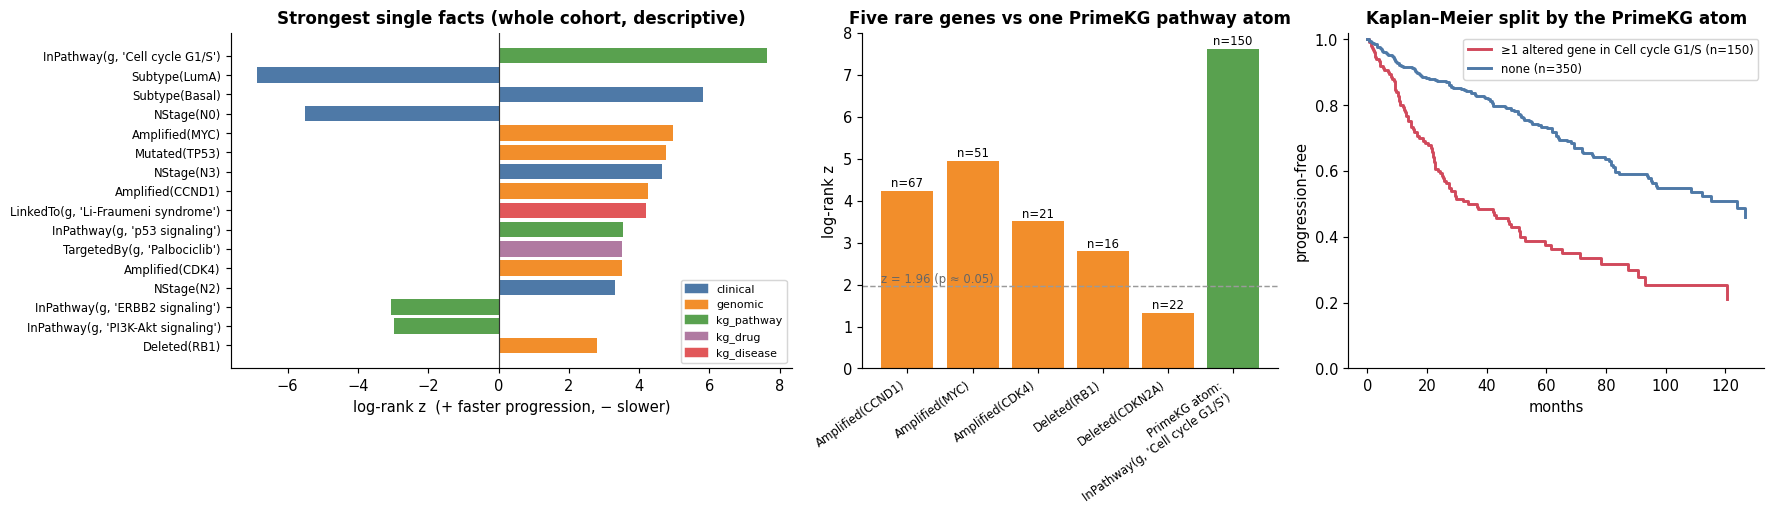

In [27]:
Z_ALL = logrank_z(TIME, EVENT, ATOM_BIN)
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.35, 1, 1]})
top = np.argsort(-np.abs(Z_ALL))[:16][::-1]
axes[0].barh([ATOMS[j]["formula"].replace("Altered(p, g) ∧ ", "").replace("(p, ", "(") for j in top], Z_ALL[top],
             color=[KIND_COLORS[ATOMS[j]["kind"]] for j in top])
axes[0].axvline(0, color="#333", lw=0.8); axes[0].set_xlabel("log-rank z  (+ faster progression, − slower)")
axes[0].set_title("Strongest single facts (whole cohort, descriptive)"); axes[0].tick_params(axis="y", labelsize=8)
axes[0].legend(handles=[Patch(color=c, label=k) for k, c in KIND_COLORS.items()], fontsize=7.5, loc="lower right")

cc_node = next(n for n, name in KG_NODE_NAME.items() if name == "Cell cycle G1/S")
cc_atom = next(j for j, a in enumerate(ATOMS) if cc_node in a["members"])
VERB = {"amp": "Amplified", "del": "Deleted"}
gene_atoms = [(k, g, f"{VERB[k]}({g})") for k, g in
              (("amp", "CCND1"), ("amp", "MYC"), ("amp", "CDK4"), ("del", "RB1"), ("del", "CDKN2A"))]
labels, zs, carriers = [], [], []
for k, g, label in gene_atoms:
    col = np.array([g in CONTEXT[p][k] for p in PIDS])
    labels.append(label); zs.append(logrank_z(TIME, EVENT, col)[0]); carriers.append(col.sum())
labels.append("PrimeKG atom:\nInPathway(g, 'Cell cycle G1/S')"); zs.append(Z_ALL[cc_atom]); carriers.append(ATOM_BIN[:, cc_atom].sum())
axes[1].bar(range(len(zs)), zs, color=[TYPE_COLORS["gene"]] * 5 + [TYPE_COLORS["pathway"]])
axes[1].axhline(1.96, color=GREY, ls="--", lw=1); axes[1].text(-0.4, 2.05, "z = 1.96 (p ≈ 0.05)", fontsize=8, color="#666")
axes[1].set_xticks(range(len(zs))); axes[1].set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
for i, (z, n) in enumerate(zip(zs, carriers)):
    axes[1].text(i, z + 0.1, f"n={n}", ha="center", fontsize=8)
axes[1].set_ylabel("log-rank z"); axes[1].set_title("Five rare genes vs one PrimeKG pathway atom")

for flag, color, label in ((True, RISK_RED, "≥1 altered gene in Cell cycle G1/S"), (False, "#4e79a7", "none")):
    m = ATOM_BIN[:, cc_atom] == flag
    t, s = km_curve(TIME[m], EVENT[m]); axes[2].step(t, s, where="post", color=color, lw=2, label=f"{label} (n={m.sum()})")
axes[2].set_ylim(0, 1.02); axes[2].set_xlabel("months"); axes[2].set_ylabel("progression-free"); axes[2].legend(fontsize=8)
axes[2].set_title("Kaplan–Meier split by the PrimeKG atom")
plt.tight_layout(); plt.show()

### 🎲 Reinforcement-learned rule search (the structure learner)

Which **combinations** of atoms are worth a formula? With ~100 atoms there are hundreds of thousands of 3-atom conjunctions, far too many to test one by one.
The project trains a small **policy network** (a GRU) to *write* rules one atom at a time, using **reinforcement learning** (REINFORCE):

1. the policy samples a rule such as `Subtype(p, Basal) ∧ Altered(p,g) ∧ InPathway(g,'DNA repair')`;
2. the **reward** is how well that rule separates survival, measured *on two disjoint halves* of the training data. A rule earns credit only if both halves agree in direction (**stability reward**), scored by the weaker half;
3. the policy is nudged towards rules with high reward, and samples again.

Finally, rules must **replicate** on a 30% slice of the training fold that no reward ever saw. Here is the search on the training part of fold 1:

{'episodes': 8960, 'distinct rules tried': 2687, 'replicated rules kept': 20}


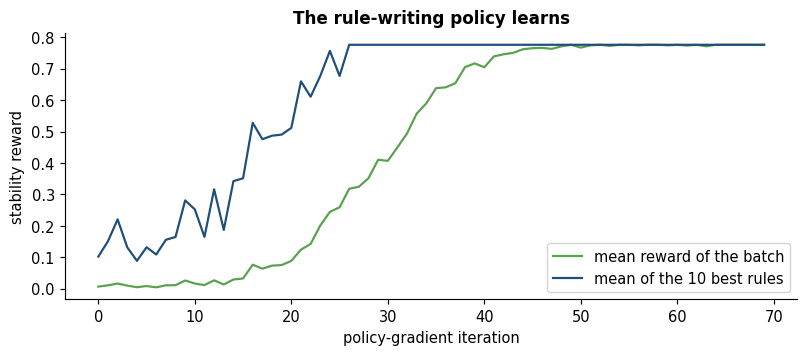

,RL-proposed rule (fold 1),stability reward,z on unseen 30%
0,"Subtype(p, Basal) ∧ Altered(p, g) ∧ InPathway(g, 'p53 signaling') ⇒ Progress(p)",0.625,3.44
1,"Subtype(p, Basal) ∧ Altered(p, g) ∧ LinkedTo(g, 'hereditary breast-ovarian cancer') ∧ Altered(p, g) ∧ InPa...",0.659,3.01
2,"Altered(p, g) ∧ InPathway(g, 'Cell cycle G1/S') ⇒ Progress(p)",0.594,3.48
3,"Subtype(p, Basal) ∧ Amplified(p, MYC) ∧ Altered(p, g) ∧ InPathway(g, 'p53 signaling') ⇒ Progress(p)",0.589,3.18
4,"Subtype(p, Basal) ∧ Amplified(p, MYC) ∧ Altered(p, g) ∧ LinkedTo(g, 'breast carcinoma') ⇒ Progress(p)",0.585,4.26
5,"Amplified(p, MYC) ∧ Altered(p, g) ∧ InPathway(g, 'p53 signaling') ⇒ Progress(p)",0.549,3.14
6,"Subtype(p, LumA) ⇒ Progress(p)",0.776,-2.74
7,"Subtype(p, Basal) ⇒ Progress(p)",0.538,3.79
8,"Subtype(p, LumA) ∧ Altered(p, g) ∧ LinkedTo(g, 'breast carcinoma') ⇒ Progress(p)",0.591,-2.52
9,"Subtype(p, Basal) ∧ Altered(p, g) ∧ InPathway(g, 'MAPK signaling') ⇒ Progress(p)",0.487,5.01


In [28]:
# ---------- 2. RL rule generator ----------
MAX_ATOMS, Z_CAP, LENGTH_COST, ENTROPY_BONUS = 3, 5.0, 0.03, 0.01

class RulePolicy(nn.Module):
    def __init__(self, n_atoms, dim=32, hidden=64):
        super().__init__()
        self.embedding = nn.Embedding(n_atoms + 1, dim)
        self.cell = nn.GRUCell(dim, hidden)
        self.head = nn.Linear(hidden, n_atoms + 1)       # last action = STOP
        self.start = n_atoms

    def sample(self, batch, exclusive):
        n = self.start
        state = torch.zeros(batch, self.cell.hidden_size)
        token = torch.full((batch,), n, dtype=torch.long)
        chosen = torch.full((batch, MAX_ATOMS), -1, dtype=torch.long)
        mask = torch.zeros(batch, n + 1, dtype=torch.bool)
        alive = torch.ones(batch, dtype=torch.bool)
        log_prob, entropy = torch.zeros(batch), torch.zeros(batch)
        for step in range(MAX_ATOMS):
            state = self.cell(self.embedding(token), state)
            blocked = mask.clone()
            if step == 0:
                blocked[:, n] = True                       # a rule needs at least one atom
            dist = torch.distributions.Categorical(logits=self.head(state).masked_fill(blocked, -1e9))
            action = dist.sample()
            log_prob = log_prob + torch.where(alive, dist.log_prob(action), torch.zeros(batch))
            entropy = entropy + torch.where(alive, dist.entropy(), torch.zeros(batch))
            take = alive & (action != n)
            chosen[take, step] = action[take]
            mask[take] = mask[take] | exclusive[action[take]]  # no two atoms about the same variable
            alive = take
            token = torch.where(alive, action, token)
            if not alive.any():
                break
        return chosen, log_prob, entropy

def coverage(binary, rules):
    covered = np.ones((binary.shape[0], len(rules)), dtype=bool)
    for slot in range(rules.shape[1]):
        a = rules[:, slot]; use = a >= 0
        covered[:, use] &= binary[:, a[use]]
    return covered

def propose_rules(train, seed=SEED, iterations=70, batch=128, limit=20):
    torch.manual_seed(seed); rng_ = np.random.default_rng(seed)
    binary, n_atoms = ATOM_BIN[train], ATOM_BIN.shape[1]
    exclusive = torch.zeros(n_atoms, n_atoms + 1, dtype=torch.bool)
    for j in range(n_atoms):
        exclusive[j, :n_atoms] = torch.tensor(ATOM_VAR == ATOM_VAR[j])
    order = rng_.permutation(len(train)); cut = int(0.7 * len(order))
    search, validation = order[:cut], order[cut:]
    halves = (search[: len(search) // 2], search[len(search) // 2:])
    t, e = TIME[train], EVENT[train]
    policy = RulePolicy(n_atoms); opt = torch.optim.Adam(policy.parameters(), lr=3e-3)
    baseline, archive, curve = 0.0, {}, []
    for _ in range(iterations):
        rules, log_prob, entropy = policy.sample(batch, exclusive)
        R = rules.numpy(); cov = coverage(binary, R); share = cov.mean(0)
        z_a, z_b = (logrank_z(t[h], e[h], cov[h]) for h in halves)
        reward = np.where(np.sign(z_a) == np.sign(z_b), np.minimum(np.minimum(abs(z_a), abs(z_b)), Z_CAP) / Z_CAP, 0.0)
        reward = reward - LENGTH_COST * np.maximum((R >= 0).sum(1) - 1, 0)
        reward = np.where((share >= 0.04) & (share <= 0.9), reward, 0.0)
        for rule, value in zip(R, reward):
            key = tuple(sorted(int(a) for a in rule if a >= 0))
            archive[key] = max(archive.get(key, 0.0), float(value))
        rt = torch.tensor(reward, dtype=torch.float32)
        baseline = 0.9 * baseline + 0.1 * float(rt.mean())
        loss = -((rt - baseline) * log_prob).mean() - ENTROPY_BONUS * entropy.mean()
        opt.zero_grad(); loss.backward(); opt.step()
        curve.append((reward.mean(), np.sort(reward)[-10:].mean()))
    candidates = [k for k, v in sorted(archive.items(), key=lambda kv: -kv[1])[:1500] if v > 0]
    cover = np.vstack([binary[:, list(k)].all(1) for k in candidates]).T
    z_s, z_v = logrank_z(t[search], e[search], cover[search]), logrank_z(t[validation], e[validation], cover[validation])
    replicated = (np.sign(z_s) == np.sign(z_v)) & (np.abs(z_v) >= 1.0)
    score = np.where(replicated, np.minimum([archive[k] for k in candidates], np.minimum(abs(z_v), Z_CAP) / Z_CAP), 0.0)
    selected, covers = [], []
    for i in np.argsort(-score):
        if score[i] <= 0 or len(selected) >= limit:
            break
        c = cover[:, i]
        if any((c & o).sum() / max((c | o).sum(), 1) >= 0.8 for o in covers):
            continue
        selected.append(candidates[i]); covers.append(c)
    stats = {"episodes": iterations * batch, "distinct rules tried": len(archive), "replicated rules kept": len(selected)}
    return selected, np.array(curve), stats, {k: (archive[k], z_v[candidates.index(k)]) for k in selected}

def formula_text(atom_ids, arrow=True):
    return " ∧ ".join(ATOMS[a]["formula"] for a in atom_ids) + (" ⇒ Progress(p)" if arrow else "")

rules_f1, curve_f1, stats_f1, info_f1 = propose_rules(FOLDS[0][0])
print(stats_f1)
fig, ax = plt.subplots(figsize=(9, 3.3))
ax.plot(curve_f1[:, 0], color="#59a14f", label="mean reward of the batch")
ax.plot(curve_f1[:, 1], color="#1f4e79", label="mean of the 10 best rules")
ax.set_xlabel("policy-gradient iteration"); ax.set_ylabel("stability reward"); ax.legend(); ax.set_title("The rule-writing policy learns")
plt.show()
display(pd.DataFrame([(formula_text(k), round(info_f1[k][0], 3), round(float(info_f1[k][1]), 2)) for k in rules_f1[:10]],
                     columns=["RL-proposed rule (fold 1)", "stability reward", "z on unseen 30%"]))

### ⚖️ The survival Markov logic network (MLN): learning the weights

A **Markov logic network** attaches a real weight $w_k$ to every formula $k$. The more true groundings $n_k(p)$ a formula has for patient $p$, the more its weight counts:

$$\text{logic risk}(p) \;=\; \sum_k w_k \,\log\!\big(1 + n_k(p)\big)$$

The **candidate formulas** are: every atom on its own, conjunctions of *clinical/genomic × PrimeKG* atoms mined on the training fold, and the **RL-proposed rules** from above (*RL does the structure learning*).
The weights are learned with the **Cox partial likelihood** (so censoring is handled correctly) plus an **elastic-net** penalty. The L1 part drives most weights to exactly zero, so only a compact set of formulas survives. Its strength is chosen by an inner cross-validation.

We fit four symbolic/clinical models per fold, to see what each ingredient adds:

| Model | Facts it may use |
|---|---|
| Clinical Cox | age, T stage, N stage, subtype |
| Survival MLN **without PrimeKG** | clinical + genomic atoms |
| Survival MLN | + PrimeKG relational atoms |
| **RL-structured survival MLN** (the project's logic engine) | + RL-proposed multi-atom formulas |

In [29]:
# ---------- 3. survival MLN ----------
class Formula:
    def __init__(self, atoms, source):
        self.atoms, self.source = tuple(atoms), source
        self.text = formula_text(self.atoms)
        self.uses_kg = any(ATOM_KIND[a].startswith("kg_") for a in self.atoms)

def candidate_formulas(train, allowed, proposed=(), top_context=12, top_kg=20, max_pairs=60):
    formulas = [Formula((j,), "unary") for j in allowed]
    seen = {f.atoms for f in formulas}
    for key in proposed:
        key = tuple(sorted(key))
        if len(key) > 1 and key not in seen and all(k in allowed for k in key):
            formulas.append(Formula(key, "rl")); seen.add(key)
    z = np.abs(logrank_z(TIME[train], EVENT[train], ATOM_BIN[train]))
    allowed_set = set(allowed)
    ranked = [j for j in np.argsort(-z) if j in allowed_set]
    context = [j for j in ranked if ATOM_KIND[j] in ("clinical", "genomic")][:top_context]
    knowledge = [j for j in ranked if ATOM_KIND[j].startswith("kg_")][:top_kg]
    pairs = [(a, b) for a in context for b in knowledge] + [(a, b) for i, a in enumerate(context) for b in context[i + 1:] if ATOM_VAR[a] != ATOM_VAR[b]]
    if pairs:
        joint = np.vstack([ATOM_BIN[train][:, a] & ATOM_BIN[train][:, b] for a, b in pairs]).T
        share = joint.mean(0)
        zz = np.where((share >= 0.03) & (share <= 0.9), np.abs(logrank_z(TIME[train], EVENT[train], joint)), 0)
        for i in np.argsort(-zz)[:max_pairs]:
            key = tuple(sorted(pairs[i]))
            if zz[i] > 0 and key not in seen:
                formulas.append(Formula(key, "mined")); seen.add(key)
    return formulas

def groundings(values, formulas):
    values = np.atleast_2d(values)
    return np.column_stack([np.log1p(np.prod(values[:, list(f.atoms)], axis=1)) for f in formulas])

class SurvivalMLN:
    def fit(self, train, use_kg=True, proposed=()):
        allowed = [j for j in range(len(ATOMS)) if use_kg or not ATOM_KIND[j].startswith("kg_")]
        self.formulas = candidate_formulas(train, allowed, proposed)
        X = groundings(ATOM_VALUES[train], self.formulas)
        self.scaler = Standardizer().fit(X)
        self.w, self.alpha = fit_cox_cv(self.scaler.transform(X), TIME[train], EVENT[train])
        return self
    def predict(self, values):
        return self.scaler.transform(groundings(values, self.formulas)) @ self.w
    def weights(self):
        rows = [(f.text, f.atoms, float(w), f.source, f.uses_kg) for f, w in zip(self.formulas, self.w) if abs(w) > 1e-8]
        return pd.DataFrame(rows, columns=["formula", "atoms", "weight_per_sd", "source", "uses_kg"]).sort_values("weight_per_sd", key=np.abs, ascending=False)

# Clinical design matrix (used by the clinical Cox and, later, by the fusion model)
def clinical_design(row):
    return np.r_[(row.AGE - AGE_MEAN) / AGE_STD, [row.PATH_N_STAGE == v for v in N_LEVELS[1:]],
                 [row.PATH_T_STAGE == v for v in T_LEVELS[1:]], [row.SUBTYPE == v for v in SUBTYPES[1:]]].astype(float)
CLIN_NAMES = ["age (per SD)"] + [f"N stage {v}" for v in N_LEVELS[1:]] + [f"T stage {v}" for v in T_LEVELS[1:]] + [f"subtype {v}" for v in SUBTYPES[1:]]
X_CLIN = np.vstack([clinical_design(clinical.loc[p]) for p in PIDS])

FUSION_RIDGE = 0.5   # ridge penalty of the plain Cox models (clinical and fusion)
OOF = {name: np.zeros(len(PIDS)) for name in ("Clinical Cox", "Survival MLN (no PrimeKG)", "Survival MLN", "RL-structured MLN")}
OOF["GNN (neural)"] = GNN_OOF
MLN_MODELS, ENGINE_WEIGHTS, RL_RULES = [], [], []
for k, (tr, te) in enumerate(FOLDS):
    sc = Standardizer().fit(X_CLIN[tr])
    w = fit_cox(sc.transform(X_CLIN[tr]), TIME[tr], EVENT[tr], ridge=FUSION_RIDGE)
    OOF["Clinical Cox"][te] = sc.transform(X_CLIN[te]) @ w
    OOF["Survival MLN (no PrimeKG)"][te] = SurvivalMLN().fit(tr, use_kg=False).predict(ATOM_VALUES[te])
    OOF["Survival MLN"][te] = SurvivalMLN().fit(tr, use_kg=True).predict(ATOM_VALUES[te])
    rules = rules_f1 if k == 0 else propose_rules(tr, seed=SEED + k)[0]
    engine = SurvivalMLN().fit(tr, use_kg=True, proposed=rules)
    OOF["RL-structured MLN"][te] = engine.predict(ATOM_VALUES[te])
    MLN_MODELS.append(engine); RL_RULES.append(rules); ENGINE_WEIGHTS.append(engine.weights().assign(fold=k + 1))
    print(f"fold {k + 1}: {len(engine.formulas)} candidate formulas → {len(ENGINE_WEIGHTS[-1])} kept · "
          f"C-index of the logic engine on held-out fold = {c_index(TIME[te], EVENT[te], OOF['RL-structured MLN'][te]):.3f}")

fold 1: 119 candidate formulas → 38 kept · C-index of the logic engine on held-out fold = 0.711


fold 2: 122 candidate formulas → 25 kept · C-index of the logic engine on held-out fold = 0.692


fold 3: 121 candidate formulas → 15 kept · C-index of the logic engine on held-out fold = 0.723


fold 4: 121 candidate formulas → 21 kept · C-index of the logic engine on held-out fold = 0.722


fold 5: 121 candidate formulas → 22 kept · C-index of the logic engine on held-out fold = 0.701


On average 24.2 formulas per fold; 63% of them use a PrimeKG relation.


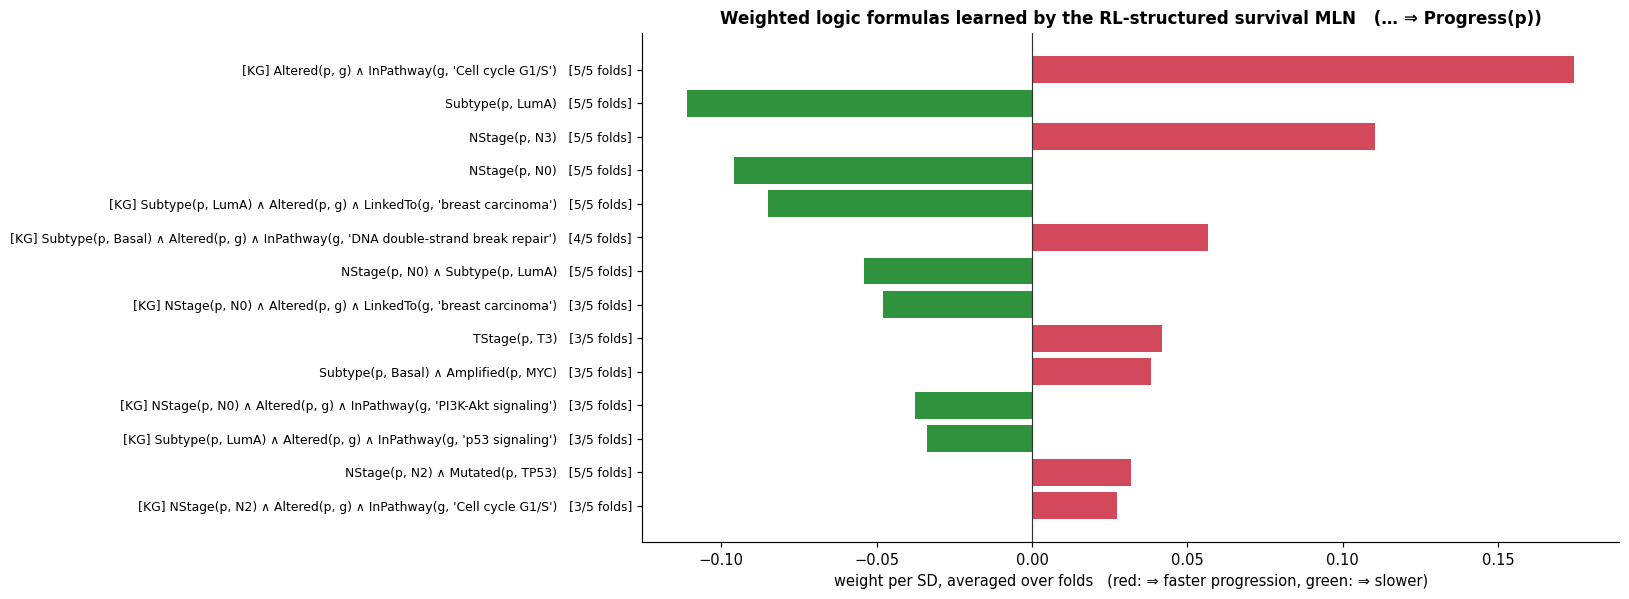

,mean_weight,folds,source,uses_kg
formula,,,,
"Altered(p, g) ∧ InPathway(g, 'Cell cycle G1/S') ⇒ Progress(p)",0.175,5,unary,True
"Subtype(p, LumA) ⇒ Progress(p)",-0.111,5,unary,False
"NStage(p, N3) ⇒ Progress(p)",0.110,5,unary,False
"NStage(p, N0) ⇒ Progress(p)",-0.096,5,unary,False
"Subtype(p, LumA) ∧ Altered(p, g) ∧ LinkedTo(g, 'breast carcinoma') ⇒ Progress(p)",-0.085,5,rl,True
"Subtype(p, Basal) ∧ Altered(p, g) ∧ InPathway(g, 'DNA double-strand break repair') ⇒ Progress(p)",0.057,4,mined,True
"NStage(p, N0) ∧ Subtype(p, LumA) ⇒ Progress(p)",-0.054,5,rl,False
"NStage(p, N0) ∧ Altered(p, g) ∧ LinkedTo(g, 'breast carcinoma') ⇒ Progress(p)",-0.048,3,mined,True
"TStage(p, T3) ⇒ Progress(p)",0.042,3,unary,False


In [30]:
# Formulas the logic engine learned, pooled over the 5 folds
W = pd.concat(ENGINE_WEIGHTS)
CONSENSUS = (W.groupby("formula").agg(atoms=("atoms", "first"), mean_weight=("weight_per_sd", lambda s: s.sum() / 5),
                                      folds=("fold", "nunique"), uses_kg=("uses_kg", "first"), source=("source", "first"))
              .sort_values("mean_weight", key=np.abs, ascending=False))
print(f"On average {len(W) / 5:.1f} formulas per fold; {W.uses_kg.mean():.0%} of them use a PrimeKG relation.")
show_f = CONSENSUS[CONSENSUS.folds >= 3].head(14)[::-1]
fig, ax = plt.subplots(figsize=(12, 6.3))
ax.barh(range(len(show_f)), show_f.mean_weight, color=[RISK_RED if w > 0 else SAFE_GREEN for w in show_f.mean_weight])
ax.set_yticks(range(len(show_f)))
ax.set_yticklabels([("[KG] " if kg else "") + textwrap.shorten(t.replace(" ⇒ Progress(p)", ""), 95) + f"   [{n}/5 folds]"
                    for t, kg, n in zip(show_f.index, show_f.uses_kg, show_f.folds)], fontsize=8.5)
ax.axvline(0, color="#333", lw=0.8)
ax.set_xlabel("weight per SD, averaged over folds   (red: ⇒ faster progression, green: ⇒ slower)")
ax.set_title("Weighted logic formulas learned by the RL-structured survival MLN   (… ⇒ Progress(p))")
plt.show()
display(show_f[::-1][["mean_weight", "folds", "source", "uses_kg"]].round(3))

### 🔓 The answer key: did the reasoner rediscover the hidden mechanism?

Back in Step 1 a hidden mechanism decided who progresses. The pipeline never saw it, only the four data tables.
Now we reveal it and check every hidden rule against the formulas the logic engine learned (✅ = a formula with the same atoms and the same direction was kept in at least 3 of 5 folds).

In [31]:
def _atom_with_member(node_name):
    node = next(n for n, name in KG_NODE_NAME.items() if name == node_name)
    return next(a["name"] for a in ATOMS if node in a["members"])
HIDDEN_KEYS = {
    "NStage(p, N1)": [["NStage=N1"]], "NStage(p, N2)": [["NStage=N2"]], "NStage(p, N3)": [["NStage=N3"]],
    "TStage(p, T3 or T4)": [["TStage=T3"], ["TStage=T4"]], "Age(p) ≥ 70": [["Age>=65"]], "Subtype(p, LumA)": [["Subtype=LumA"]],
    "Altered(p, g) ∧ InPathway(g, 'Cell cycle G1/S')": [[_atom_with_member("Cell cycle G1/S")]],
    "Subtype(p, Basal) ∧ Altered(p, g) ∧ InPathway(g, 'DNA double-strand break repair')":
        [["Subtype=Basal", _atom_with_member("DNA double-strand break repair")]],
}
rows = []
for r in HIDDEN_TRUTH.itertuples():
    best, verdict = None, "❌ not found"
    for f in CONSENSUS[CONSENSUS.folds >= 3].itertuples():
        names = {ATOM_NAMES[a] for a in f.atoms}
        for option in HIDDEN_KEYS[r._1]:
            same_sign = np.sign(f.mean_weight) == np.sign(r._2)
            if set(option) == names and same_sign:
                best, verdict = f, "✅ found"
                break
            if set(option) & names and same_sign and verdict.startswith("❌"):
                best, verdict = f, "🟡 partly (one of its atoms, or a close cousin)"
        if verdict.startswith("✅"):
            break
    rows.append((r._1, r.kind, r._2, best.Index.replace(" ⇒ Progress(p)", "") if best is not None else "–",
                 round(best.mean_weight, 3) if best is not None else np.nan, f"{best.folds}/5" if best is not None else "–", verdict))
ANSWER_KEY = pd.DataFrame(rows, columns=["hidden rule", "kind", "true effect", "best matching learned formula", "learned weight", "folds", "verdict"])
display(ANSWER_KEY)

,hidden rule,kind,true effect,best matching learned formula,learned weight,folds,verdict
0,"NStage(p, N1)",clinical,0.5,–,NaN,–,❌ not found
1,"NStage(p, N2)",clinical,0.9,"NStage(p, N2) ∧ Mutated(p, TP53)",0.032,5/5,"🟡 partly (one of its atoms, or a close cousin)"
2,"NStage(p, N3)",clinical,1.3,"NStage(p, N3)",0.110,5/5,✅ found
3,"TStage(p, T3 or T4)",clinical,0.4,"TStage(p, T3)",0.042,3/5,✅ found
4,Age(p) ≥ 70,clinical,0.3,–,NaN,–,❌ not found
5,"Subtype(p, LumA)",clinical,-0.4,"Subtype(p, LumA)",-0.111,5/5,✅ found
6,"Altered(p, g) ∧ InPathway(g, 'Cell cycle G1/S')",PrimeKG pathway,1.1,"Altered(p, g) ∧ InPathway(g, 'Cell cycle G1/S')",0.175,5/5,✅ found
7,"Subtype(p, Basal) ∧ Altered(p, g) ∧ InPathway(g, 'DNA double-strand break repair')",clinical × PrimeKG,1.2,"Subtype(p, Basal) ∧ Altered(p, g) ∧ InPathway(g, 'DNA double-strand break repair')",0.057,4/5,✅ found


**What you are seeing.** Without ever being told, the symbolic engine wrote down **weighted, readable formulas over PrimeKG relations** that match the mechanism that generated the data:
the pathway-level rule *"an altered gene in the Cell cycle G1/S pathway ⇒ progression"* and the clinical × knowledge-graph rule *"basal subtype ∧ altered DNA-repair gene ⇒ progression"*.
The weights are on a per-SD scale, so compare their **sign and ranking**, not their size, with the true log-hazard effects.
The two smallest clinical effects (N1 stage and age ≥ 70) are not recovered: with 500 patients their signal is weak, and the age atom uses a cut-off of 65, not 70. A reasoner that reported them anyway would be overfitting.
This is something the GNN alone cannot give you: a statement you can read, check against the literature, and test on new data.

---
# Step 7 · Neuro-symbolic fusion 🤝

Now we join the two halves. One **Cox survival model** takes three kinds of evidence for each patient:

$$\text{risk}(p) = \underbrace{\beta^\top \text{clinical}(p)}_{\text{age, stage, subtype}} + \gamma_{\text{GNN}}\cdot \text{neural risk}(p) + \gamma_{\text{logic}}\cdot \text{logic risk}(p)$$

The neural and logic risks are themselves **out-of-fold** predictions, and the fusion model is evaluated with the same 5 folds (*cross-validated stacking*), so no patient is ever scored by a model that saw their outcome.

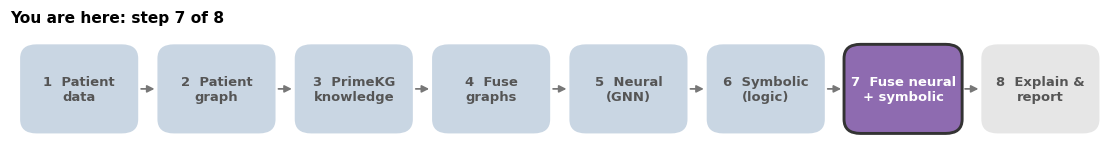

In [32]:
roadmap(7)

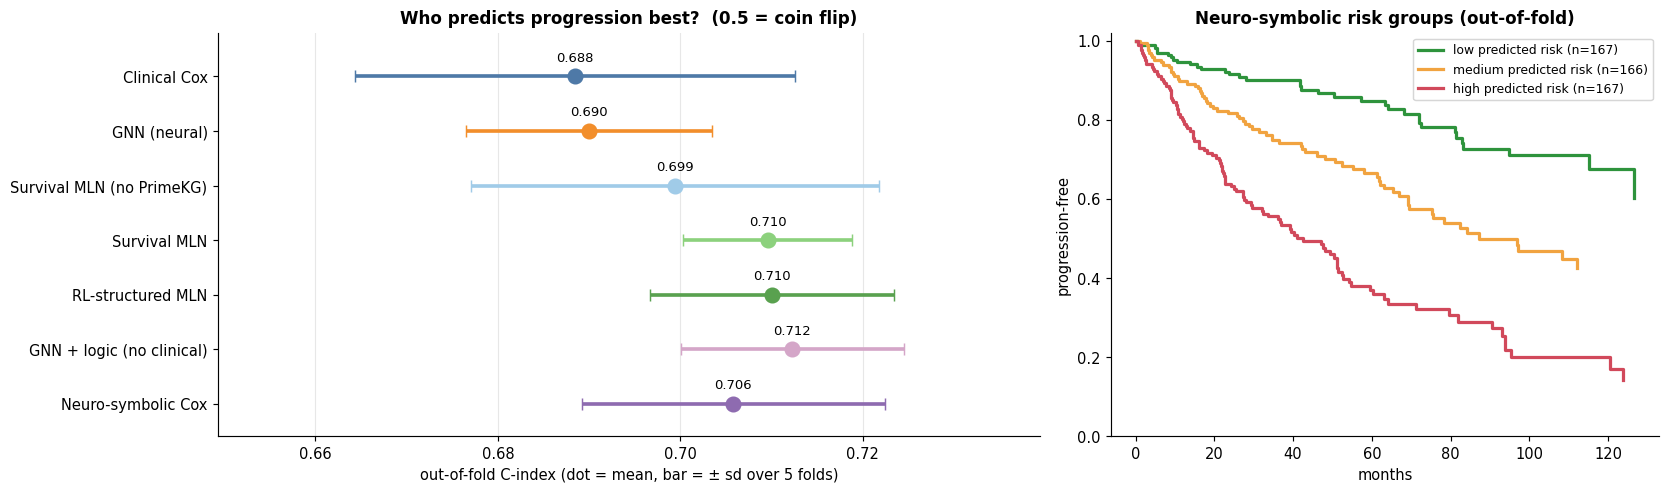

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,sd
Clinical Cox,0.687,0.706,0.660,0.719,0.670,0.688,0.024
GNN (neural),0.676,0.688,0.680,0.708,0.699,0.690,0.013
Survival MLN (no PrimeKG),0.688,0.678,0.685,0.728,0.718,0.699,0.022
Survival MLN,0.715,0.698,0.707,0.722,0.706,0.710,0.009
RL-structured MLN,0.711,0.692,0.723,0.722,0.701,0.710,0.013
GNN + logic (no clinical),0.708,0.701,0.711,0.733,0.708,0.712,0.012
Neuro-symbolic Cox,0.710,0.707,0.685,0.730,0.697,0.706,0.017


Adding PrimeKG atoms to the MLN:            +0.010 C-index
Adding RL-proposed formulas to the MLN:     +0.000 C-index
Neuro-symbolic Cox vs clinical-only Cox:    +0.017 C-index
Typical fold-to-fold standard deviation:    0.016


In [33]:
zs = lambda v: (v - v.mean()) / v.std()
NS_X = np.column_stack([X_CLIN, zs(GNN_OOF), zs(OOF["RL-structured MLN"])])
NS_NAMES = CLIN_NAMES + ["GNN risk (per SD)", "logic risk (per SD)"]
OOF["GNN + logic (no clinical)"] = np.zeros(len(PIDS))
OOF["Neuro-symbolic Cox"] = np.zeros(len(PIDS))
for tr, te in FOLDS:
    sc = Standardizer().fit(NS_X[tr])
    OOF["Neuro-symbolic Cox"][te] = sc.transform(NS_X[te]) @ fit_cox(sc.transform(NS_X[tr]), TIME[tr], EVENT[tr], ridge=FUSION_RIDGE)
    sub = NS_X[:, -2:]
    OOF["GNN + logic (no clinical)"][te] = sub[te] @ fit_cox(sub[tr], TIME[tr], EVENT[tr], ridge=FUSION_RIDGE)

ORDER = ["Clinical Cox", "GNN (neural)", "Survival MLN (no PrimeKG)", "Survival MLN", "RL-structured MLN", "GNN + logic (no clinical)", "Neuro-symbolic Cox"]
COLOR = {"Clinical Cox": "#4e79a7", "GNN (neural)": "#f28e2b", "Survival MLN (no PrimeKG)": "#a0cbe8", "Survival MLN": "#8cd17d",
         "RL-structured MLN": "#59a14f", "GNN + logic (no clinical)": "#d4a6c8", "Neuro-symbolic Cox": "#8e6bb0"}
RESULTS = pd.DataFrame({m: [c_index(TIME[te], EVENT[te], OOF[m][te]) for _, te in FOLDS] for m in ORDER}).T
RESULTS.columns = [f"fold {k + 1}" for k in range(5)]
RESULTS["mean"], RESULTS["sd"] = RESULTS.mean(1), RESULTS.iloc[:, :5].std(1)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
for y, m in enumerate(ORDER[::-1]):
    mean, sd = RESULTS.loc[m, "mean"], RESULTS.loc[m, "sd"]
    ax.errorbar(mean, y, xerr=sd, fmt="o", ms=10, color=COLOR[m], ecolor=COLOR[m], elinewidth=2.5, capsize=4)
    ax.text(mean, y + 0.22, f"{mean:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_yticks(range(len(ORDER))); ax.set_yticklabels(ORDER[::-1]); ax.set_ylim(-0.6, len(ORDER) - 0.2)
lo, hi = (RESULTS["mean"] - RESULTS["sd"]).min(), (RESULTS["mean"] + RESULTS["sd"]).max()
ax.set_xlim(lo - 0.015, hi + 0.015); ax.grid(axis="x", alpha=0.3)
ax.set_xlabel("out-of-fold C-index (dot = mean, bar = ± sd over 5 folds)"); ax.set_title("Who predicts progression best?  (0.5 = coin flip)")
ax = axes[1]
tert = pd.qcut(OOF["Neuro-symbolic Cox"], 3, labels=["low", "medium", "high"])
for lab, col in zip(["low", "medium", "high"], [SAFE_GREEN, "#f1a340", RISK_RED]):
    m = np.asarray(tert == lab)
    t, s = km_curve(TIME[m], EVENT[m]); ax.step(t, s, where="post", color=col, lw=2.2, label=f"{lab} predicted risk (n={m.sum()})")
ax.set_ylim(0, 1.02); ax.set_xlabel("months"); ax.set_ylabel("progression-free"); ax.legend(fontsize=8.5)
ax.set_title("Neuro-symbolic risk groups (out-of-fold)")
plt.tight_layout(); plt.show()
display(RESULTS.round(3))
m = RESULTS["mean"]
print(f"Adding PrimeKG atoms to the MLN:            {m['Survival MLN'] - m['Survival MLN (no PrimeKG)']:+.3f} C-index")
print(f"Adding RL-proposed formulas to the MLN:     {m['RL-structured MLN'] - m['Survival MLN']:+.3f} C-index")
print(f"Neuro-symbolic Cox vs clinical-only Cox:    {m['Neuro-symbolic Cox'] - m['Clinical Cox']:+.3f} C-index")
print(f"Typical fold-to-fold standard deviation:    {RESULTS['sd'].mean():.3f}")

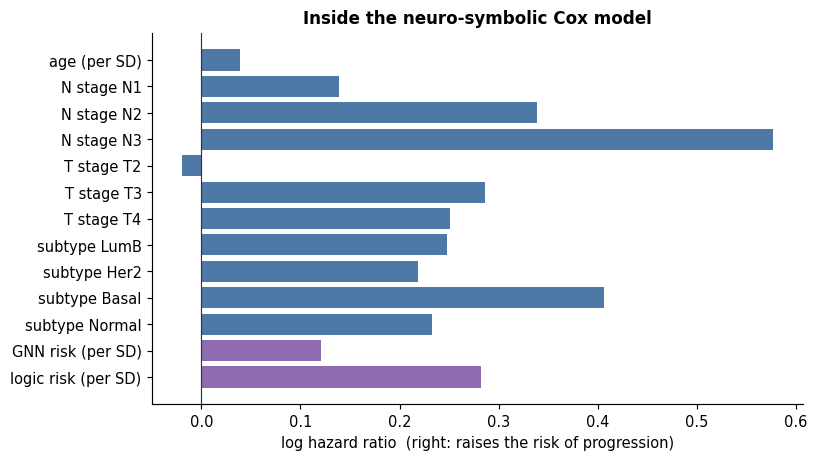

Hazard ratio per SD: GNN risk 1.13, logic risk 1.33


In [34]:
# Final fusion model on the whole cohort (used for the reports): what does each piece contribute?
NS_SCALER = Standardizer().fit(NS_X)
NS_W = fit_cox(NS_SCALER.transform(NS_X), TIME, EVENT, ridge=FUSION_RIDGE)
NS_ETA = NS_SCALER.transform(NS_X) @ NS_W
BASE_T, BASE_H = breslow_baseline(TIME, EVENT, NS_ETA)
hr = pd.DataFrame({"term": NS_NAMES, "hazard ratio": np.exp(NS_W / NS_SCALER.std)}).set_index("term")
fig, ax = plt.subplots(figsize=(8, 4.6))
cols = ["#8e6bb0" if "risk" in t else "#4e79a7" for t in hr.index]
ax.barh(hr.index[::-1], np.log(hr["hazard ratio"])[::-1], color=cols[::-1])
ax.axvline(0, color="#333", lw=0.8)
ax.set_xlabel("log hazard ratio  (right: raises the risk of progression)"); ax.set_title("Inside the neuro-symbolic Cox model")
plt.show()
print(f"Hazard ratio per SD: GNN risk {hr.iloc[-2, 0]:.2f}, logic risk {hr.iloc[-1, 0]:.2f}")

**What you are seeing.** On this toy cohort part of the hidden mechanism lives in PrimeKG pathways, which the clinical table cannot see.
Compare *Survival MLN (no PrimeKG)* with *Survival MLN*: the only difference is the PrimeKG atoms, and the knowledge-graph version ranks patients better. The neuro-symbolic Cox model, which combines clinical, neural and logic evidence, also scores above the clinical-only model.
Keep the scale in mind, though: the gaps are of the order of one fold-standard-deviation (printed above). The main reason to fuse is what comes next: **an explanation that uses both halves**.

> 🧪 **Honesty box: the real project.** On the real TCGA cohort (1,083 patients, only 145 progressions) *every* model family saturates near a C-index of **0.67**. The neuro-symbolic Cox model (0.664 ± 0.021) is statistically tied with the clinical Cox model (0.675 ± 0.035) under the one-standard-error rule.
> There, the neural and logic parts add **explanation, not accuracy**. The toy data here was built so that the mechanism is visible, not to make a performance claim.

---
# Step 8 · The neuro-symbolic explanation 🔍 (the crux)

A risk number alone does not help a clinician. The project explains each prediction with **paths in the patient's fused graph**, for example

`Patient → Sample → MYC (amplified) → Cell cycle G1/S`

Every candidate path is a real walk over stored edges (`patient → sample → altered gene → (partner gene) → pathway / drug / disease`). Each path gets two scores:

* 🧠 **neural score**: how much the GNN relied on the path's edges (GNNExplainer mask, as a percentile over all paths);
* 📜 **rule score**: the summed weight of the learned logic formulas that **fire for this patient and are grounded by this path**: the path passes through the formula's altered gene `g` and, for a PrimeKG atom such as `Altered(p,g) ∧ InPathway(g,w)`, ends at the pathway / drug / disease `w` it names.
  Scaled to 0–1 by its magnitude; its sign says *faster* or *slower* progression.

$$\boxed{\text{NS score} = 0.6 \times \text{neural} + 0.4 \times \text{rule}}$$

The neural half says *where the network looked*. The symbolic half says *which validated, weighted rule that evidence instantiates*. Together they give an explanation that is **faithful to the model** and **readable**.

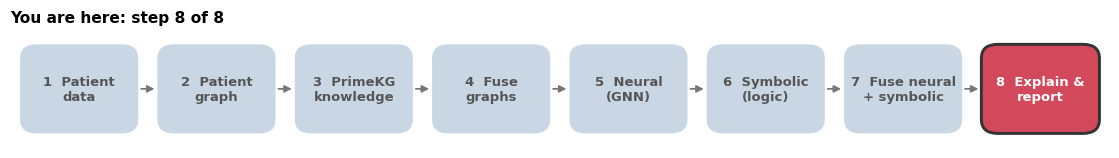

In [35]:
roadmap(8)

In [36]:
NEURAL_WEIGHT, RULE_WEIGHT = 0.6, 0.4

def candidate_paths(F):
    # Every walk patient -> sample -> altered gene -> (partner) -> pathway/drug/disease.
    root = next(n for n, d in F.nodes(data=True) if d["type"] == "patient")
    found, seen = [], set()
    def walk(node, nodes, rels):
        for _, nxt, rel in F.out_edges(node, data="relation"):
            if nxt in nodes:
                continue
            kind = F.nodes[nxt]["type"]
            if kind in ("pathway", "drug", "disease") and tuple(nodes + [nxt]) not in seen:
                seen.add(tuple(nodes + [nxt])); found.append((nodes + [nxt], rels + [rel]))
            elif kind in ("sample", "gene") and len(nodes) < 4:
                walk(nxt, nodes + [nxt], rels + [rel])
    walk(root, [root], [])
    return found

def fired_formulas(weights, atom_vector):
    out = []
    for f in weights.itertuples():
        if all(atom_vector[a] > 0 for a in f.atoms):
            out.append((f.atoms, f.weight, f.formula))
    return out

def grounded_by(atom, end, altered):
    # Is this path one of the atom's true groundings?
    if atom["kind"] == "genomic":                 # Mutated(p, g): the path goes through altered gene g
        return bool(atom["genes"] & altered)
    if atom["kind"].startswith("kg_"):            # Altered(p, g) ∧ InPathway(g, w): through altered g, ending at w
        return end in atom["members"] and bool(atom["genes"] & altered)
    return False                                  # clinical atoms are about the patient, not a path

def path_rule(F, nodes, fired, atom_vector):
    # Sum of the weights of fired formulas grounded by this path.
    end = nodes[-1]
    altered = {F.nodes[n]["label"] for n in nodes if F.nodes[n]["type"] == "gene" and F.nodes[n].get("altered")}
    hits = [(w, text) for atoms, w, text in fired if any(grounded_by(ATOMS[a], end, altered) for a in atoms)]
    return sum(w for w, _ in hits), (max(hits, key=lambda h: abs(h[0]))[1] if hits else ""), len(hits)

def path_text(F, nodes):
    parts = []
    for n in nodes[1:]:
        d = F.nodes[n]
        if d["type"] == "gene":
            flags = [w for w, k in (("mutated", "mut"), ("amplified", "amp"), ("deleted", "dele")) if d.get(k)]
            parts.append(f"{d['label']} ({', '.join(flags) if flags else 'partner'})")
        elif d["type"] != "sample":
            parts.append(f"{d['label']} [{d['type']}]")
    return "Patient → " + " → ".join(parts)

def score_paths(F, mask, weights, atom_vector):
    fired = fired_formulas(weights, atom_vector)
    rows = []
    for nodes, rels in candidate_paths(F):
        edge_scores = [mask.get((u, v), 0.0) for u, v in zip(nodes[:-1], nodes[1:])]
        rule, rule_text, n_rules = path_rule(F, nodes, fired, atom_vector)
        rows.append(dict(path=path_text(F, nodes), nodes=nodes, gene=next(F.nodes[n]["label"] for n in nodes if F.nodes[n]["type"] == "gene"),
                         end=nodes[-1], neural_raw=float(np.mean(edge_scores)), rule_score=rule, rule_formula=rule_text, n_rules=n_rules))
    columns = ["path", "nodes", "gene", "end", "neural_raw", "rule_score", "rule_formula", "n_rules"]
    return pd.DataFrame(rows, columns=columns), fired

# Calibrate the two scales on a reference pool of out-of-fold explanations (neural percentile, rule magnitude).
weights_of = lambda k: ENGINE_WEIGHTS[k].rename(columns={"weight_per_sd": "weight"})
pool_ids = [demo_i] + list(np.random.default_rng(3).choice([i for i in range(len(PIDS)) if i != demo_i], 9, replace=False))
POOL = {}
for i in pool_ids:
    k = FOLD_OF[i]
    mask = DEMO_MASK if i == demo_i else explain_edges(FOLD_MODELS[k], ENCODED[i])
    POOL[i] = (mask, score_paths(FUSED[PIDS[i]], mask, weights_of(k), ATOM_VALUES[i])[0])
NEURAL_REF = np.sort(np.concatenate([p["neural_raw"].to_numpy() for _, p in POOL.values()]))
# the rule half needs no GNN, so its scale is taken over every path of every patient
rule_mags = np.abs(np.concatenate([score_paths(FUSED[p], {}, weights_of(FOLD_OF[i]), ATOM_VALUES[i])[0]["rule_score"].to_numpy()
                                   for i, p in enumerate(PIDS)]))
RULE_SCALE = float(np.quantile(rule_mags[rule_mags > 0], 0.95)) if (rule_mags > 0).any() else 1.0

def finish_scores(paths):
    paths = paths.copy()
    paths["neural"] = np.searchsorted(NEURAL_REF, paths["neural_raw"], side="right") / len(NEURAL_REF)
    paths["rule"] = np.clip(np.abs(paths["rule_score"]) / RULE_SCALE, 0, 1)
    paths["ns_score"] = NEURAL_WEIGHT * paths["neural"] + RULE_WEIGHT * paths["rule"]
    paths["direction"] = np.where(paths["rule_score"] > 0, "↑ faster progression", np.where(paths["rule_score"] < 0, "↓ slower progression", "no rule fires"))
    return paths

def top_paths(paths, k=5, per_gene=2, key="ns_score"):
    # best k paths, at most two through the same altered gene, each end node once
    chosen, genes, ends = [], defaultdict(int), set()
    for r in paths.sort_values(key, ascending=False).itertuples():
        if genes[r.gene] >= per_gene or r.end in ends:
            continue
        chosen.append(r.Index); genes[r.gene] += 1; ends.add(r.end)
        if len(chosen) == k:
            break
    return paths.loc[chosen].reset_index(drop=True)

DEMO_PATHS = finish_scores(POOL[demo_i][1])
DEMO_TOP = top_paths(DEMO_PATHS)
print(f"{DEMO}: {len(DEMO_PATHS)} candidate paths; {int((DEMO_PATHS.n_rules > 0).sum())} of them ground at least one fired formula.")
display(DEMO_TOP[["path", "neural", "rule", "ns_score", "direction", "rule_formula"]].rename(columns={"ns_score": "NS score"}).round(3))

TOY-0162: 35 candidate paths; 30 of them ground at least one fired formula.


,path,neural,rule,NS score,direction,rule_formula
0,Patient → MYC (amplified) → CCND1 (partner) → Cell cycle G1/S [pathway],0.994,1.000,0.997,↑ faster progression,"Altered(p, g) ∧ InPathway(g, 'Cell cycle G1/S') ⇒ Progress(p)"
1,Patient → MYC (amplified) → MAP3K1 (partner) → MAPK signaling [pathway],0.989,0.874,0.943,↑ faster progression,"Subtype(p, Basal) ∧ Amplified(p, MYC) ⇒ Progress(p)"
2,Patient → TP53 (mutated) → Li-Fraumeni syndrome [disease],0.732,0.783,0.752,↑ faster progression,"Subtype(p, Basal) ∧ Altered(p, g) ∧ LinkedTo(g, 'Li-Fraumeni syndrome') ∧ Altered(p, g) ∧ InPathway(g, 'DN..."
3,Patient → TP53 (mutated) → BRCA1 (mutated) → DNA double-strand break repair [pathway],0.620,0.732,0.665,↑ faster progression,"Subtype(p, Basal) ∧ Altered(p, g) ∧ LinkedTo(g, 'Li-Fraumeni syndrome') ∧ Altered(p, g) ∧ InPathway(g, 'DN..."
4,Patient → BRCA1 (mutated) → breast carcinoma [disease],0.709,0.226,0.516,↑ faster progression,"Altered(p, g) ∧ LinkedTo(g, 'breast carcinoma') ∧ Altered(p, g) ∧ InPathway(g, 'PI3K-Akt signaling') ∧ Alt..."


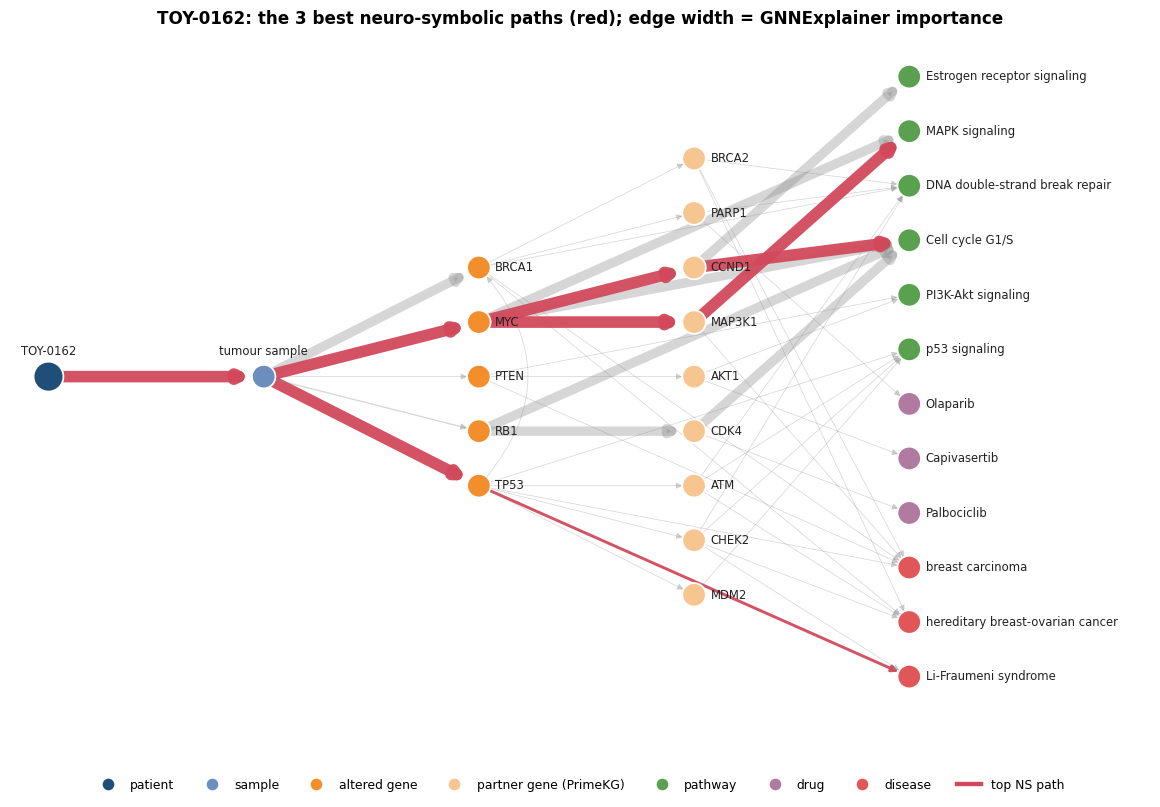

In [37]:
#@title 🔦 The top paths, highlighted in the patient's fused graph
hl = {(u, v) for nodes in DEMO_TOP["nodes"][:3] for u, v in zip(nodes[:-1], nodes[1:])}
fig, ax = plt.subplots(figsize=(14, 8.5))
draw_graph(F_demo, ax, pos=pos_demo, edge_strength=DEMO_MASK, highlight=hl, font=8,
           title=f"{DEMO}: the 3 best neuro-symbolic paths (red); edge width = GNNExplainer importance")
type_legend(ax, [Line2D([], [], color=RISK_RED, lw=3, label="top NS path")]); plt.show()

### Neural-only vs symbolic-only vs neuro-symbolic

The clearest way to see what the combination buys is to rank the same candidate paths three ways.
On the left, paths ranked by the GNN alone; in the middle, the formulas that fire, which are true but not tied to this patient's graph; on the right, the fused ranking.
The slope chart shows how adding the rule score **re-orders** the GNN's ranking and promotes paths backed by a validated rule.

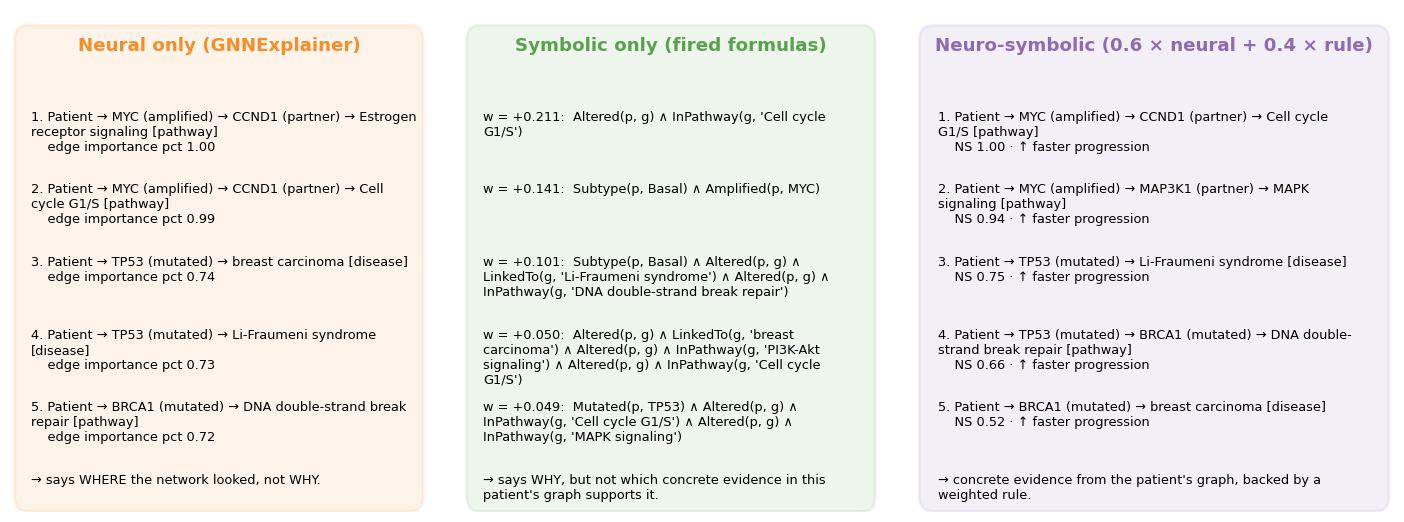

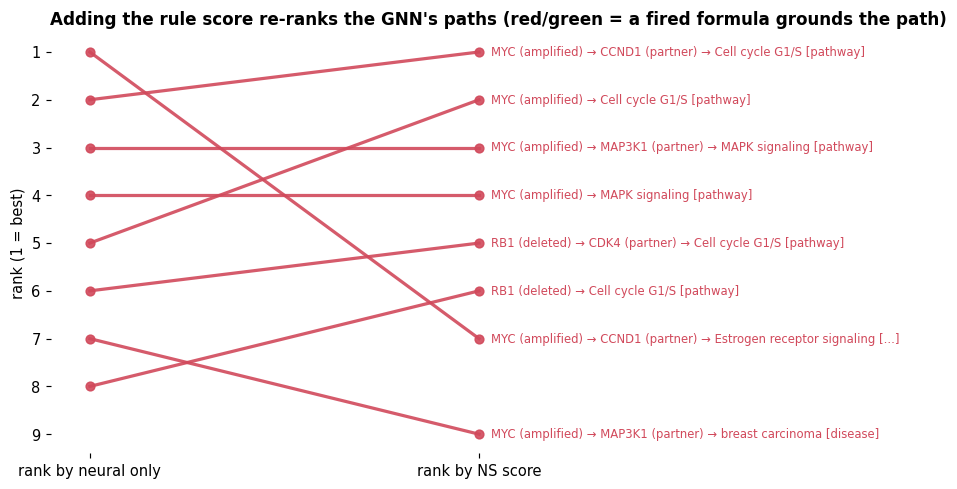

In [38]:
by_neural = DEMO_PATHS.sort_values("neural", ascending=False).reset_index(drop=True)
top_neural = top_paths(DEMO_PATHS, key="neural")          # same diversity rule as the NS list, so the comparison is fair
by_ns = DEMO_PATHS.sort_values("ns_score", ascending=False).reset_index(drop=True)
fired_demo = sorted(fired_formulas(weights_of(FOLD_OF[demo_i]), ATOM_VALUES[demo_i]), key=lambda f: -abs(f[1]))

fig = plt.figure(figsize=(17, 6.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.15], wspace=0.08)
def panel(ax, title, color, lines):
    ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.add_patch(FancyBboxPatch((0.01, 0.0), 0.98, 0.97, boxstyle="round,pad=0.0,rounding_size=0.03", fc=color, alpha=0.1, ec=color, lw=2))
    ax.text(0.5, 0.92, title, ha="center", fontsize=12.5, fontweight="bold", color=color)
    for i, line in enumerate(lines):
        ax.text(0.05, 0.8 - i * 0.145, line, fontsize=8.8, va="top", wrap=True)
wrap = lambda s, n=58: "\n".join(textwrap.wrap(s, n))
panel(fig.add_subplot(gs[0]), "Neural only (GNNExplainer)", "#f28e2b",
      [wrap(f"{i + 1}. {r.path}") + f"\n    edge importance pct {r.neural:.2f}" for i, r in enumerate(top_neural.head(5).itertuples())]
      + [wrap("→ says WHERE the network looked, not WHY.")])
panel(fig.add_subplot(gs[1]), "Symbolic only (fired formulas)", "#59a14f",
      [wrap(f"w = {w:+.3f}:  {t.replace(' ⇒ Progress(p)', '')}") for _, w, t in fired_demo[:5]]
      + [wrap("→ says WHY, but not which concrete evidence in this patient's graph supports it.")])
panel(fig.add_subplot(gs[2]), "Neuro-symbolic (0.6 × neural + 0.4 × rule)", "#8e6bb0",
      [wrap(f"{i + 1}. {r.path}", 62) + f"\n    NS {r.ns_score:.2f} · {r.direction}" for i, r in enumerate(DEMO_TOP.head(5).itertuples())]
      + [wrap("→ concrete evidence from the patient's graph, backed by a weighted rule.", 62)])
plt.show()

fig, ax = plt.subplots(figsize=(11, 5.2))
show_paths = list(dict.fromkeys(list(by_neural.path[:7]) + list(by_ns.path[:7])))
rank_n = {p: i + 1 for i, p in enumerate(by_neural.path)}; rank_s = {p: i + 1 for i, p in enumerate(by_ns.path)}
for p in show_paths:
    r = DEMO_PATHS.set_index("path").loc[p]
    col = RISK_RED if r.rule_score > 0 else SAFE_GREEN if r.rule_score < 0 else GREY
    ax.plot([0, 1], [rank_n[p], rank_s[p]], "-o", color=col, lw=2.2 if r.rule_score != 0 else 1.2, alpha=0.9)
    ax.text(1.03, rank_s[p], textwrap.shorten(p.replace("Patient → ", ""), 70), va="center", fontsize=8, color=col)
ax.set_xlim(-0.1, 2.2); ax.invert_yaxis(); ax.set_xticks([0, 1]); ax.set_xticklabels(["rank by neural only", "rank by NS score"], fontsize=10)
ax.set_ylabel("rank (1 = best)"); ax.spines["left"].set_visible(False); ax.spines["bottom"].set_visible(False)
ax.set_title("Adding the rule score re-ranks the GNN's paths (red/green = a fired formula grounds the path)")
plt.show()

### 📄 The patient report card

The real project writes a hospital-style **PDF report for every patient**, grouped by the recorded progression timeline (A ≤ 12 months, B 12–24, C 24–36, D > 36, N = no progression).
Below is a one-page version built from everything above: the clinical record, the neuro-symbolic risk and survival curve, the top knowledge-graph paths, and the formulas that fired.

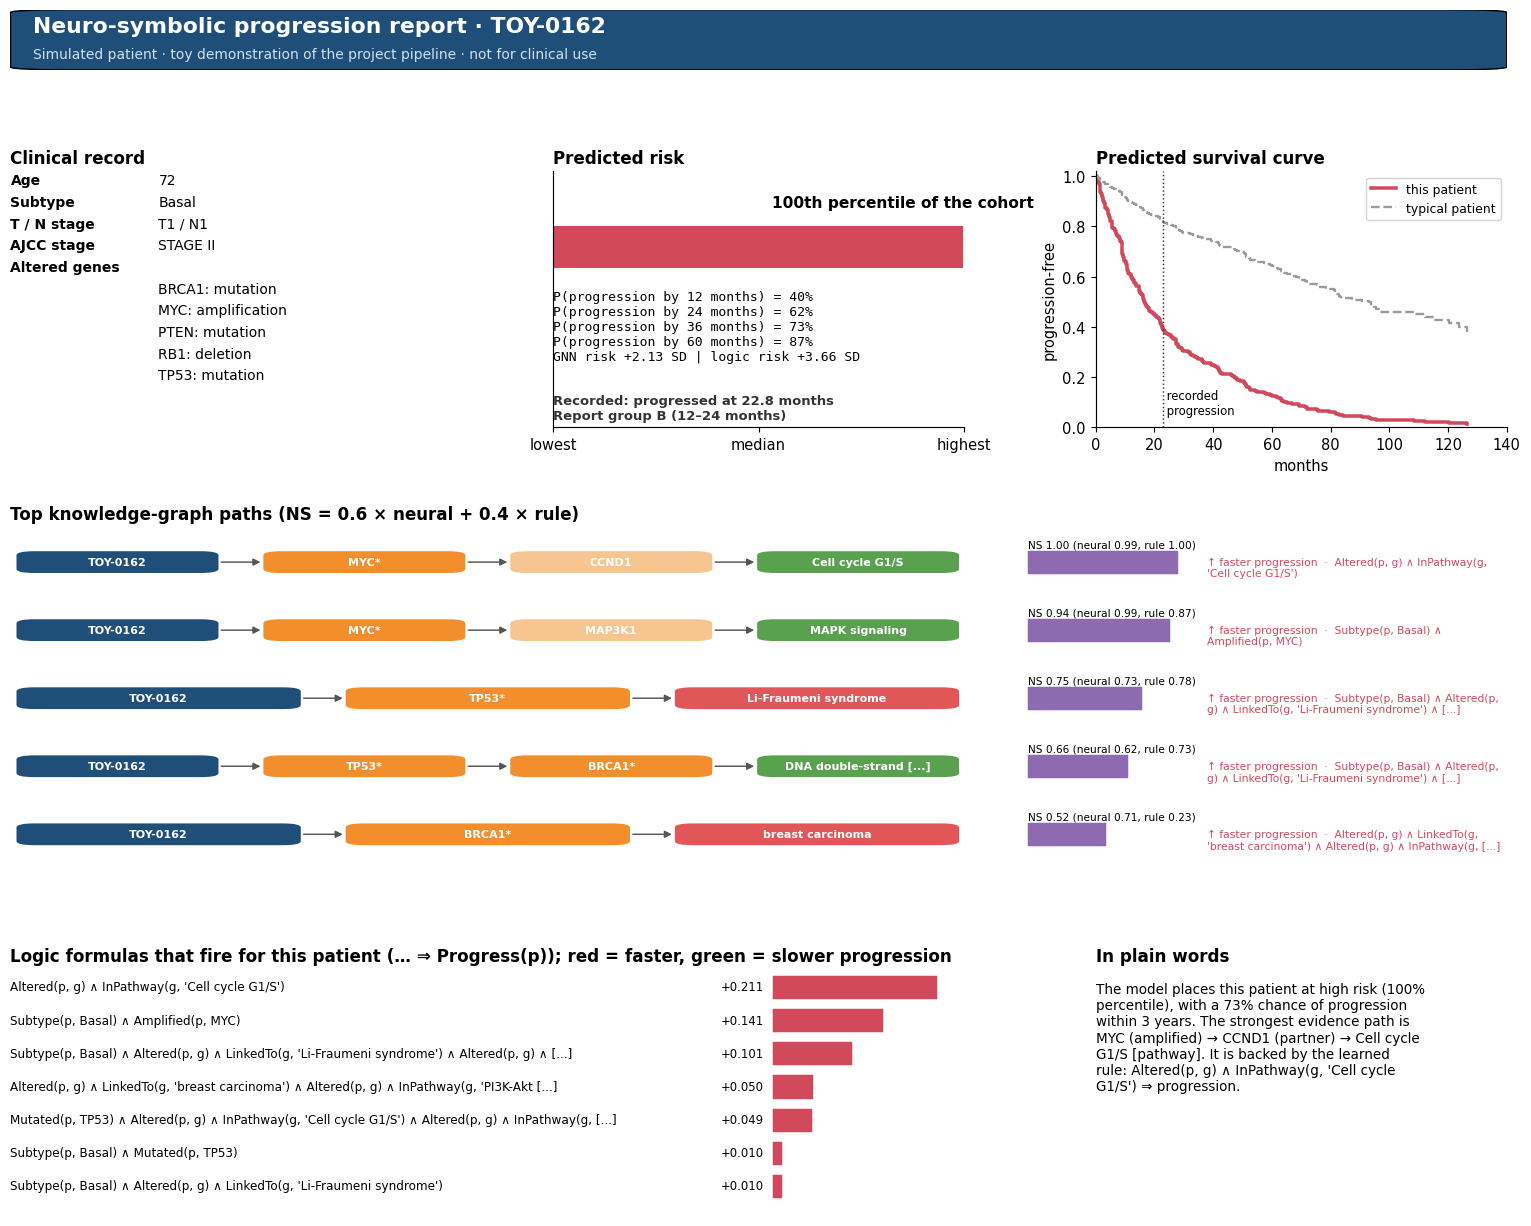

In [39]:
#@title 🧾 Report-card builder { display-mode: "form" }
def timeline_group(event, months):
    if not event: return "N (no progression recorded)"
    return "A (≤ 12 months)" if months <= 12 else "B (12–24 months)" if months <= 24 else "C (24–36 months)" if months <= 36 else "D (> 36 months)"

def survival_curve(eta):
    return np.r_[0.0, BASE_T], np.r_[1.0, np.exp(-BASE_H * np.exp(eta))]

def analyse_cohort_patient(pid):
    i = PIDS.index(pid); k = FOLD_OF[i]
    mask, raw_paths = POOL[i] if i in POOL else (explain_edges(FOLD_MODELS[k], ENCODED[i]), None)
    if raw_paths is None:
        raw_paths = score_paths(FUSED[pid], mask, weights_of(k), ATOM_VALUES[i])[0]
    eta = float(NS_SCALER.transform(NS_X[i:i + 1]) @ NS_W)
    return dict(pid=pid, record=clinical.loc[pid], F=FUSED[pid], mask=mask, eta=eta, gnn=zs(GNN_OOF)[i],
                logic=zs(OOF["RL-structured MLN"])[i], paths=top_paths(finish_scores(raw_paths)),
                fired=fired_formulas(weights_of(k), ATOM_VALUES[i]), recorded=(int(EVENT[i]), float(TIME[i])))

def draw_chain(ax, y, F, nodes, x0=0.0, width=0.66):
    steps = [n for n in nodes if F.nodes[n]["type"] != "sample"]
    w = width / len(steps)
    for j, n in enumerate(steps):
        d = F.nodes[n]
        color = node_color(d)
        label = d["label"] if d["type"] != "gene" else d["label"] + ("*" if d.get("altered") else "")
        ax.add_patch(FancyBboxPatch((x0 + j * w + 0.004, y - 0.032), w - 0.03, 0.064, boxstyle="round,pad=0.0,rounding_size=0.012",
                                    fc=color, ec="none", transform=ax.transAxes))
        ax.text(x0 + j * w + (w - 0.022) / 2, y, textwrap.shorten(label, 26), ha="center", va="center", fontsize=7.6,
                color="white", fontweight="bold", transform=ax.transAxes)
        if j < len(steps) - 1:
            ax.annotate("", xy=(x0 + (j + 1) * w + 0.004, y), xytext=(x0 + (j + 1) * w - 0.026, y), xycoords="axes fraction",
                        arrowprops=dict(arrowstyle="-|>", color="#555", lw=1))

def report_card(res):
    rec, (ev, months) = res["record"], res["recorded"]
    pct = (NS_ETA < res["eta"]).mean()
    t, s = survival_curve(res["eta"]); _, s_avg = survival_curve(np.median(NS_ETA))
    prob = {m: 1 - s[np.searchsorted(t, m, side="right") - 1] if (t <= m).any() else 0.0 for m in (12, 24, 36, 60)}
    n_paths = max(len(res["paths"].head(5)), 1)
    fig = plt.figure(figsize=(15, 9.6 + 0.55 * n_paths))
    gs = fig.add_gridspec(4, 3, height_ratios=[0.32, 1.35, 0.32 * n_paths + 0.2, 1.3], hspace=0.45, wspace=0.32,
                          left=0.03, right=0.98, top=0.97, bottom=0.04)
    head = fig.add_subplot(gs[0, :]); head.axis("off")
    head.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0.0,rounding_size=0.05", fc="#1f4e79", transform=head.transAxes))
    head.text(0.015, 0.62, f"Neuro-symbolic progression report · {res['pid']}", color="white", fontsize=15, fontweight="bold", transform=head.transAxes)
    head.text(0.015, 0.2, "Simulated patient · toy demonstration of the project pipeline · not for clinical use", color="#cfe0f1", fontsize=9.5, transform=head.transAxes)

    ax = fig.add_subplot(gs[1, 0]); ax.axis("off"); ax.set_title("Clinical record", loc="left")
    genes = defaultdict(list)
    for _, v, d in res["F"].out_edges(f"sample:{res['pid']}-01", data=True):
        genes[res["F"].nodes[v]["label"]].append(SHORT_REL[d["relation"]])
    lines = [("Age", f"{int(rec.AGE)}"), ("Subtype", rec.SUBTYPE), ("T / N stage", f"{rec.PATH_T_STAGE} / {rec.PATH_N_STAGE}"),
             ("AJCC stage", rec.AJCC_PATHOLOGIC_TUMOR_STAGE)] + \
            [("Altered genes", "")] + [("", f"{g}: {', '.join(v)}") for g, v in sorted(genes.items())]
    for j, (a, b) in enumerate(lines[:12]):
        ax.text(0.0, 0.95 - j * 0.085, a, fontsize=9.5, fontweight="bold", transform=ax.transAxes)
        ax.text(0.36, 0.95 - j * 0.085, b, fontsize=9.5, transform=ax.transAxes)

    ax = fig.add_subplot(gs[1, 1]); ax.set_title("Predicted risk", loc="left")
    ax.barh([0], [1], color="#eeeeee", height=0.45)
    ax.barh([0], [pct], color=RISK_RED if pct > 0.66 else "#f1a340" if pct > 0.33 else SAFE_GREEN, height=0.45)
    rank = int(round(100 * pct))
    suffix = "th" if 10 <= rank % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(rank % 10, "th")
    ax.text(min(max(pct, 0.15), 0.85), 0.42, f"{rank}{suffix} percentile of the cohort", ha="center", fontsize=10.5, fontweight="bold")
    ax.set_xlim(0, 1); ax.set_ylim(-1.9, 0.8); ax.set_yticks([]); ax.set_xticks([0, 0.5, 1]); ax.set_xticklabels(["lowest", "median", "highest"])
    txt = "\n".join([f"P(progression by {m:>2} months) = {p:.0%}" for m, p in prob.items()]
                    + [f"GNN risk {res['gnn']:+.2f} SD | logic risk {res['logic']:+.2f} SD"])
    ax.text(0.0, -0.45, txt, fontsize=9, va="top", family="monospace")
    if ev is not None:
        ax.text(0.0, -1.55, f"Recorded: {'progressed at ' + str(months) + ' months' if ev else 'no progression in ' + str(months) + ' months'}"
                f"\nReport group {timeline_group(ev, months)}", fontsize=9, fontweight="bold", color="#333", va="top")

    ax = fig.add_subplot(gs[1, 2])
    ax.step(t, s, where="post", color=RISK_RED, lw=2.4, label="this patient")
    ax.step(t, s_avg, where="post", color=GREY, lw=1.6, ls="--", label="typical patient")
    if ev:
        ax.axvline(months, color="#333", ls=":", lw=1); ax.text(months, 0.05, " recorded\n progression", fontsize=8)
    ax.set_ylim(0, 1.02); ax.set_xlim(0, 140); ax.set_xlabel("months"); ax.set_ylabel("progression-free")
    ax.set_title("Predicted survival curve", loc="left"); ax.legend(fontsize=8.5)

    ax = fig.add_subplot(gs[2, :]); ax.axis("off"); ax.set_title("Top knowledge-graph paths (NS = 0.6 × neural + 0.4 × rule)", loc="left")
    for j, r in enumerate(res["paths"].head(5).itertuples()):
        y = 1 - (j + 0.5) / n_paths
        draw_chain(ax, y, res["F"], r.nodes)
        col = RISK_RED if r.rule_score > 0 else SAFE_GREEN if r.rule_score < 0 else GREY
        h = 0.32 / n_paths
        ax.add_patch(plt.Rectangle((0.68, y - h / 2), 0.1 * r.ns_score, h, color="#8e6bb0", transform=ax.transAxes))
        ax.text(0.68, y + h / 2 + 0.01, f"NS {r.ns_score:.2f} (neural {r.neural:.2f}, rule {r.rule:.2f})", fontsize=7.2, transform=ax.transAxes)
        reason = textwrap.shorten(r.rule_formula.replace(" ⇒ Progress(p)", ""), 88) if r.rule_formula else ""
        ax.text(0.80, y - h / 4, textwrap.fill(r.direction + ("  ·  " + reason if reason else ""), 56),
                fontsize=7.4, va="center", color=col, transform=ax.transAxes)

    ax = fig.add_subplot(gs[3, :2]); ax.axis("off")
    ax.set_title("Logic formulas that fire for this patient (… ⇒ Progress(p)); red = faster, green = slower progression", loc="left")
    fired = sorted(res["fired"], key=lambda f: -abs(f[1]))[:7]
    biggest = max([abs(w) for _, w, _ in fired] or [1.0])
    for j, (_, w, t) in enumerate(fired):
        y = 0.93 - j * 0.135
        ax.text(0.0, y, textwrap.shorten(t.replace(" ⇒ Progress(p)", ""), 105), fontsize=8.2, va="center", transform=ax.transAxes)
        ax.add_patch(plt.Rectangle((0.8, y - 0.045), 0.17 * abs(w) / biggest, 0.09, color=RISK_RED if w > 0 else SAFE_GREEN, transform=ax.transAxes))
        ax.text(0.79, y, f"{w:+.3f}", fontsize=8, va="center", ha="right", transform=ax.transAxes)
    if not fired:
        ax.text(0, 0.8, "No learned formula fires for this patient.", fontsize=9, transform=ax.transAxes)

    ax = fig.add_subplot(gs[3, 2]); ax.axis("off"); ax.set_title("In plain words", loc="left")
    level = "high" if pct > 0.66 else "intermediate" if pct > 0.33 else "low"
    best = res["paths"].iloc[0] if len(res["paths"]) else None
    pos_f = [t for _, w, t in sorted(res["fired"], key=lambda f: -f[1]) if w > 0][:1]
    story = (f"The model places this patient at {level} risk ({pct:.0%} percentile), with a {prob[36]:.0%} chance of progression within 3 years. "
             + (f"The strongest evidence path is {best.path.replace('Patient → ', '')}. " if best is not None else "")
             + (f"It is backed by the learned rule: {pos_f[0].replace(' ⇒ Progress(p)', '')} ⇒ progression." if pos_f else "No risk-raising rule fires."))
    ax.text(0, 0.95, textwrap.fill(story, 48), fontsize=9.3, va="top", transform=ax.transAxes)
    plt.show()

report_card(analyse_cohort_patient(DEMO))

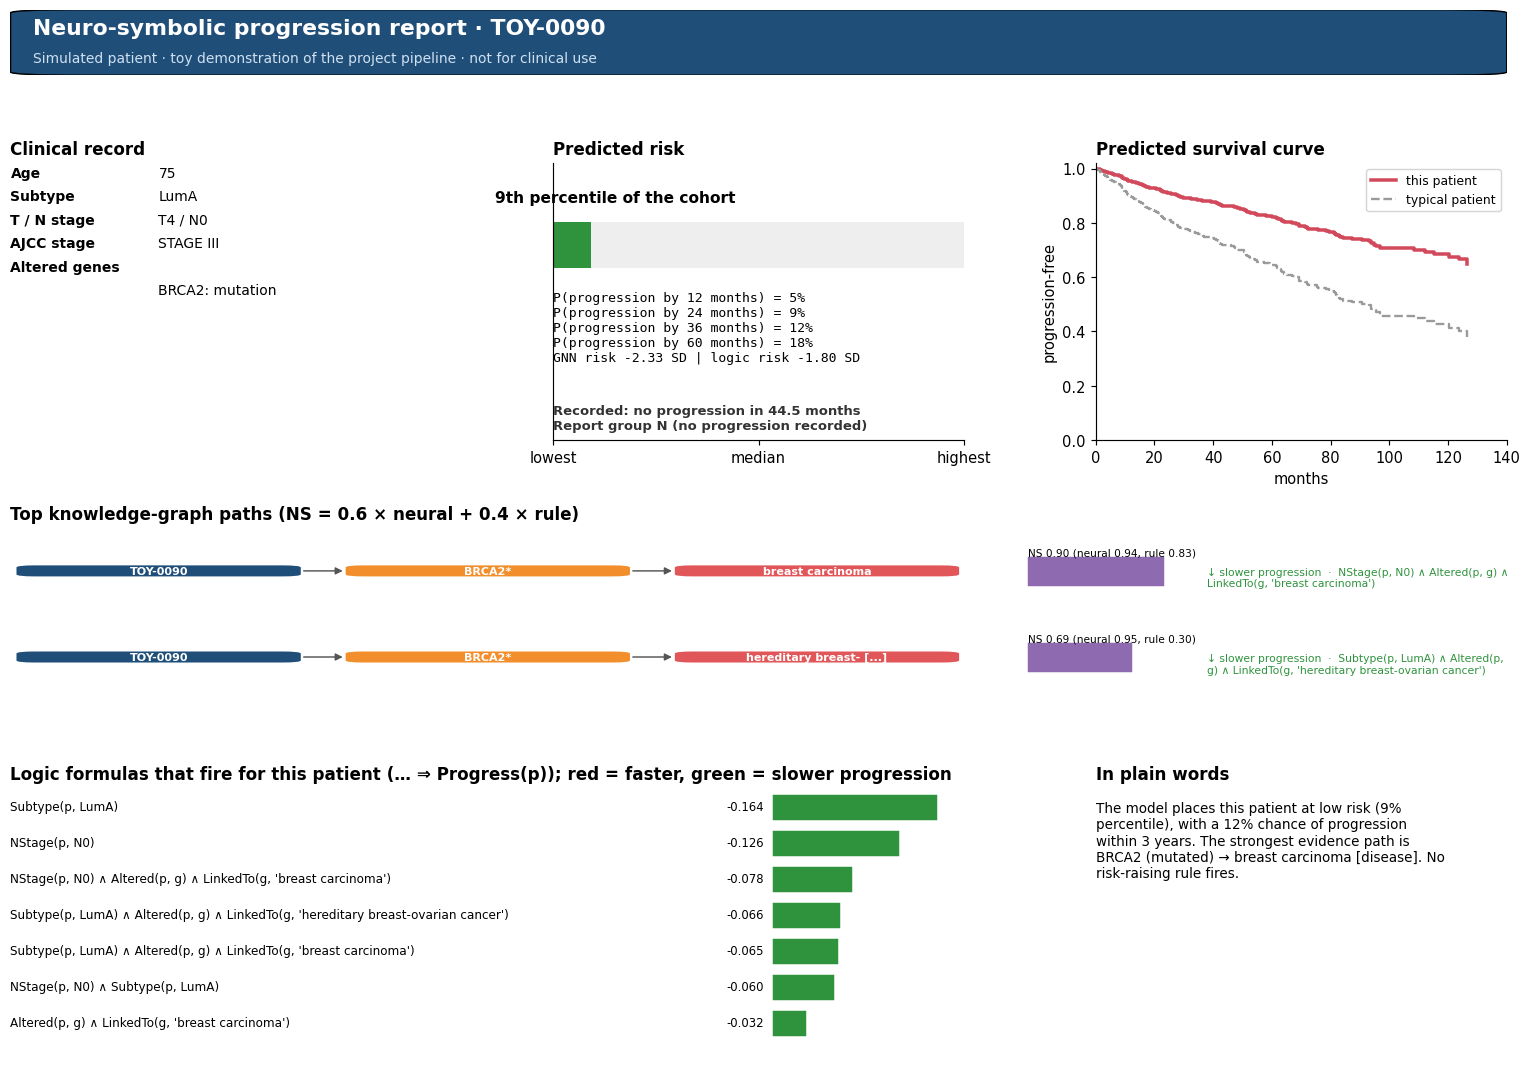

In [40]:
# For contrast: a patient the model considers low risk
low_candidates = [PIDS[i] for i in pool_ids if NS_ETA[i] < np.quantile(NS_ETA, 0.25)]
CONTRAST = low_candidates[0] if low_candidates else PIDS[int(np.argmin(NS_ETA))]
report_card(analyse_cohort_patient(CONTRAST))

---
# 🧪 Try it yourself: a brand-new patient

Edit the dictionary below and re-run the cell: change the stage, the subtype, or the altered genes (any of the 24 panel genes) and watch the risk, the paths and the fired rules change.
A new patient goes through the **same pipeline**: patient graph → PrimeKG fusion → GNN (average of the 5 fold models) → ground atoms → logic engine (average of the 5 folds' formulas) → neuro-symbolic Cox → explanation.

Panel genes: `TP53`, `PIK3CA`, `ERBB2`, `ESR1`, `GATA3`, `CDH1`, `MAP3K1`, `KMT2C`, `PTEN`, `AKT1`, `MTOR`, `EGFR`, `FGFR1`, `MYC`, `CCND1`, `CDK4`, `RB1`, `CDKN2A`, `MDM2`, `BRCA1`, `BRCA2`, `ATM`, `CHEK2`, `PARP1`

In [41]:
#@title 🧩 Pipeline for a new patient (run once)
class FoldEnsemble(nn.Module):
    def __init__(self, models):
        super().__init__(); self.models = nn.ModuleList(models)
    def forward(self, b, edge_weight=None):
        return torch.stack([m(b, edge_weight) for m in self.models]).mean(0)
ENSEMBLE = FoldEnsemble(FOLD_MODELS).eval()
CONSENSUS_WEIGHTS = CONSENSUS.reset_index().rename(columns={"mean_weight": "weight"})[["formula", "atoms", "weight"]]

def analyse_new_patient(spec):
    pid = spec.get("id", "NEW-001")
    rec = pd.Series({"AGE": spec["age"], "SUBTYPE": spec["subtype"], "PATH_T_STAGE": spec["t_stage"], "PATH_N_STAGE": spec["n_stage"],
                     "AJCC_PATHOLOGIC_TUMOR_STAGE": _ajcc(spec["t_stage"], spec["n_stage"])})
    rows = [(pid, f"{pid}-01", g, PANEL[g], kind, kind) for kind, key in (("mut", "mutations"), ("amp", "amplifications"), ("del", "deletions"))
            for g in spec.get(key, [])]
    alt = pd.DataFrame(rows, columns=["patient_id", "sample_id", "gene", "entrez", "kind", "detail"])
    F = fuse(patient_graph(pid, rec, alt))                                   # steps 2-4
    enc = encode(F)
    with torch.no_grad():                                                     # step 5
        gnn_raw = float(ENSEMBLE(collate([enc])))
    atoms = atom_values(patient_context(rec, alt))                            # step 6
    logic_raw = float(np.mean([m.predict(atoms[None, :])[0] for m in MLN_MODELS]))
    x = np.r_[clinical_design(rec), (gnn_raw - GNN_OOF.mean()) / GNN_OOF.std(),
              (logic_raw - OOF["RL-structured MLN"].mean()) / OOF["RL-structured MLN"].std()]
    eta = float(NS_SCALER.transform(x[None, :]) @ NS_W)                       # step 7
    mask = explain_edges(ENSEMBLE, enc)                                       # step 8
    paths = score_paths(F, mask, CONSENSUS_WEIGHTS, atoms)[0]
    return dict(pid=pid, record=rec, F=F, mask=mask, eta=eta, gnn=x[-2], logic=x[-1], paths=top_paths(finish_scores(paths)),
                fired=fired_formulas(CONSENSUS_WEIGHTS, atoms), recorded=(None, None))
print("Ready ✅")

Ready ✅


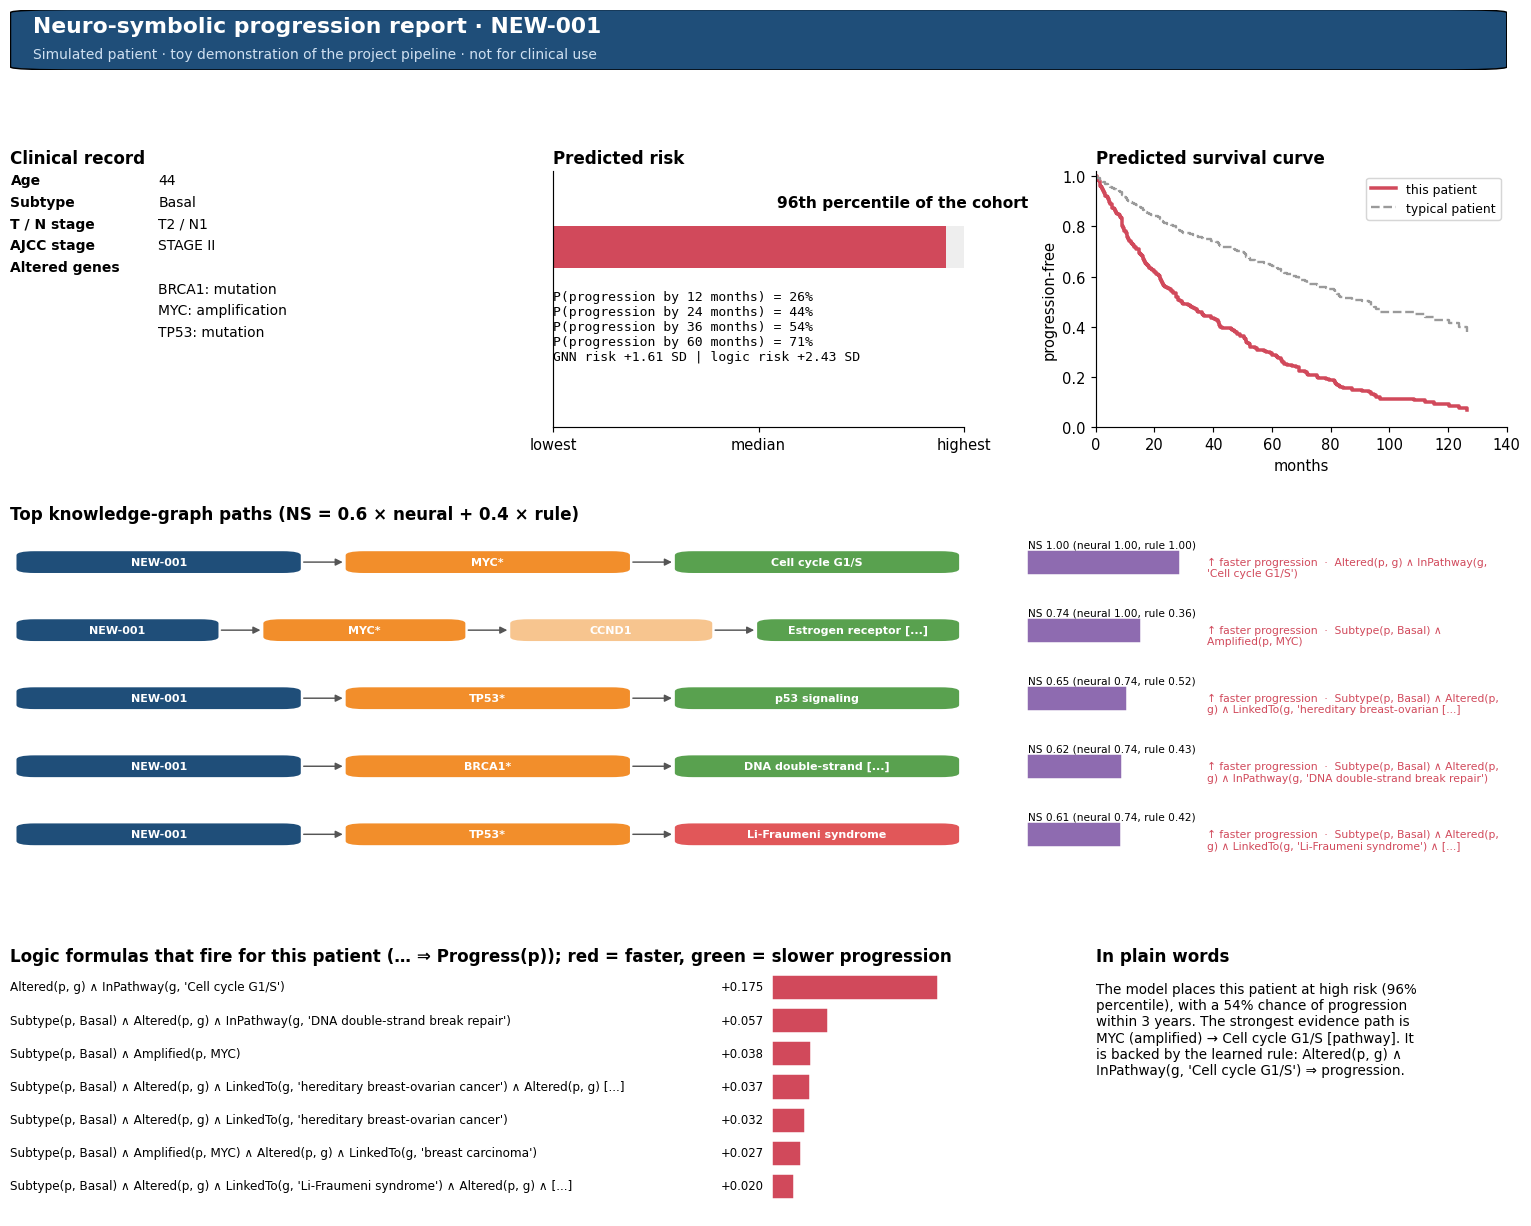

In [42]:
NEW_PATIENT = {
    "id": "NEW-001",
    "age": 44,
    "subtype": "Basal",          # LumA, LumB, Her2, Basal, Normal
    "t_stage": "T2",             # T1 … T4
    "n_stage": "N1",             # N0 … N3
    "mutations": ["TP53", "BRCA1"],
    "amplifications": ["MYC"],
    "deletions": [],
}
report_card(analyse_new_patient(NEW_PATIENT))

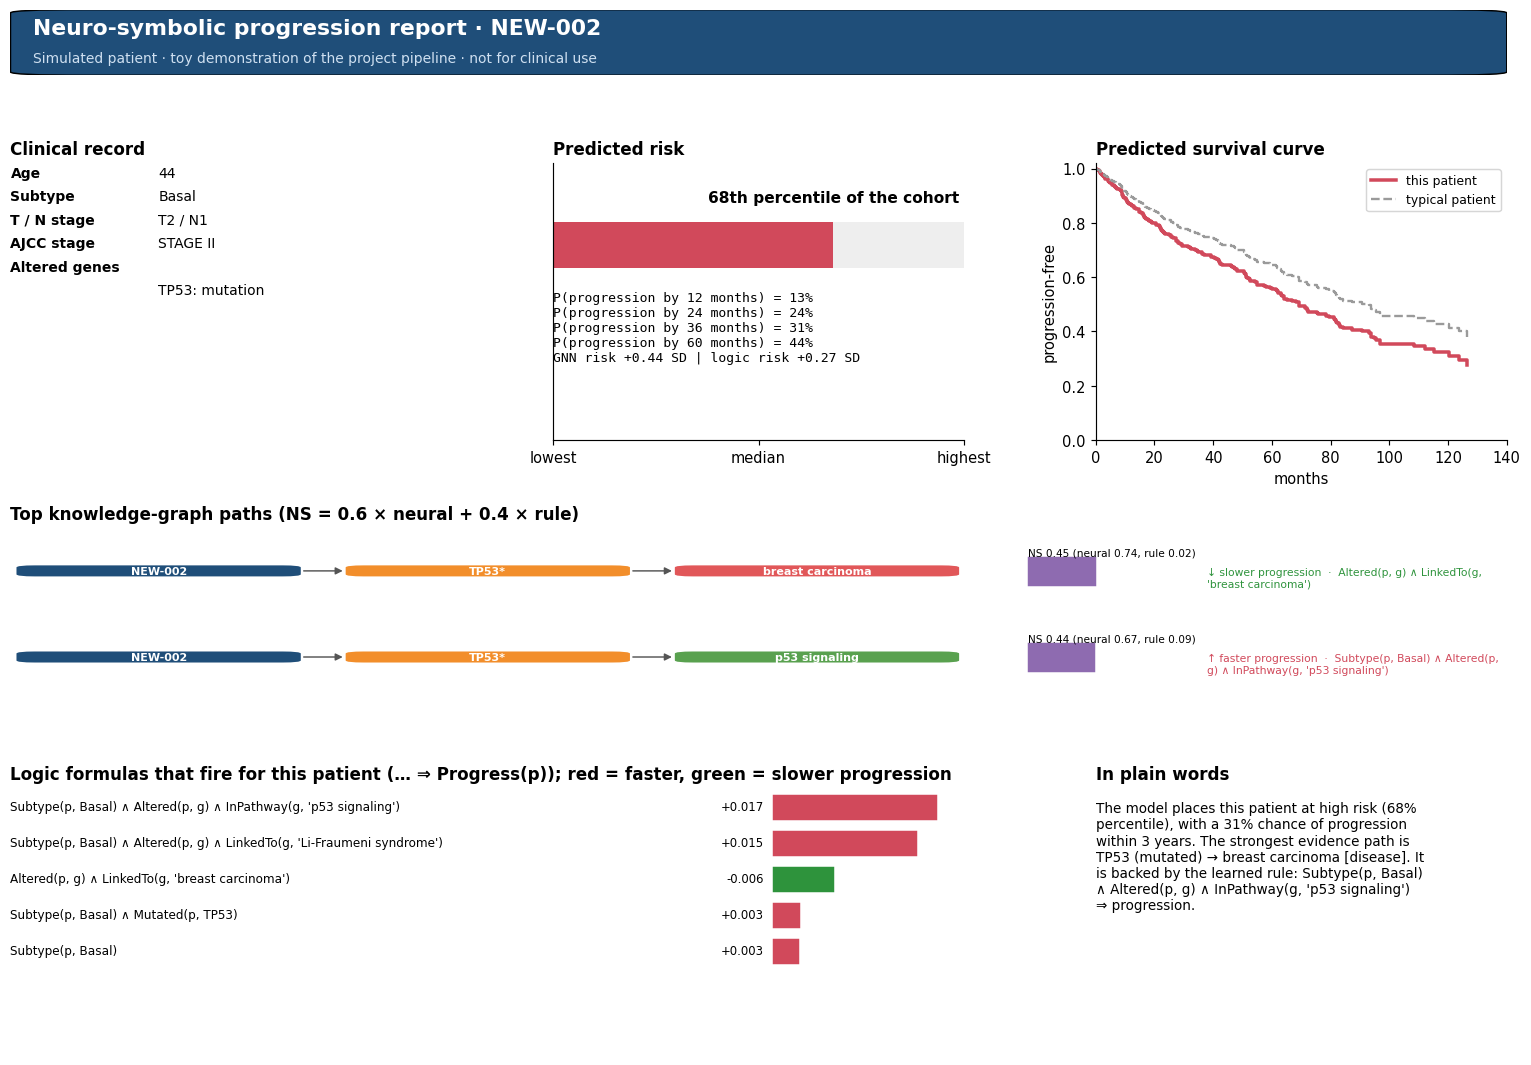

In [43]:
# Same patient, but without the cell-cycle (MYC) and DNA-repair (BRCA1) alterations: what changes?
EDITED = dict(NEW_PATIENT, id="NEW-002", mutations=["TP53"], amplifications=[])
report_card(analyse_new_patient(EDITED))

---
# 🏁 Summary: what this notebook showed

| Step | What happened here | In the real project |
|---|---|---|
| 1 · Data | 500 simulated patients, cBioPortal-style clinical / MAF / CNA tables, outcome split off | 1,083 TCGA BRCA patients (145 progressions), checksummed cBioPortal files |
| 2 · Patient graph | Patient → Sample → altered Gene (`MultiDiGraph`) | Same, 500-gene panel with 27 known drivers |
| 3 · PrimeKG | Hand-written mini PrimeKG (24 genes, 9 pathways, 10 drugs, 4 diseases) | 4,570-edge slice of PrimeKG (129,375 nodes, ~8.1 M edges) |
| 4 · Fusion | Join on Entrez id, 2 hops | Same (`fixed_hops: 2`) |
| 5 · Neural | 3-layer relational GNN, Cox loss, GNNExplainer | GCN / GraphSAGE / R-GCN / GAT / GIN / transformer; GraphSAGE + C-index loss kept |
| 6 · Symbolic | Ground atoms incl. relational PrimeKG atoms, RL rule search, survival MLN | 422 atoms; MLN, PSL, RL rules, RL-structured MLN vs RuleKit baseline |
| 7 · Fusion | Cox on clinical + GNN + logic, cross-validated stacking | Same; chosen by the one-standard-error rule |
| 8 · Explanation | Paths scored `0.6 × neural + 0.4 × rule`, report card | Same, plus month-of-progression estimate and 1,083 PDF reports in groups A–D, N |

**The neuro-symbolic claim, demonstrated step by step:**

1. 🧠 The **neural** model reads the fused knowledge graph and predicts, but on its own it only says *where* it looked.
2. 📜 The **symbolic** engine reasons over first-order facts, including **relational PrimeKG atoms**. RL proposes the formulas and the Cox likelihood weighs them. It rediscovered the hidden mechanism as readable, weighted rules.
3. 🤝 **Fusion** combines both into one survival risk.
4. 🔍 The **explanation** ties the two together: each path is concrete evidence from the patient's own graph (neural) and an instance of a validated, weighted rule (symbolic).

**Real-project results to remember** (out-of-fold, 5 folds):
* Neuro-symbolic Cox C-index **0.664 ± 0.021**, tied with clinical Cox **0.675 ± 0.035**: every model family saturates near 0.67 with 145 events.
* **69%** of the logic engine's formulas use a PrimeKG relation, against **10%** of RuleKit's IF-THEN rules.
* The month-of-progression estimate is within 12 months for **48%** of progressors, against 37% for a constant guess.

On real data, the neural and symbolic layers add **explanation rather than accuracy**, and that explanation is the deliverable.

### 📖 Glossary
* **Censored**: the patient's follow-up ended before any progression was seen; we know only that they were progression-free *until* then.
* **C-index**: share of comparable patient pairs ranked in the right order by the model (0.5 = random).
* **Hazard ratio**: how much a factor multiplies the instantaneous risk of progression (> 1 raises it).
* **Ground atom**: a logic fact about one patient, e.g. `Mutated(p, TP53)`.
* **Markov logic network**: a set of first-order formulas, each with a weight; more true groundings of a positive-weight formula ⇒ higher probability.
* **REINFORCE**: a policy-gradient reinforcement-learning algorithm: sample actions, reward the good ones, update the policy.
* **GNNExplainer**: learns a sparse mask over a graph's edges that preserves the GNN's prediction, showing which edges mattered.